# CNN 파일별 2 · 02 이미지분류 Day01 실습 — 이미지를 이해하고 첫 결과 읽기

**한 줄 요약**

- CIFAR-10 1000장으로 작은 CNN의 **첫 결과를 기준선과 비교**하고, 사진이 **숫자 배열 → 배치 텐서**가 되는 과정
- 크기와 값 범위 맞추기 · 커널 처리
- 증강과 나누는 순서까지 따라감

- **원본** · `7. 딥러닝/02_CNN_이미지분류/실습/02_이미지분류_Day01.ipynb (47셀 · 0 ~ 11장)` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/07_CNN` CNN-1 (합성곱 · 크기 계산) · 이 실습의 강의는 `CNN_파일별 1`

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 입력 · 정답 · 예측과 **기준선**을 정하고, 첫 학습 결과를 기준선과 비교해 읽는다
2. 사진 한 장을 **HWC 배열 → CHW 텐서 → NCHW 배치**로 바꾸고 `to_tensor`의 세 단계를 설명한다
3. 크기 맞추기(늘리기 · 자르기 · 비율)와 값 범위 맞추기(0–1 · 정규화)가 **무엇을 남기고 지우는지** 말한다
4. 커널 하나로 흐리기 · 경계 · 또렷하게가 되는 이유를 **아홉 칸 합**으로 설명한다
5. 증강을 **허용 · 제외**로 고르고, 나누기 → 증강 순서와 학습 무작위 · 검증 고정을 지킨다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **새 이미지 데이터를 받았을 때** · 크기 · 장수 · 겹침 탐색 기록 (8장)
- **모델 점수가 이상하게 낮을 때** · 축 순서 · 값 범위 · 배치 축 · 에러 메시지 읽기 (4 · 6장)
- **사진 크기가 제각각일 때** · Resize · CenterCrop · 비율 (5장)
- **증강을 고르고 효과를 확인할 때** · 허용 · 제외 · 나누는 순서 · 한 조건 비교 (8 · 9 · 10장)

## 학습 지도

<img src="images/pfcnn2_map.png" alt="02_이미지분류_Day01 학습 지도" width="800">

**예상 학습 시간** · 개념 1시간 30분 + 실습 30분 (전체 실행 CPU 1분 안팎 · GPU 필요 없음)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>데이터 · 고정 부분집합 · 그림 함수</td></tr>
<tr><td>1</td><td>무엇을 맞히는 문제인가 · 가장 단순한 기준</td><td>입력 · 정답 · 예측은 각각 무엇이고, 아무것도 배우지 않은 기준은 몇 %인가?</td></tr>
<tr><td>2</td><td>작은 CNN을 짧게 학습</td><td>작은 CNN을 3번만 학습해도 기준선을 넘는가, 어떤 사진을 틀리는가?</td></tr>
<tr><td>3</td><td>사진은 숫자 배열</td><td>사진 한 장은 어떤 숫자로 되어 있고, 숫자를 바꾸면 사진이 어떻게 바뀌는가?</td></tr>
<tr><td>4</td><td>배열에서 배치 텐서까지</td><td>사진 배열을 모델이 받는 배치 텐서로 바꾸려면 무엇을 맞춰야 하는가?</td></tr>
<tr><td>5</td><td>화면에서 크게 본 그 그림의 실제 크기</td><td>크기를 맞출 때 무엇이 남고 무엇이 사라지는가?</td></tr>
<tr><td>6</td><td>값의 범위 맞추기</td><td>0 ~ 255 값을 0 ~ 1로 줄이고 평균 · 표준편차로 옮기면 값은 어떻게 바뀌는가?</td></tr>
<tr><td>7</td><td>이미지 처리는 무엇을 남기고 지우는가</td><td>커널 하나로 흐리기 · 경계 찾기 · 또렷하게를 할 수 있는 이유는 무엇인가?</td></tr>
<tr><td>8</td><td>어떤 데이터를 학습과 평가에 쓰는가</td><td>학습 전에 데이터에서 무엇을 기록하고, 증강과 나누기는 어떤 순서로 해야 하는가?</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>9</td><td>바꿔도 정답이 같은 이미지인가</td><td>어떤 변환은 허용하고 어떤 변환은 빼야 하며, 학습과 검증은 어떻게 다르게 처리하는가?</td></tr>
<tr><td>10</td><td>첫 실험을 다시 설명하기</td><td>첫 실험을 데이터 → 입력 → 예측 한 줄로 설명하고, 전처리 하나만 바꾸면 결과가 어떻게 되는가?</td></tr>
<tr><td>11</td><td>종합 실습</td><td>오늘 배운 입력 약속으로 새 사진을 예측하고, 이미지 처리 하나가 점수를 얼마나 바꾸는지 잴 수 있는가?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

- **셀은 위에서부터 차례로 실행** · 원본 0장과 같은 준비를 두 셀로 나눔
- 데이터는 `data/` 폴더의 CIFAR-10 (없으면 내려받음 · 약 170MB)
- 종류마다 학습 100 · 검증 50장 고정 부분집합 → CPU로도 1분 안에 끝남

*항목 → 설정*

- **데이터** · CIFAR-10 학습 파일 · 종류마다 학습 100 · 검증 50 (번호로 나눠 겹침 없음)
- **seed** · `torch.manual_seed(42)` · `np.random.seed(42)` (원본과 같음)
- **모델** · 합성곱 2 · MaxPool 2 · Linear · Adam 0.001 · 3에폭
- **원본과 다른 점** · 학습 시간 출력 → '1분 안에 끝났나'로 (실행마다 같은 출력)
- **SHOW** · 채널 차이가 가장 뚜렷한 학습 사진 한 장 · 하루 내내 따라다님

**실행 흐름**

1. 도구 · 데이터셋 불러오기 · OpenMP · 보간 방법 설정
2. CIFAR10 내려받기(처음 한 번) · 학습 · 검증 번호 나누기

In [1]:
# 왜 · OpenMP 설정과 학습 시간 재기에 쓸 도구를 먼저 불러오기 위해
import os    # 환경 변수
import time  # 학습 시간 재기

# 왜 · 사진을 숫자 · 그림으로 함께 확인하기 위해
import matplotlib.pyplot as plt                       # 그림
import numpy as np                                    # 배열
import torch                                          # 텐서 · 모델
import torch.nn as nn                                 # 층
import torchvision.transforms.functional as TF        # PIL 사진 변환 함수
from torchvision.datasets import CIFAR10              # 사진 10종
from torchvision.transforms import InterpolationMode  # 크기 바꿀 때 채우는 방법

# 왜 · torch와 matplotlib을 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # torch · matplotlib OpenMP 충돌 방지
NEAREST = InterpolationMode.NEAREST                                       # 가장 가까운 칸을 복사
BILINEAR = InterpolationMode.BILINEAR                                     # 이웃 칸을 섞어 채움
plt.rcParams.update({"font.family": "Malgun Gothic", "font.size": 10,     # 그림 글꼴 10pt
                     "axes.titlesize": 12, "axes.unicode_minus": False})  # 제목 12pt
torch.manual_seed(42)                                                     # 원본과 같은 seed
np.random.seed(42)                                                        # numpy 난수도 고정

# 왜 · 처음 한 번만 내려받고 그다음부터는 data/에 저장된 파일을 그대로 쓰기 위해
raw = CIFAR10(root="data", train=True, download=True)          # 학습 파일 5만 장 (PIL 사진 · 정답)
CLASSES = raw.classes                                          # 종류 이름 10개
targets = np.array(raw.targets)                                # 정답 번호 배열
PER_TRAIN, PER_VAL = 100, 50                                   # 종류마다 학습 100 · 검증 50
tr_idx, va_idx = [], []                                        # 고정 부분집합 번호
for c in range(len(CLASSES)):                                  # 종류마다
    where = np.where(targets == c)[0]                          # 그 종류의 번호
    tr_idx += list(where[:PER_TRAIN])                          # 앞 100장 → 학습
    va_idx += list(where[PER_TRAIN:PER_TRAIN + PER_VAL])       # 다음 50장 → 검증 (겹치지 않음)
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)            # 배열로
PICK = [int(np.where(targets == c)[0][0]) for c in (8, 1, 6)]  # 6장 퀴즈용 (배 · 자동차 · 개구리)
print(f"학습 {len(tr_idx)}장 · 검증 {len(va_idx)}장 · 종류 {len(CLASSES)}개")  # 부분집합 크기

학습 1000장 · 검증 500장 · 종류 10개


**실행 흐름**

1. 색 개수 함수 정의
2. 하루 내내 따라다닐 사진 한 장 고르기
3. 사진 격자 함수 정의

In [2]:
# 왜 · 사진마다 색이 얼마나 다양한지 숫자로 재기 위해
def n_colors(im):                                               # 사진 안의 서로 다른 색 개수
    return len(np.unique(np.array(im).reshape(-1, 3), axis=0))  # (칸 수, 3)에서 겹치지 않는 줄


# 왜 · 하루 내내 따라다닐 사진을 채널 차이가 뚜렷한 한 장으로 고르기 위해
_cand = tr_idx[:300]  # 하루 내내 따라다닐 한 장 후보
_tilt = [np.array(raw[int(i)][0], dtype=float).reshape(-1, 3).mean(0) for i in _cand]  # 채널 평균
SHOW = int(_cand[int(np.argmax([t.max() - t.min() for t in _tilt]))])  # 채널 차이가 가장 뚜렷한 장


# 왜 · 작은 사진도 칸이 보이게 최근접으로 크게 그려 나란히 비교하기 위해
def grid(images, titles, rows=1):                # 작은 사진도 칸이 보이게 최근접으로 크게 그림
    n = len(images)                              # 사진 수
    cols = (n + rows - 1) // rows                # 한 줄 칸 수
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.9 * rows))  # 격자
    axes = np.atleast_1d(axes).ravel()           # 한 줄로 펴기
    for ax in axes:                              # 모든 칸
        ax.axis("off")                           # 눈금 끄기
    for ax, im, t in zip(axes, images, titles):  # 사진 · 제목 짝
        a = np.array(im)                         # PIL · 배열 모두 배열로
        ax.imshow(a, cmap="gray" if a.ndim == 2 else None, interpolation="nearest")  # 흑백이면 회색
        ax.set_title(t, fontsize=10)             # 제목 10pt
    fig.tight_layout()                           # 겹침 정리
    plt.show()                                   # 그리기


print(f"따라다닐 한 장 SHOW = {SHOW}번 · 정답 {CLASSES[targets[SHOW]]}")  # 고른 사진

따라다닐 한 장 SHOW = 779번 · 정답 bird


### 원본 목표

- 1일차 · 이미지를 이해하고 첫 결과를 읽기
- 이미지가 모델에 들어갈 입력이 되는 과정을 따라감
- 첫 예측을 단순 기준과 비교함

**원본 힌트**

- 각 장 제목 아래 원본의 한 줄 설명 · 예: 입력 · 정답 · 예측을 먼저 정함
- 그림은 작은 사진도 칸이 보이게 최근접으로만 그림

---
## 1. 무엇을 맞히는 문제인가 · 가장 단순한 기준

> **이 장의 흐름**
>
> - 종류마다 한 장씩 보며 입력 · 정답 · 예측을 정함
> - 그다음 한 이름만 계속 답할 때의 정확도(기준선)

<img src="images/pfcnn2_ch1.png" alt="입력 · 정답 · 예측과 기준선" width="577">

**파이프라인 위치** · ① 문제 정하기

### 1-1. `A` 입력 · 정답 · 예측 · `CIFAR10` · `raw.classes` <sub>원본 1장</sub>

> 🎯 **이 실습에서 모델은 무엇을 받아 무엇을 내놓는가?**

💡 **쉽게 말하면**

- 입력은 **사진 한 장**, 정답과 예측은 **열 개 이름 중 하나**.
- 문제를 먼저 정해야 점수의 뜻이 정해짐.

**실행 흐름**

1. 종류마다 첫 장 번호 찾기
2. 열 장을 두 줄로 그리기
3. 입력 · 정답 · 예측 한 줄 요약

**먼저 예측** · 정답 이름은 몇 개 중 하나일까? — 답은 코드 실행 결과 아래에

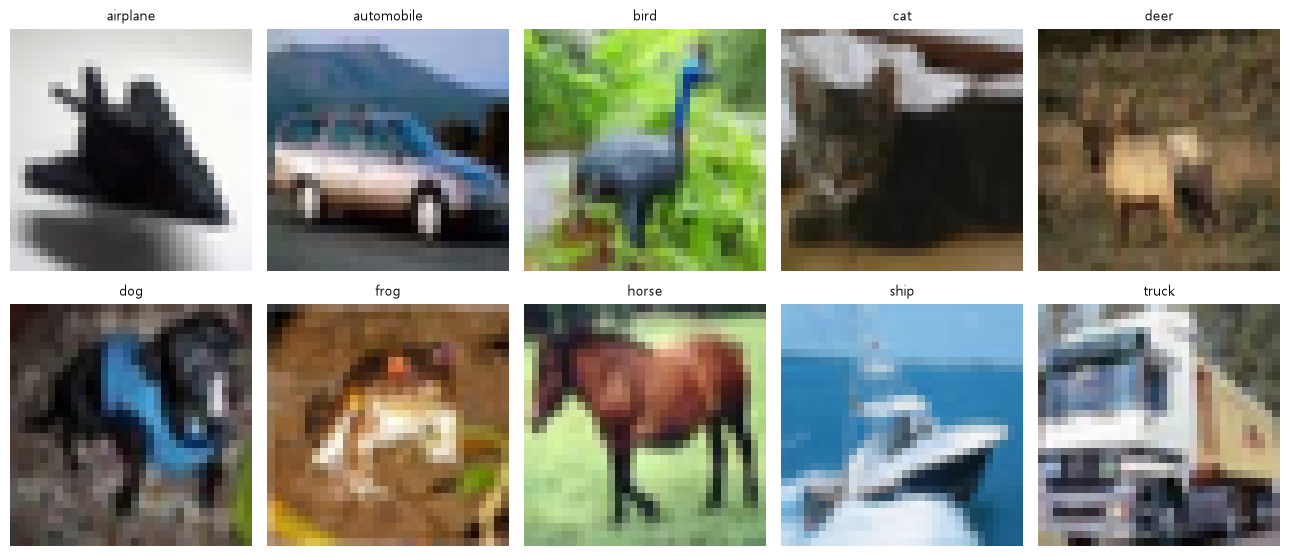

입력 사진 한 장 · 정답 10개 이름 중 하나 · 예측도 같은 10개 중 하나


In [3]:
# 왜 · 종류마다 첫 사진을 보며 무엇을 맞히는 문제인지 먼저 이해하기 위해
one_per_class = [int(np.where(targets == c)[0][0]) for c in range(len(CLASSES))]  # 종류마다 첫 장
grid([raw[i][0] for i in one_per_class], CLASSES, rows=2)                         # 열 종류 한 장씩
print(f"입력 사진 한 장 · 정답 {len(CLASSES)}개 이름 중 하나 · "                  # 문제 정의 한 줄
      f"예측도 같은 {len(CLASSES)}개 중 하나")

**결과** · 예측 정답은 10개

- `입력 사진 한 장 · 정답 10개 이름 중 하나 · 예측도 같은 10개 중 하나` — 열 종류 분류 문제
- 그림 · 비행기부터 트럭까지 열 종류 · 32 × 32 작은 컬러 사진

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류</td><td>이름 하나</td><td>이 실습</td></tr>
<tr><td>탐지</td><td>이름 + 위치(상자)</td><td>한 사진에 여러 대상 (다음 과목)</td></tr>
<tr><td>분할</td><td>칸마다 이름</td><td>모양까지 필요할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정답이 하나뿐인 문제 · 한 사진에 두 대상이 있어도 답은 하나
> - `raw.classes` 순서가 곧 정답 번호 (0 = airplane)

> ✅ **한 줄 정리** · 이 실습은 사진 한 장을 받아 열 개 이름 중 하나를 고르는 분류 문제다.

**딥러닝 코드에서는**

- `dataset.classes` — 번호 ↔ 이름 표를 늘 곁에 둠
- 마지막 Linear의 출력 수 = 종류 수 (10)

### 1-2. `A` 가장 단순한 기준 (기준선) · `np.bincount` · `argmax` <sub>원본 2장</sub>

> 🎯 **아무것도 학습하지 않고 한 이름만 계속 답하면 정확도는 몇 %인가?**

💡 **쉽게 말하면**

- 기준선 = **가장 많은 종류만 계속 답할 때**의 정확도.
- 모델 점수는 늘 기준선과 비교해서 읽음.

**실행 흐름**

1. 검증 정답의 종류별 장수
2. 가장 많은 종류 하나만 답할 때 정확도
3. 아무 이름이나 고를 때 기대 정확도

**먼저 예측** · 종류마다 50장씩이면 기준선은? — 답은 코드 실행 결과 아래에

In [4]:
# 왜 · 가장 많은 종류만 찍어도 몇 %인지 기준선을 정하기 위해
va_y = targets[va_idx]                                                 # 검증 정답
counts = np.bincount(va_y, minlength=len(CLASSES))                     # 종류별 장수
top = int(counts.argmax())                                             # 가장 많은 종류
const_acc = counts[top] / len(va_y)                                    # 그 이름만 계속 답할 때
print("검증 종류별 장수 " + " · ".join(f"{n}:{c}" for n, c in zip(CLASSES, counts)))  # 고름
print(f"한 이름만 계속 답할 때 정확도 {const_acc * 100:.1f}% · 어느 이름을 골라도 같음")  # 기준선
print(f"아무 이름이나 고를 때 기대 정확도 {100 / len(CLASSES):.1f}%")  # 무작위 기준

검증 종류별 장수 airplane:50 · automobile:50 · bird:50 · cat:50 · deer:50 · dog:50 · frog:50 · horse:50 · ship:50 · truck:50
한 이름만 계속 답할 때 정확도 10.0% · 어느 이름을 골라도 같음
아무 이름이나 고를 때 기대 정확도 10.0%


**결과** · 예측 정답은 10.0% — 어느 이름을 골라도 같음

- `airplane:50 · automobile:50` — 종류마다 50장 · 고르게 나눔
- `한 이름만 계속 답할 때 정확도 10.0%` — 고르면 기준선 = 1 ÷ 종류 수
- `아무 이름이나 고를 때 기대 정확도 10.0%` — 무작위로 찍어도 같은 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>한 이름만 답하기</td><td>가장 많은 종류의 비율</td><td>불균형 데이터의 기준</td></tr>
<tr><td>무작위 찍기</td><td>1 ÷ 종류 수</td><td>고른 데이터의 기준</td></tr>
<tr><td>모델 점수</td><td>기준선보다 얼마나 높은가</td><td>학습 효과를 말할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 불균형 데이터에서는 한 이름만 답해도 기준선이 높음
> - 검증 정답으로 센 기준 · 학습 데이터 분포와 다를 수 있음

> ✅ **한 줄 정리** · 기준선은 아무것도 배우지 않은 점수이며, 종류가 고르면 열 종류 문제의 기준선은 10%다.

**딥러닝 코드에서는**

- `torch.bincount(y)` — 학습 전에 늘 장수부터
- 정확도 90%도 기준선이 90%면 아무것도 안 배운 것

---
## 2. 작은 CNN을 짧게 학습

> **이 장의 흐름**
>
> - 사진을 텐서 묶음으로 · 모델 · 학습 전 정확도
> - 그다음 3에폭 학습 → 틀린 사진 보기

<img src="images/pfcnn2_ch2.png" alt="작은 CNN과 학습 한 바퀴" width="584">

**파이프라인 위치** · ② 첫 결과 얻기

### 2-1. `A` 텐서 묶음 · 모델 · 학습 전 정확도 · `TF.to_tensor` · `torch.stack` · `nn.Sequential` <sub>원본 3장</sub>

> 🎯 **사진 1000장은 어떤 모양의 묶음이 되고, 학습 전 모델은 몇 %를 맞히는가?**

💡 **쉽게 말하면**

- 사진마다 `to_tensor`로 바꿔 **쌓으면** (장수, 채널, 세로, 가로) 묶음.
- 학습 전 모델은 아무렇게나 찍는 것과 비슷.

**실행 흐름**

1. 번호 → 사진 묶음 · 정답 함수
2. 학습 1000 · 검증 500 묶음
3. 합성곱 2 · 줄이기 2 · Linear 모델
4. 학습 전 정확도

**먼저 예측** · 학습 전 검증 정확도는 기준선 10% 근처일까? — 답은 코드 실행 결과 아래에

In [5]:
# 왜 · 여러 장을 모델이 받는 (N, C, H, W) 텐서 묶음으로 바꾸기 위해
def to_tensor(idx):                                   # 번호 목록 → 사진 묶음 텐서 · 정답 텐서
    X = torch.stack([TF.to_tensor(raw[int(i)][0]) for i in idx])  # (N, 3, 32, 32) · 0~1
    y = torch.tensor(targets[idx], dtype=torch.long)  # 정답 번호
    return X, y                                       # 묶음 · 정답


# 왜 · 학습 · 검증 묶음을 한 번만 만들어 두고 뒤에서 다시 쓰기 위해
Xtr, ytr = to_tensor(tr_idx)                                      # 학습 1000장
Xva, yva = to_tensor(va_idx)                                      # 검증 500장
small = nn.Sequential(  # 합성곱 2번 · 줄이기 2번 · 점수 10개
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 → 16
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16 → 8
    nn.Flatten(), nn.Linear(32 * 8 * 8, len(CLASSES)),            # 펴서 점수
)


# 왜 · 모든 비교가 같은 평가 방법을 쓰게 하기 위해
def accuracy(model, X, y):                                      # 학습 없이 정확도만
    model.eval()                                                # 평가 모드
    with torch.no_grad():                                       # 기울기 기록 안 함
        return (model(X).argmax(1) == y).float().mean().item()  # 맞힌 비율


# 왜 · 학습 전 점수를 기록해 학습 효과를 비교할 출발점을 두기 위해
acc0 = accuracy(small, Xva, yva)                                                 # 학습 전
print(f"학습 전 검증 정확도 {acc0 * 100:.1f}%")                                  # 출발점
print(f"입력 묶음 모양 {tuple(Xtr.shape)} · 정답 묶음 모양 {tuple(ytr.shape)}")  # 모양

학습 전 검증 정확도 8.4%
입력 묶음 모양 (1000, 3, 32, 32) · 정답 묶음 모양 (1000,)


**결과** · 예측 정답은 근처 — 8.4%

- `학습 전 검증 정확도 8.4%` — 무작위 시작 숫자 · 10% 안팎
- `입력 묶음 모양 (1000, 3, 32, 32) · 정답 묶음 모양 (1000,)` — 사진 1000장 · 정답 1000개

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>TF.to_tensor(pil)</code></td><td>PIL → (3, H, W) · 0~1</td><td>한 장 변환</td></tr>
<tr><td><code>torch.stack(list)</code></td><td>새 축(장수)으로 쌓음</td><td>묶음 만들기</td></tr>
<tr><td><code>accuracy</code></td><td>평가 모드 · 기울기 없이 맞힌 비율</td><td>학습 전후 비교</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 32 × 8 × 8 = Linear 입력 · 줄이기 두 번으로 32 → 8칸
> - 평가 함수 안에서 `model.eval()` · `no_grad()`를 함께

> ✅ **한 줄 정리** · 사진을 `to_tensor`로 바꿔 쌓으면 (1000, 3, 32, 32) 묶음이 되고, 학습 전 모델은 기준선 근처를 맞힌다.

**딥러닝 코드에서는**

- 실전에서는 `Dataset` · `DataLoader`가 묶음을 만듦
- 학습 전 정확도를 찍어 두면 학습이 효과가 있었는지 바로 보임

### 2-2. `A` 3에폭 학습 · `torch.optim.Adam` · `nn.CrossEntropyLoss` · `randperm` <sub>원본 3장</sub>

> 🎯 **3에폭만 학습해도 검증 정확도는 기준선을 넘는가?**

💡 **쉽게 말하면**

- 에폭 = 학습 사진을 **한 번 다 쓴 것**.
- 묶음마다 예측 → 손실 → 기울기 → 한 걸음.

**실행 흐름**

1. Adam · 손실 함수
2. 에폭마다 섞기 → 32장씩 한 걸음
3. 에폭 끝마다 검증 정확도
4. 기준선과 비교

**먼저 예측** · 3에폭 뒤 검증 정확도는 몇 %쯤일까? — 답은 코드 실행 결과 아래에

In [6]:
# 왜 · 짧은 학습으로도 기준선을 넘는지 확인하기 위해
opt = torch.optim.Adam(small.parameters(), lr=1e-3)                         # 한 걸음 크기 0.001
lossf = nn.CrossEntropyLoss()                                               # 손실 (점수를 받음)
hist = []                                                                   # 에폭별 검증 정확도
t0 = time.time()                                                            # 시작 시각
for ep in range(1, 4):                                                      # 3에폭
    small.train()                                                           # 학습 모드
    perm = torch.randperm(len(Xtr))                                         # 섞기
    for i in range(0, len(Xtr), 32):                                        # 32장씩
        b = perm[i:i + 32]                                                  # 이번 묶음 번호
        opt.zero_grad()                                                     # 지난 기울기 지우기
        lossf(small(Xtr[b]), ytr[b]).backward()                             # 예측 → 손실 → 기울기
        opt.step()                                                          # 한 걸음
    a = accuracy(small, Xva, yva)                                           # 검증
    hist.append(a)                                                          # 기록
    print(f"epoch {ep} 뒤 검증 정확도 {a * 100:.1f}%")                      # 에폭마다
took = time.time() - t0  # 걸린 시간 (원본은 출력 · 실행마다 달라 여기서는 아래 줄만)
print(f"3에폭 학습 끝 · 1분 안에 끝났나 {took < 60}")                       # CPU에서도 1분이면 충분
print(f"단순 기준 {const_acc * 100:.1f}% · 학습 뒤 {hist[-1] * 100:.1f}%")  # 기준선과 비교

epoch 1 뒤 검증 정확도 22.0%


epoch 2 뒤 검증 정확도 28.4%


epoch 3 뒤 검증 정확도 32.4%
3에폭 학습 끝 · 1분 안에 끝났나 True
단순 기준 10.0% · 학습 뒤 32.4%


**결과** · 예측 정답은 32.4% — 기준선의 세 배

- `epoch 1 뒤 검증 정확도 22.0%` — 한 번 만에 기준선을 넘음
- `epoch 3 뒤 검증 정확도 32.4%` — 에폭마다 오름
- `3에폭 학습 끝 · 1분 안에 끝났나 True` — 원본은 걸린 시간을 출력 · 실행마다 달라 참 · 거짓으로만
- `단순 기준 10.0% · 학습 뒤 32.4%` — 점수는 기준선과 나란히

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>에폭</td><td>학습 사진 한 바퀴</td><td>학습 길이 단위</td></tr>
<tr><td>묶음 32</td><td>한 걸음에 쓰는 사진 수</td><td>메모리 · 속도에 맞춤</td></tr>
<tr><td>학습률 0.001</td><td>한 걸음의 크기</td><td>Adam 기본값</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 1000장 · 3에폭은 아주 짧은 학습 · 점수보다 흐름을 봄
> - `opt.zero_grad()`를 빼면 기울기가 쌓임

> ✅ **한 줄 정리** · 작은 CNN을 3에폭만 학습해도 검증 정확도가 10%에서 32.4%로 올라 기준선을 크게 넘는다.

**딥러닝 코드에서는**

- `for epoch: for x, y in loader: zero_grad → loss → backward → step` — 학습 코드의 뼈대
- 에폭마다 검증 점수를 기록하면 학습 곡선이 됨

### 2-3. `B` 틀린 사진 보기 · `nonzero()` · `set` <sub>원본 3장</sub>

> 🎯 **점수 대신 틀린 사진을 직접 보면 무엇이 보이는가?**

💡 **쉽게 말하면**

- 검증셋이 종류 순서라 **앞에서만 뽑으면 한 종류만** 나옴.
- 그래서 종류마다 한 장씩 고름.

**실행 흐름**

1. 검증 답 구하기
2. 틀린 사진 중 정답 종류가 겹치지 않게 네 장
3. 정답 · 답과 함께 그리기
4. 틀린 장수

**먼저 예측** · 500장 중 몇 장을 틀렸을까? — 답은 코드 실행 결과 아래에

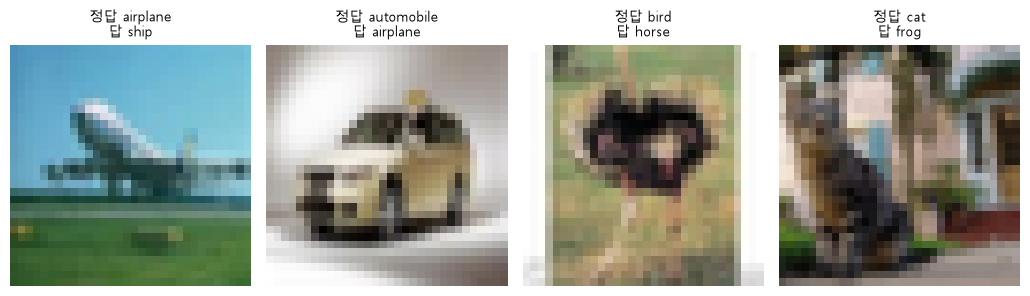

틀린 장수 338 / 500


In [7]:
small.eval()                                                 # 평가 모드
with torch.no_grad():                                        # 기울기 없음
    pred = small(Xva).argmax(1)                              # 검증 답
# 왜 · 틀린 사진을 정답 종류마다 한 장씩만 골라 다양한 실수를 보기 위해
bad, seen = [], set()                                        # 틀린 사진 · 이미 고른 정답 종류
for i in (pred != yva).nonzero().ravel().tolist():           # 틀린 사진 번호 (검증셋이 종류 순)
    if int(yva[i]) not in seen:                              # 종류마다 한 장만
        bad.append(i)                                        # 고름
        seen.add(int(yva[i]))                                # 그 종류 표시
    if len(bad) == 4:                                        # 네 장이면
        break                                                # 끝
grid([raw[int(va_idx[i])][0] for i in bad],                  # 틀린 네 장
     [f"정답 {CLASSES[yva[i]]}\n답 {CLASSES[pred[i]]}" for i in bad])
print(f"틀린 장수 {int((pred != yva).sum())} / {len(yva)}")  # 전체 틀림

**결과** · 예측 정답은 338장 — 정확도 32.4%의 나머지

- `틀린 장수 338 / 500` — 나머지가 맞힌 사진 → 정확도 32.4%
- 그림 · 정답과 답을 함께 보면 비슷한 색 · 모양끼리 헷갈린 경우가 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정확도 숫자</td><td>몇 %인지</td><td>한 줄 성적</td></tr>
<tr><td>틀린 사진 목록</td><td>어떻게 틀렸는지</td><td>다음 실험의 방향</td></tr>
<tr><td>종류마다 한 장</td><td>골고루 보기</td><td>정렬된 데이터를 볼 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정렬된 데이터에서 앞부분만 보면 한 종류만 보임
> - 네 장은 예시 · 경향은 전체를 세어서 말함

> ✅ **한 줄 정리** · 틀린 사진을 종류마다 한 장씩 꺼내 보면 숫자로는 안 보이는 헷갈림의 모습이 보인다.

**딥러닝 코드에서는**

- 오류 분석은 늘 '틀린 사진 보기'부터
- 혼동행렬로 틀림을 짝으로 세는 것이 다음 단계 (파일별 1의 6장)

---
## 3. 사진은 숫자 배열

> **이 장의 흐름**
>
> - 크기 · 값 · 숫자 개수 → 채널 나눠 보기 → 회색조 · HSV
> - 그다음 밝기 · 색 바꾸기 → 해상도 줄이기

<img src="images/pfcnn2_ch3.png" alt="사진 = 세로 × 가로 × 채널 숫자" width="584">

**파이프라인 위치** · ③ 입력 이해 — 사진의 숫자

### 3-1. `A` 한 장의 크기와 값 · `np.array(img)` · `arr.shape` · `uint8` <sub>원본 4장</sub>

> 🎯 **32×32 컬러 사진 한 장에는 숫자가 몇 개 있고, 값은 어떤 범위인가?**

💡 **쉽게 말하면**

- 칸(픽셀) 하나 = **빨강 · 초록 · 파랑 숫자 세 개**.
- 값은 0(그 색 없음) ~ 255(가장 밝음) 정수.

**실행 흐름**

1. PIL 사진 → 넘파이 배열
2. 크기 · 채널 · 정답
3. 왼쪽 위 3 × 3 칸의 빨강 값
4. 값 타입 · 범위 · 숫자 개수

**먼저 예측** · 한 장에 숫자는 몇 개일까? — 답은 코드 실행 결과 아래에

In [8]:
# 왜 · 사진 한 장이 실제로는 숫자 배열이라는 것을 모양 · 값으로 확인하기 위해
img = raw[SHOW][0]                                    # 따라다닐 한 장 (PIL)
arr = np.array(img)                                   # (H, W, C) 배열
print(f"한 장 크기 {arr.shape[0]}×{arr.shape[1]} · "  # 세로 · 가로 · 채널 · 정답
      f"채널 {arr.shape[2]} · 정답 {CLASSES[targets[SHOW]]}")
print(f"왼쪽 위 3×3 칸의 빨강 값\n{arr[:3, :3, 0]}")  # 빨강 채널 일부
print(f"값 타입 {arr.dtype} · 가장 작은 값 {arr.min()} · 가장 큰 값 {arr.max()}")  # uint8 0~255
print(f"한 장에 들어 있는 숫자 {arr.size}개")         # 32 × 32 × 3

한 장 크기 32×32 · 채널 3 · 정답 bird
왼쪽 위 3×3 칸의 빨강 값
[[159 159 145]
 [167 162 153]
 [168 167 169]]
값 타입 uint8 · 가장 작은 값 0 · 가장 큰 값 191
한 장에 들어 있는 숫자 3072개


**결과** · 예측 정답은 3072개 — 32 × 32 × 3

- `한 장 크기 32×32 · 채널 3 · 정답 bird` — 세로 · 가로 · 채널 순서 (H, W, C)
- `[[159 159 145]` — 빨강 채널 왼쪽 위 칸들 · uint8 정수
- `값 타입 uint8 · 가장 작은 값 0 · 가장 큰 값 191` — 이 사진은 가장 밝은 칸도 191
- `한 장에 들어 있는 숫자 3072개` — 32 × 32 × 3 = 3072

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>uint8</td><td>0 ~ 255 정수 · 1바이트</td><td>사진 파일 · PIL</td></tr>
<tr><td>float32</td><td>실수 · 4바이트</td><td>모델 입력</td></tr>
<tr><td>(H, W, C)</td><td>채널이 뒤</td><td>넘파이 · PIL · matplotlib</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - uint8에 더하기를 하면 255를 넘을 때 값이 돌아감 → int16으로 바꿔 계산 (3-4)
> - 사진마다 최댓값이 다름 · 늘 255까지 쓰는 것은 아님

> ✅ **한 줄 정리** · 32×32 컬러 사진은 칸마다 RGB 숫자 세 개, 모두 3072개의 0 ~ 255 정수로 되어 있다.

**딥러닝 코드에서는**

- `np.array(Image.open(path))` — 사진 파일을 숫자로 여는 첫 줄
- ImageNet 크기 224 × 224 × 3 = 150528개 숫자

### 3-2. `B` 채널 나눠 보기 · `arr[:, :, 1:] = 0` · `mean()` <sub>원본 4장</sub>

> 🎯 **빨강 · 초록 · 파랑 채널을 따로 보면 이 사진은 어떤 색이 많은가?**

💡 **쉽게 말하면**

- 다른 두 채널을 0으로 끄면 **한 채널만** 보임.
- 채널별 평균으로 어떤 색이 많은지 숫자로 봄.

**실행 흐름**

1. 복사본 셋에서 두 채널씩 끄기
2. 원본 · 빨강 · 초록 · 파랑 네 장
3. 채널별 평균

**먼저 예측** · 새 사진(SHOW)에서 가장 약한 채널은? — 답은 코드 실행 결과 아래에

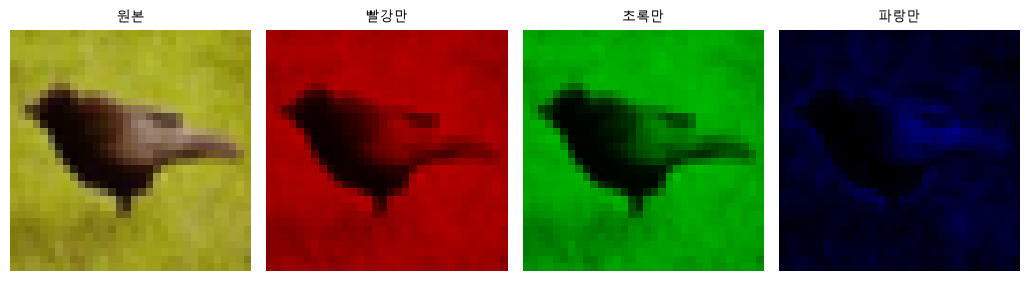

채널별 평균 밝기 — R 140.6 · G 135.0 · B 36.8


In [9]:
# 왜 · 원본을 지키면서 채널 하나만 남겨 색 정보를 나눠 보기 위해
r = arr.copy()                                                # 빨강만 남길 복사본
r[:, :, 1:] = 0                                               # 초록 · 파랑 끄기
g = arr.copy()                                                # 초록만
g[:, :, [0, 2]] = 0                                           # 빨강 · 파랑 끄기
b = arr.copy()                                                # 파랑만
b[:, :, :2] = 0                                               # 빨강 · 초록 끄기
grid([arr, r, g, b], ["원본", "빨강만", "초록만", "파랑만"])  # 네 장
# 어떤 색이 많은가
print(f"채널별 평균 밝기 — R {arr[:, :, 0].mean():.1f} · G {arr[:, :, 1].mean():.1f}"
      f" · B {arr[:, :, 2].mean():.1f}")

**결과** · 예측 정답은 파랑 — 평균 36.8

- `채널별 평균 밝기 — R 140.6 · G 135.0 · B 36.8` — 파랑이 거의 없는 노란 · 갈색 계열
- 그림 · 파랑만 남긴 칸이 거의 검정

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>arr.copy()</code></td><td>원본을 지키며 바꿈</td><td>실험할 때</td></tr>
<tr><td><code>arr[:, :, k]</code></td><td>채널 하나 (2차원)</td><td>채널별 값 보기</td></tr>
<tr><td>채널별 평균</td><td>색 치우침 숫자 하나</td><td>정규화 값 정할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `copy()` 없이 바꾸면 원본까지 바뀜
> - SHOW는 채널 차이가 가장 뚜렷한 사진으로 고른 것 · 보통 사진은 차이가 작음

> ✅ **한 줄 정리** · 채널을 하나씩 남겨 보고 채널별 평균을 재면 사진에 어떤 색이 많은지 숫자로 알 수 있다.

**딥러닝 코드에서는**

- `x.mean(dim=(0, 2, 3))` — 데이터셋 채널별 평균 (정규화 값)
- 채널 순서(RGB · BGR)가 바뀌면 색이 뒤집힘 (4-2)

### 3-3. `B` 회색조 · HSV · `TF.to_grayscale` · `img.convert('HSV')` <sub>원본 4장</sub>

> 🎯 **같은 사진을 회색조나 HSV로 바꾸면 무엇이 남고 무엇이 사라지는가?**

💡 **쉽게 말하면**

- 회색조 = 밝기만 남김 · **채널이 하나**로 줄어듦.
- HSV = 색상 · 채도 · 명도로 나눠 표현.

**실행 흐름**

1. 회색조 변환
2. HSV 변환 후 색상 · 채도 채널
3. 네 장 그리기
4. 회색조 크기

**먼저 예측** · 회색조 사진의 배열 모양은? — 답은 코드 실행 결과 아래에

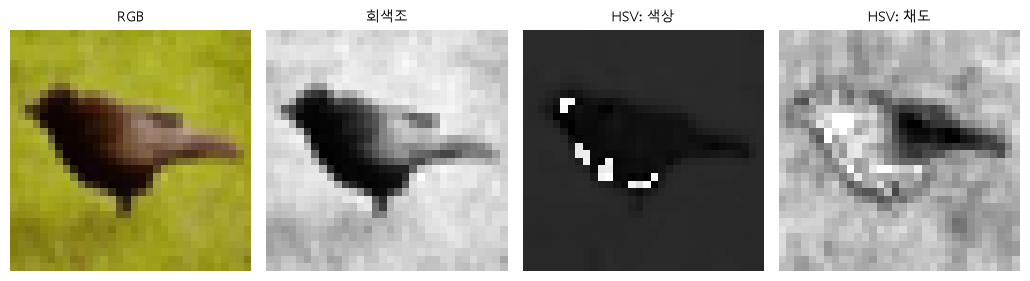

회색조 한 장 크기 (32, 32) · 채널이 사라짐


In [10]:
# 왜 · 회색조 · HSV로 바꾸면 무엇이 남고 무엇이 사라지는지 비교하기 위해
gray = TF.to_grayscale(img)                                         # 회색조 (채널 1)
hsv = np.array(img.convert("HSV"))                                  # 색상 · 채도 · 명도
# 원본 · 회색조 · 색상 · 채도
grid([img, gray, hsv[:, :, 0], hsv[:, :, 1]], ["RGB", "회색조", "HSV: 색상", "HSV: 채도"])
print(f"회색조 한 장 크기 {np.array(gray).shape} · 채널이 사라짐")  # (32, 32)

**결과** · 예측 정답은 (32, 32) — 채널 축이 사라짐

- `회색조 한 장 크기 (32, 32) · 채널이 사라짐` — 밝기 하나만 남음
- 그림 · HSV 색상 칸은 색의 종류, 채도 칸은 색의 진하기

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>RGB</td><td>빨강 · 초록 · 파랑</td><td>모델 기본 입력</td></tr>
<tr><td>회색조</td><td>밝기 하나</td><td>색이 필요 없는 문제 · 계산 절약</td></tr>
<tr><td>HSV</td><td>색상 · 채도 · 명도</td><td>색으로 고르기 · 색 증강</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 회색조로 학습한 모델에 컬러를 넣으면 채널 수가 달라 오류
> - 흑백을 pretrained 모델에 넣을 때는 채널을 3개로 복사

> ✅ **한 줄 정리** · 회색조는 채널을 하나로 줄여 밝기만 남기고, HSV는 같은 색을 색상 · 채도 · 명도로 나눠 보여 준다.

**딥러닝 코드에서는**

- `transforms.Grayscale(num_output_channels=3)` — 흑백을 3채널로
- `ColorJitter(hue=...)` — HSV 쪽을 흔드는 색 증강

### 3-4. `B` 밝기와 색 바꾸기 · `np.clip` · `astype(np.int16)` <sub>원본 4장</sub>

> 🎯 **모든 칸에 같은 수를 더할 때와 한 채널만 키울 때 사진은 어떻게 다른가?**

💡 **쉽게 말하면**

- 모든 칸 +60 → 밝기가 **통째로** 옮겨감.
- 한 채널만 키움 → **색이 기욺**.

**실행 흐름**

1. int16으로 바꿔 +60 · -60 (넘침 방지)
2. 빨강만 ×1.6
3. 0 ~ 255로 자르기
4. 평균 밝기 비교

**먼저 예측** · +60 하면 평균 밝기도 정확히 60 오를까? — 답은 코드 실행 결과 아래에

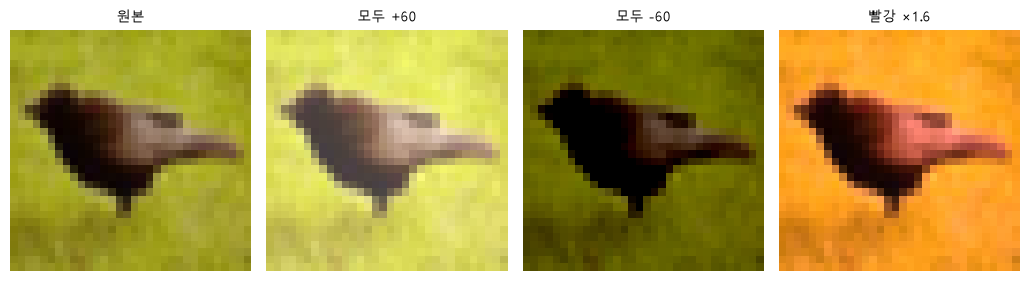

평균 밝기 — 원본 104.1 · 올림 164.1 · 내림 55.2
모든 칸에 같은 수를 더하면 밝기가 통째로 옮겨감 · 한 채널만 키우면 색이 기욺


In [11]:
# 왜 · uint8 넘침을 막으려고 큰 자료형으로 계산한 뒤 0~255로 자르기 위해
bright = np.clip(arr.astype(np.int16) + 60, 0, 255).astype(np.uint8)  # 모든 칸 +60
red_up = arr.copy().astype(np.int16)                                  # 빨강만 키울 복사본
red_up[:, :, 0] = np.clip(red_up[:, :, 0] * 1.6, 0, 255)              # 빨강 ×1.6
half = np.clip(arr.astype(np.int16) - 60, 0, 255).astype(np.uint8)    # 모든 칸 -60
# 네 장 비교
grid([arr, bright, half, red_up.astype(np.uint8)], ["원본", "모두 +60", "모두 -60", "빨강 ×1.6"])
print(f"평균 밝기 — 원본 {arr.mean():.1f} · "                         # +60 · -60 효과
      f"올림 {bright.mean():.1f} · 내림 {half.mean():.1f}")
print("모든 칸에 같은 수를 더하면 밝기가 통째로 옮겨감 · 한 채널만 키우면 색이 기욺")  # 결론

**결과** · 예측 정답은 그렇다 — 104.1 → 164.1 (255를 넘는 칸이 없어서)

- `평균 밝기 — 원본 104.1 · 올림 164.1 · 내림 55.2` — 올림은 정확히 +60 · 내림은 0에서 잘린 칸이 있어 -48.9
- `모든 칸에 같은 수를 더하면 밝기가 통째로 옮겨감` — 모양 · 자리는 그대로 · 값만 바뀜

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>모든 칸 더하기</td><td>밝기 이동</td><td>밝기 증강</td></tr>
<tr><td>채널 하나 곱하기</td><td>색 기울기</td><td>색 증강</td></tr>
<tr><td><code>np.clip(..., 0, 255)</code></td><td>범위 밖 값 자르기</td><td>uint8로 되돌리기 전</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - uint8 그대로 더하면 255를 넘을 때 0부터 다시 시작 (넘침)
> - 자른 칸이 많으면 평균이 정확히 옮겨가지 않음

> ✅ **한 줄 정리** · 모든 칸에 같은 수를 더하면 밝기가 통째로 옮겨가고, 한 채널만 키우면 색이 기울며, 계산은 넘침을 막으려 int16으로 한다.

**딥러닝 코드에서는**

- `TF.adjust_brightness(img, 1.4)` — 밝기 변환 함수
- 모델은 밝기가 바뀐 사진에 약할 수 있음 → 밝기 증강

### 3-5. `B` 해상도 줄이기 · `TF.resize` · `NEAREST` <sub>원본 4장</sub>

> 🎯 **칸 수를 32 → 4로 줄이면 숫자는 얼마나 줄고 사진은 얼마나 알아볼 수 있는가?**

💡 **쉽게 말하면**

- 줄였다가 같은 크기로 **다시 키워** 보여 줌 · 칸 수만 다름.
- 칸이 적을수록 숫자(정보)가 줄어듦.

**실행 흐름**

1. 32 · 16 · 8 · 4칸으로 줄이기
2. 128칸으로 키워 나란히
3. 칸 수별 숫자 개수

**먼저 예측** · 4×4로 줄이면 숫자는 몇 개가 남을까? — 답은 코드 실행 결과 아래에

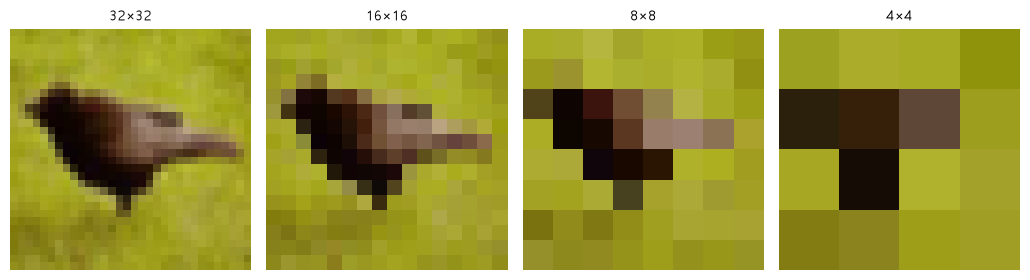

칸 수 32×32=3072개 · 16×16=768개 · 8×8=192개 · 4×4=48개
4×4로 줄이면 숫자가 3072개에서 48개로 줄어듦


In [12]:
# 왜 · 해상도를 줄일 때 어느 크기부터 정보가 사라지는지 보기 위해
steps = [32, 16, 8, 4]                                                    # 줄일 칸 수
shrunk = [TF.resize(TF.resize(img, [k, k], interpolation=NEAREST), [128, 128],  # 줄였다가 크게
                    interpolation=NEAREST) for k in steps]
grid(shrunk, [f"{k}×{k}" for k in steps])                                 # 같은 크기로 보여 줌
print("칸 수 " + " · ".join(f"{k}×{k}={k * k * 3}개" for k in steps))     # 숫자 개수
print(f"4×4로 줄이면 숫자가 {32 * 32 * 3}개에서 {4 * 4 * 3}개로 줄어듦")  # 정보량

**결과** · 예측 정답은 48개 — 4 × 4 × 3

- `4×4로 줄이면 숫자가 3072개에서 48개로 줄어듦` — 64분의 1
- 그림 · 8×8부터는 대상을 알아보기 어려움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>해상도 높음</td><td>숫자 많음 · 세부 남음</td><td>작은 차이를 가를 때</td></tr>
<tr><td>해상도 낮음</td><td>숫자 적음 · 계산량 적음</td><td>대략적인 모양만 필요할 때</td></tr>
<tr><td>NEAREST로 키움</td><td>칸이 그대로 보임</td><td>정보량을 눈으로 비교</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 줄인 뒤 키워도 잃은 세부는 돌아오지 않음
> - 모델 입력 크기를 줄이면 계산은 줄지만 세부 단서도 줄어듦

> ✅ **한 줄 정리** · 해상도를 줄이면 숫자가 제곱으로 줄어 세부가 사라지고, 다시 키워도 잃은 정보는 돌아오지 않는다.

**딥러닝 코드에서는**

- `transforms.Resize(224)` — 모델 입력 크기를 맞추는 첫 변환
- 입력 크기는 정확도 · 계산량의 큰 축

---
## 4. 배열에서 배치 텐서까지

> **이 장의 흐름**
>
> - HWC → CHW → NCHW → 축 · 범위 · 배치를 틀리면
> - 그다음 to_tensor가 하는 세 단계 → 에러 메시지 읽는 순서

<img src="images/pfcnn2_ch4.png" alt="HWC 배열에서 NCHW 텐서까지" width="584">

**파이프라인 위치** · ④ 입력 약속 — 모양 · 값 · 배치

### 4-1. `A` HWC → CHW → NCHW · `TF.to_tensor` · `unsqueeze(0)` <sub>원본 5장</sub>

> 🎯 **넘파이 배열 · 텐서 · 배치는 모양과 값이 어떻게 다른가?**

💡 **쉽게 말하면**

- 사진 파일은 **(H, W, C)**, PyTorch 모델은 **(N, C, H, W)**.
- `to_tensor`가 축을 옮기고 0 ~ 1로 바꾸고, `unsqueeze(0)`가 장수 축을 붙임.

**실행 흐름**

1. 넘파이 HWC
2. to_tensor로 CHW · 0 ~ 1
3. unsqueeze로 NCHW
4. 학습 묶음 한 배치 모양

**먼저 예측** · to_tensor 뒤 값의 최댓값은? — 답은 코드 실행 결과 아래에

In [13]:
# 왜 · 사진 배열(HWC)이 모델 입력(CHW · NCHW)으로 바뀌는 과정을 따라가기 위해
hwc = np.array(img)                                          # 넘파이 · (H, W, C) · uint8
chw = TF.to_tensor(img)                                      # 텐서 · (C, H, W) · float 0~1
nchw = chw.unsqueeze(0)                                      # 맨 앞에 장수 축
print(f"넘파이 배열 HWC {hwc.shape} · 값 {hwc.dtype} {hwc.min()}~{hwc.max()}")  # 사진 파일 그대로
print(f"텐서 CHW {tuple(chw.shape)} · "                      # 모델 쪽 약속
      f"값 {chw.dtype} {chw.min():.2f}~{chw.max():.2f}")
print(f"배치 NCHW {tuple(nchw.shape)} · 맨 앞 숫자가 장수")  # 모델은 묶음을 받음
print(f"학습 묶음 한 배치 모양 {tuple(Xtr[:32].shape)}")     # 32장

넘파이 배열 HWC (32, 32, 3) · 값 uint8 0~191
텐서 CHW (3, 32, 32) · 값 torch.float32 0.00~0.75
배치 NCHW (1, 3, 32, 32) · 맨 앞 숫자가 장수
학습 묶음 한 배치 모양 (32, 3, 32, 32)


**결과** · 예측 정답은 0.75 — 191 ÷ 255

- `넘파이 배열 HWC (32, 32, 3) · 값 uint8 0~191` — 사진 파일 그대로
- `텐서 CHW (3, 32, 32) · 값 torch.float32 0.00~0.75` — 채널이 앞 · 0 ~ 1 실수
- `배치 NCHW (1, 3, 32, 32) · 맨 앞 숫자가 장수` — 모델은 묶음을 받음
- `학습 묶음 한 배치 모양 (32, 3, 32, 32)` — 32장 묶음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>HWC</td><td>(세로, 가로, 채널)</td><td>넘파이 · PIL · 그리기</td></tr>
<tr><td>CHW</td><td>(채널, 세로, 가로)</td><td>텐서 한 장</td></tr>
<tr><td>NCHW</td><td>(장수, 채널, 세로, 가로)</td><td>모델 입력</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - matplotlib으로 그릴 때는 다시 HWC로 (`permute(1, 2, 0)`)
> - 한 장만 넣어도 장수 축 1이 필요

> ✅ **한 줄 정리** · 사진은 HWC 배열에서 to_tensor로 CHW · 0 ~ 1이 되고, unsqueeze(0)로 장수 축을 붙여 NCHW 배치가 된다.

**딥러닝 코드에서는**

- `ToTensor()` — Dataset transform의 기본
- `x.unsqueeze(0)` · `x[None]` — 한 장 예측 때 늘 쓰는 줄

### 4-2. `A` 축 · 범위 · 배치를 틀리면 · `permute` · `try · except` <sub>원본 5장</sub>

> 🎯 **채널 순서 · 값 범위 · 배치 축을 틀리면 각각 어떤 일이 생기는가?**

💡 **쉽게 말하면**

- 채널 순서가 바뀌면 **색이 뒤집히고**, 범위가 틀리면 **하얗게 날아감**.
- 배치 축이 없으면 **오류**가 남.

**실행 흐름**

1. 채널 순서 뒤집기 (RGB → BGR)
2. 값을 8배로
3. 세 장 비교
4. 배치 축 없이 넣기 → 오류 · 붙이면 성공

**먼저 예측** · 배치 축 없이 넣으면 어떤 오류가 날까? — 답은 코드 실행 결과 아래에

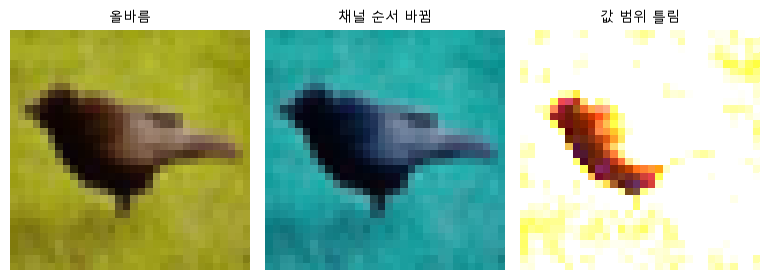

배치 축 없이 넣으면 → RuntimeError
배치 축을 붙이면 → 출력 모양 (1, 10)


In [14]:
# 왜 · 축 · 범위 · 채널 순서를 틀리면 그림이 어떻게 망가지는지 보기 위해
wrong_axis = chw.permute(1, 2, 0).numpy()[:, :, [2, 1, 0]]         # 채널 순서를 뒤집음 (RGB → BGR)
wrong_scale = np.clip(hwc.astype(np.float32) / 255 * 8, 0, 1)      # 값 범위를 8배로
grid([hwc, wrong_axis, wrong_scale], ["올바름", "채널 순서 바뀜", "값 범위 틀림"])  # 세 장
try:                                                               # 배치 축 없이 넣기
    small(chw)                                                     # (3, 32, 32)
except Exception as e:                                             # 오류를 잡아 이름만
    print(f"배치 축 없이 넣으면 → {type(e).__name__}")             # 어떤 오류인가
print(f"배치 축을 붙이면 → 출력 모양 {tuple(small(nchw).shape)}")  # (1, 10)

**결과** · 예측 정답은 RuntimeError

- `배치 축 없이 넣으면 → RuntimeError` — 모양이 맞지 않음
- `배치 축을 붙이면 → 출력 모양 (1, 10)` — 한 장 · 점수 10개
- 그림 · 채널 순서가 바뀐 사진은 파란 새 · 범위가 틀린 사진은 하얗게 날아감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>채널 순서 틀림</td><td>오류 없음 · 색이 뒤집힘</td><td>OpenCV(BGR) 사진을 넣을 때</td></tr>
<tr><td>값 범위 틀림</td><td>오류 없음 · 점수만 이상</td><td>정규화 빠뜨림</td></tr>
<tr><td>배치 축 빠짐</td><td>오류 남</td><td>한 장 예측</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 오류가 나는 실수보다 오류 없는 실수(색 · 범위)가 더 위험
> - OpenCV `cv2.imread`는 BGR 순서

> ✅ **한 줄 정리** · 채널 순서와 값 범위를 틀리면 오류 없이 결과만 망가지고, 배치 축을 빠뜨리면 오류가 난다.

**딥러닝 코드에서는**

- `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` — OpenCV 사진을 넣기 전
- 점수가 이상하게 낮으면 입력 약속부터 확인

### 4-3. `A` `to_tensor` 한 줄이 하는 세 단계 · `transpose(2, 0, 1)` · `np.allclose` <sub>원본 5장</sub>

> 🎯 **`to_tensor`는 정확히 어떤 세 가지 일을 한 번에 하는가?**

💡 **쉽게 말하면**

- ① 읽기 ② 축 옮기기 ③ 실수로 바꿔 255로 나누기.
- 직접 한 결과와 `to_tensor` 결과가 같은지 확인.

**실행 흐름**

1. 배열로 읽기
2. transpose로 축 옮기기
3. float32 ÷ 255
4. to_tensor와 비교

**먼저 예측** · 축만 옮긴 단계의 값 범위는? — 답은 코드 실행 결과 아래에

In [15]:
# 왜 · to_tensor 한 줄이 하는 세 단계를 직접 나눠 결과가 같은지 검증하기 위해
step1 = np.array(img)                                                  # 1) 읽기 (H, W, C) · uint8
step2 = step1.transpose(2, 0, 1)                                       # 2) 축 옮기기 (C, H, W)
step3 = step2.astype(np.float32) / 255                                 # 3) 실수로 바꿔 255로 나누기
print(f"1) 읽기       {step1.shape} · {step1.dtype} · {step1.min()}~{step1.max()}")  # 원래
print(f"2) 축 옮기기   {step2.shape} · {step2.dtype} · {step2.min()}~{step2.max()}")  # 값은 그대로
print(f"3) 실수로 나누기 {step3.shape} · {step3.dtype} · "             # 0~1
      f"{step3.min():.2f}~{step3.max():.2f}")
same = np.allclose(step3, TF.to_tensor(img).numpy())                   # to_tensor 결과와 같은가
print(f"to_tensor 한 줄이 이 셋을 한 번에 함 — 결과가 같은가 {same}")  # True

1) 읽기       (32, 32, 3) · uint8 · 0~191
2) 축 옮기기   (3, 32, 32) · uint8 · 0~191
3) 실수로 나누기 (3, 32, 32) · float32 · 0.00~0.75
to_tensor 한 줄이 이 셋을 한 번에 함 — 결과가 같은가 True


**결과** · 예측 정답은 그대로 0~191 · uint8

- `2) 축 옮기기 (3, 32, 32) · uint8 · 0~191` — 모양만 바뀌고 값은 그대로
- `3) 실수로 나누기 (3, 32, 32) · float32 · 0.00~0.75` — 실수 0 ~ 1
- `to_tensor 한 줄이 이 셋을 한 번에 함 — 결과가 같은가 True` — 세 단계 = to_tensor

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>np.transpose(2, 0, 1)</code></td><td>넘파이 축 옮기기</td><td>직접 변환</td></tr>
<tr><td><code>tensor.permute(2, 0, 1)</code></td><td>텐서 축 옮기기</td><td>이미 텐서일 때</td></tr>
<tr><td><code>TF.to_tensor</code></td><td>세 단계 한 번에</td><td>PIL · 넘파이 → 텐서</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 255로 나누기 전에 float로 바꿔야 함 · uint8끼리 나누면 정수가 됨
> - `to_tensor`는 uint8일 때만 255로 나눔

> ✅ **한 줄 정리** · `to_tensor`는 읽은 배열의 축을 옮기고 실수로 바꿔 255로 나누는 세 단계를 한 줄로 한다.

**딥러닝 코드에서는**

- torchvision v2는 `ToImage()` + `ToDtype(float32, scale=True)` 두 단계로 나눔
- 직접 바꿔 보고 라이브러리 결과와 `allclose`로 맞춰 보는 습관

### 4-4. `B` 에러 메시지 읽는 순서 · `traceback.format_exc()` <sub>원본 5장</sub>

> 🎯 **긴 에러 메시지는 어디부터 읽어야 하는가?**

💡 **쉽게 말하면**

- **맨 아래 줄**이 오류 종류와 이유 · 먼저 읽을 곳.
- 가운데 줄은 라이브러리 안쪽 경로 · 처음엔 건너뜀.

**실행 흐름**

1. 배치 축 없이 넣어 오류 내기
2. 메시지 전체를 줄 목록으로
3. 첫 줄 · 가운데 줄 수 · 맨 아래 줄

**먼저 예측** · 맨 아래 줄에는 무엇이 적혀 있을까? — 답은 코드 실행 결과 아래에

In [16]:
# 왜 · 에러 메시지 전체를 문자열로 받아 읽는 순서를 연습하기 위해
import traceback  # 오류 메시지 전체를 문자열로

try:                                                             # 일부러 배치 축 없이
    small(chw)                                                   # 오류
except Exception:                                                # 잡아서
    lines = traceback.format_exc().strip().splitlines()          # 줄 목록
print("에러 칸 첫 줄  →", lines[0][:70])                         # Traceback 시작
print("가운데 줄 수   →", len(lines) - 2, "줄 (처음엔 건너뜀)")  # 라이브러리 안쪽 경로
print("맨 아래 줄     →", lines[-1][:110])                       # 오류 종류와 이유 = 먼저 읽을 줄

에러 칸 첫 줄  → Traceback (most recent call last):
가운데 줄 수   → 18 줄 (처음엔 건너뜀)
맨 아래 줄     → RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x64 and 2048x10)


**결과** · 예측 정답은 RuntimeError: 두 행렬 모양이 곱할 수 없다는 이유

- `에러 칸 첫 줄 → Traceback (most recent call last):` — 시작 표시
- `줄 (처음엔 건너뜀)` — 라이브러리 안쪽 경로 · 줄 수는 실행 환경(터미널 · 주피터)마다 다름
- `RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x64 and 2048x10)` — 배치 없이 넣어 Flatten이 (32, 64)를 만듦 · Linear는 2048 길이를 기대

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>맨 아래 줄</td><td>오류 종류 · 이유</td><td>가장 먼저</td></tr>
<tr><td>내 코드 줄</td><td>어디서 불렀나</td><td>두 번째</td></tr>
<tr><td>라이브러리 안쪽 줄</td><td>깊은 경로</td><td>필요할 때만</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 'shapes cannot be multiplied'는 대부분 Linear 입력 길이 문제
> - 숫자(32x64 · 2048x10)가 원인의 단서

> ✅ **한 줄 정리** · 에러 메시지는 맨 아래 줄의 오류 종류와 이유부터 읽고, 숫자를 단서로 어느 모양이 어긋났는지 찾는다.

**딥러닝 코드에서는**

- Linear 입력 길이 오류 → Flatten 직전 `x.shape`를 찍어 봄
- 검색할 때도 맨 아래 줄을 그대로 붙여 넣음

---
## 5. 화면에서 크게 본 그 그림의 실제 크기

> **이 장의 흐름**
>
> - 실제 크기 확인 → 224로 늘리기 (최근접 · 선형)
> - 그다음 잘라내기 · 비율 바꾸기 → 가운데 10칸만 보고 맞히기

<img src="images/pfcnn2_ch5.png" alt="크기 맞추기 세 가지" width="577">

**파이프라인 위치** · ⑤ 크기 맞추기

### 5-1. `B` 실제 크기 · `arr.shape` · `arr.size` <sub>원본 6장</sub>

> 🎯 **화면에 크게 그린 사진의 실제 크기는 몇 칸인가?**

💡 **쉽게 말하면**

- 화면에서는 크게 보여도 **실제는 32 × 32칸**.
- 크게 그려도 없던 세부는 생기지 않음.

**실행 흐름**

1. 크기 · 채널
2. 값 범위
3. 숫자 개수 · 정답
4. 크게 그리기

**먼저 예측** · 화면 그림이 크면 숫자도 많을까? — 답은 코드 실행 결과 아래에

한 장 크기 32×32 · 채널 3
값 타입 uint8 · 가장 작은 값 0 · 가장 큰 값 191
한 장에 들어 있는 숫자 3072개 · 정답 bird


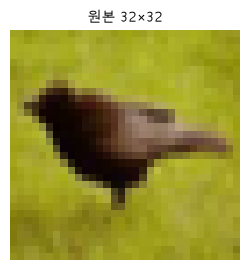

In [17]:
# 왜 · 화면에서 크게 보이는 그림의 실제 크기를 숫자로 확인하기 위해
print(f"한 장 크기 {arr.shape[0]}×{arr.shape[1]} · 채널 {arr.shape[2]}")       # 실제 크기
print(f"값 타입 {arr.dtype} · 가장 작은 값 {arr.min()} · 가장 큰 값 {arr.max()}")  # 값
print(f"한 장에 들어 있는 숫자 {arr.size}개 · 정답 {CLASSES[targets[SHOW]]}")  # 숫자 개수
grid([arr], [f"원본 {arr.shape[0]}×{arr.shape[1]}"])                           # 화면에는 크게 보임

**결과** · 예측 정답은 아님 — 늘 3072개

- `한 장 크기 32×32 · 채널 3` — 실제 칸 수
- `한 장에 들어 있는 숫자 3072개 · 정답 bird` — 그리는 크기와 무관

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>실제 크기</td><td>배열의 칸 수</td><td>모델 입력</td></tr>
<tr><td>그리는 크기</td><td>figsize · 화면</td><td>사람이 보기 위함</td></tr>
<tr><td>NEAREST로 그리기</td><td>칸이 그대로 보임</td><td>실제 해상도를 느낄 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - matplotlib은 기본으로 부드럽게 섞어 그림 → 실제보다 선명해 보일 수 있음
> - 실제 크기는 늘 `shape`로 확인

> ✅ **한 줄 정리** · 화면에 크게 그린 사진도 실제는 32 × 32칸 3072개 숫자이며, 크게 그린다고 세부가 생기지 않는다.

**딥러닝 코드에서는**

- `imshow(..., interpolation='nearest')` — 작은 사진을 볼 때
- 모델은 화면이 아니라 배열의 칸만 봄

### 5-2. `A` 224로 늘리기 — 최근접 · 선형 · `InterpolationMode.NEAREST` · `BILINEAR` <sub>원본 6장</sub>

> 🎯 **32칸을 224칸으로 늘리면 새 칸은 무엇으로 채우고, 색 개수는 어떻게 되는가?**

💡 **쉽게 말하면**

- 최근접 = **가장 가까운 칸을 복사** · 색이 새로 안 생김.
- 선형 = **이웃 칸을 섞어** 채움 · 중간색이 새로 생김.

**실행 흐름**

1. 최근접 · 선형으로 224 늘리기
2. 한 변 배율
3. 서로 다른 색 개수 비교
4. 세 장 그리기

**먼저 예측** · 최근접으로 늘린 뒤 색 개수는 원본보다 많을까? — 답은 코드 실행 결과 아래에

늘린 크기 224×224 · 한 변이 7배
늘린 뒤 서로 다른 색 개수 — 최근접 976개 · 선형 18390개
원본의 서로 다른 색 개수 976개


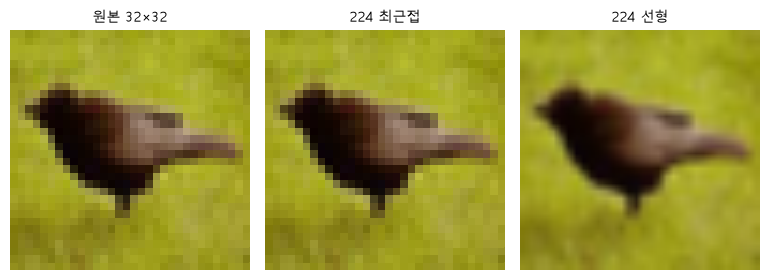

In [18]:
# 왜 · 224로 늘릴 때 채우는 방법에 따라 그림이 어떻게 달라지는지 비교하기 위해
src = img                                                             # 원본 32×32
side = src.size[0]                                                    # 한 변 32
up_near = TF.resize(src, [224, 224], interpolation=NEAREST)           # 최근접으로 늘림
up_lin = TF.resize(src, [224, 224], interpolation=BILINEAR)           # 선형으로 늘림
print(f"늘린 크기 {up_near.size[0]}×{up_near.size[1]} · 한 변이 {up_near.size[0] // side}배")  # 7배
print(f"늘린 뒤 서로 다른 색 개수 — 최근접 {n_colors(up_near)}개 · "  # 섞으면 중간색이 생김
      f"선형 {n_colors(up_lin)}개")
print(f"원본의 서로 다른 색 개수 {n_colors(src)}개")                  # 비교 기준
grid([src, up_near, up_lin], [f"원본 {side}×{side}", "224 최근접", "224 선형"])  # 세 장

**결과** · 예측 정답은 같음(976개) · 선형은 18390개

- `늘린 크기 224×224 · 한 변이 7배` — 칸 하나가 7 × 7 블록
- `최근접 976개 · 선형 18390개` — 선형은 섞은 중간색이 새로 생김
- `원본의 서로 다른 색 개수 976개` — 최근접은 원본 색 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>NEAREST</td><td>복사 · 계단 모양</td><td>라벨 지도(분할) 크기 바꿀 때</td></tr>
<tr><td>BILINEAR</td><td>섞음 · 부드러움</td><td>사진 입력 크기 바꿀 때</td></tr>
<tr><td>늘리기 공통</td><td>정보는 늘지 않음</td><td>모델 입력 크기를 맞출 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 선형으로 늘려 생긴 중간색은 원래 사진에 없던 값
> - 분할 정답 지도는 NEAREST로 · 섞으면 없는 종류 번호가 생김

> ✅ **한 줄 정리** · 늘리기는 정보를 늘리지 않으며, 최근접은 원본 색만 복사하고 선형은 이웃을 섞어 중간색을 만든다.

**딥러닝 코드에서는**

- pretrained 모델에 CIFAR를 넣을 때 32 → 224 늘리기 (파일별 1의 13장)
- `Resize(..., interpolation=NEAREST)` — 마스크용

### 5-3. `A` 잘라내기 · 늘리기 · 비율 바꾸기 · `TF.center_crop` · `TF.resize` <sub>원본 6장</sub>

> 🎯 **늘리기 · 가운데 잘라 늘리기 · 비율 바꾸기는 각각 무엇을 잃는가?**

💡 **쉽게 말하면**

- 잘라내면 **가장자리 픽셀을 버림**, 늘리기는 아무것도 안 버림.
- 비율을 바꾸면 **모양이 찌그러짐**.

**실행 흐름**

1. 224로 그대로 늘리기
2. 가운데 16칸 잘라 늘리기
3. 세로 8칸으로 눌렀다가 늘리기
4. 버린 픽셀 수

**먼저 예측** · 가운데 16 × 16만 남기면 몇 픽셀을 버릴까? — 답은 코드 실행 결과 아래에

가운데만 남긴 크기 16×16 · 버린 픽셀 768개
늘리기는 버린 픽셀 0개


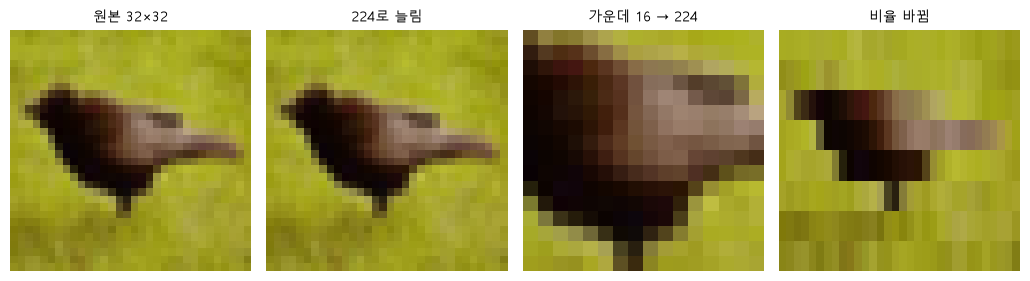

In [19]:
# 왜 · 잘라내기 · 늘리기 · 비율 바꾸기가 각각 무엇을 바꾸는지 비교하기 위해
keep, squash_h = 16, 8                                       # 가운데 남길 칸 · 세로로 누를 칸
resized = TF.resize(src, [224, 224], interpolation=NEAREST)  # 그대로 늘림
# 잘라 늘림
cropped = TF.resize(TF.center_crop(src, [keep, keep]), [224, 224], interpolation=NEAREST)
# 세로로 눌렀다가 늘림 = 비율 바뀜
squashed = TF.resize(TF.resize(src, [squash_h, side], interpolation=NEAREST), [224, 224],
                     interpolation=NEAREST)
print(f"가운데만 남긴 크기 {keep}×{keep} · 버린 픽셀 {side * side - keep * keep}개")  # 잃은 정보
print(f"늘리기는 버린 픽셀 {side * side - side * side}개")   # 0
grid([src, resized, cropped, squashed],                      # 네 장
     [f"원본 {side}×{side}", "224로 늘림", f"가운데 {keep} → 224", "비율 바뀜"])

**결과** · 예측 정답은 768개 — 1024 - 256

- `가운데만 남긴 크기 16×16 · 버린 픽셀 768개` — 4분의 3을 버림
- `늘리기는 버린 픽셀 0개` — 늘리기는 정보를 잃지 않음 (늘지도 않음)
- 그림 · 비율을 바꾼 사진은 새가 찌그러짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>Resize</td><td>버리는 칸 없음 · 비율이 다르면 찌그러짐</td><td>크기 통일</td></tr>
<tr><td>CenterCrop</td><td>가장자리 버림</td><td>대상이 가운데일 때</td></tr>
<tr><td>Resize 후 CenterCrop</td><td>비율 유지 + 크기 맞춤</td><td>ImageNet 표준 (256 → 224)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 대상이 가장자리에 있으면 잘라내기로 대상이 사라짐
> - 비율이 다른 사진을 정사각형으로 늘리면 모양 단서가 바뀜

> ✅ **한 줄 정리** · 잘라내기는 가장자리 정보를, 비율 바꾸기는 모양을 잃게 하므로 크기 맞추기 방법은 대상의 위치와 모양을 보고 고른다.

**딥러닝 코드에서는**

- `transforms.Compose([Resize(256), CenterCrop(224)])` — 검증 전처리 표준
- `RandomResizedCrop` — 학습 증강에서 자르기 · 비율을 흔듦

### 5-4. `B` 가운데 10칸만 보고 맞히기 · `center_crop(..., [10, 10])` <sub>원본 6장</sub>

> 🎯 **원본의 10% 넓이만 남기면 사람도 무엇인지 알 수 있는가?**

💡 **쉽게 말하면**

- 가운데 10 × 10만 남겨 키운 세 장을 먼저 맞혀 봄.
- 그다음 원본과 정답을 확인.

**실행 흐름**

1. 세 장의 가운데 10칸 잘라 224로
2. A · B · C 맞혀 보기
3. 정답 출력 · 원본 그리기

**먼저 예측** · A · B · C는 각각 무엇일까? — 답은 코드 실행 결과 아래에

가운데 10×10만 남김 · 원본의 10% 넓이


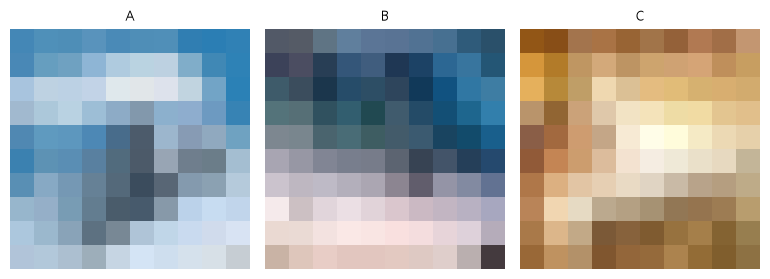

정답 A=ship · B=automobile · C=frog


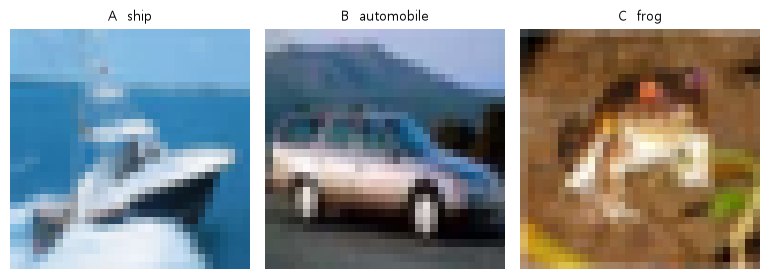

In [20]:
# 왜 · 가운데 일부만 보고도 맞힐 수 있는지 확인하기 위해
tiny = 10                                # 가운데 10×10만 남김
# 세 장의 가운데 10칸만 크게
tests = [TF.resize(TF.center_crop(raw[i][0], [tiny, tiny]), [224, 224], interpolation=NEAREST)
         for i in PICK]
print(f"가운데 {tiny}×{tiny}만 남김 · "  # 10%
      f"원본의 {round(tiny * tiny / (side * side) * 100)}% 넓이")
grid(tests, ["A", "B", "C"])             # 무엇인지 맞혀 보기
print("정답 " + " · ".join(f"{n}={CLASSES[raw[i][1]]}" for n, i in zip("ABC", PICK)))  # 정답
grid([raw[i][0] for i in PICK], [f"{n}  {CLASSES[raw[i][1]]}" for n, i in zip("ABC", PICK)])  # 원본

**결과** · 예측 정답은 A 배 · B 자동차 · C 개구리

- `가운데 10×10만 남김 · 원본의 10% 넓이` — 100 ÷ 1024 ≈ 10%
- `정답 A=ship · B=automobile · C=frog` — 잘린 조각만으로는 사람도 어려움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>작게 잘라 키우기</td><td>단서가 대부분 사라짐</td><td>해로운 증강 (9장)</td></tr>
<tr><td>조금 자르기</td><td>단서 유지</td><td>안전한 증강</td></tr>
<tr><td>원본</td><td>전체 모습</td><td>판단 기준</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 잘라낸 조각에 정답 이름을 그대로 붙이면 틀린 것을 가르치는 셈
> - 작게 자를수록 사람이 봐도 판단할 수 없는지 먼저 확인

> ✅ **한 줄 정리** · 가운데 10%만 남기면 사람도 알아보기 어려우므로, 자르는 크기는 정답을 판단할 단서가 남는지로 정한다.

**딥러닝 코드에서는**

- `RandomResizedCrop(scale=(0.08, 1.0))` 기본 하한이 작음 → 작은 사진에는 크게 잡기도 함
- 증강 결과를 눈으로 확인하는 습관 (9장)

---
## 6. 값의 범위 맞추기

> **이 장의 흐름**
>
> - 0 ~ 1로 줄이기
> - 그다음 채널마다 평균을 빼고 표준편차로 나누기 (정규화)

<img src="images/pfcnn2_ch6.png" alt="0~255 → 0~1 → 정규화" width="584">

**파이프라인 위치** · ⑥ 값의 범위 맞추기

### 6-1. `A` 0–1로 줄이기 · 평균과 표준편차로 옮기기 · `TF.normalize` · `MEAN · STD` <sub>원본 7장</sub>

> 🎯 **정규화를 하면 값의 범위와 평균은 어떻게 되고, 채널마다 왜 결과가 다른가?**

💡 **쉽게 말하면**

- 정규화 = (값 - 평균) ÷ 표준편차 · **가운데를 0 근처로** 옮김.
- 채널마다 다른 평균 · 표준편차를 씀.

**실행 흐름**

1. 0 ~ 1로 줄이기
2. ImageNet 평균 · 표준편차로 정규화
3. 범위 · 평균 비교
4. 세 채널이 0.5일 때 결과

**먼저 예측** · 세 채널이 모두 0.5이면 정규화 뒤에도 셋이 같을까? — 답은 코드 실행 결과 아래에

In [21]:
# 왜 · 값의 범위를 0–1로 줄인 뒤 평균 · 표준편차로 옮기는 과정을 확인하기 위해
zero_one = TF.to_tensor(img)                                                   # 0~1로 줄임
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet 채널별 평균 · 표준편차
normed = TF.normalize(zero_one.clone(), MEAN, STD)  # (x - 평균) / 표준편차 · 채널마다
print(f"원래 값 {hwc.min()}~{hwc.max()} · 평균 {hwc.mean():.1f}")              # 0~255
print(f"0–1로 줄인 뒤 {zero_one.min():.2f}~{zero_one.max():.2f} · "            # ÷ 255 결과
      f"평균 {zero_one.mean():.2f}")
print(f"정규화 뒤 {normed.min():.2f}~{normed.max():.2f} · 평균 {normed.mean():.2f}")  # 0 근처
print(f"정규화는 채널마다 다른 값을 씀 — 평균 {MEAN} · 표준편차 {STD}")        # 세 쌍
half_t = torch.full((3, 1, 1), 0.5)                                            # 세 채널 모두 0.5
out = [round(v, 3) for v in TF.normalize(half_t, MEAN, STD).ravel().tolist()]  # 정규화 결과
print(f"세 채널이 모두 0.50이어도 정규화 뒤에는 {out}")                        # 채널마다 다름

원래 값 0~191 · 평균 104.1
0–1로 줄인 뒤 0.00~0.75 · 평균 0.41
정규화 뒤 -2.04~1.27 · 평균 -0.18
정규화는 채널마다 다른 값을 씀 — 평균 [0.485, 0.456, 0.406] · 표준편차 [0.229, 0.224, 0.225]
세 채널이 모두 0.50이어도 정규화 뒤에는 [0.066, 0.196, 0.418]


**결과** · 예측 정답은 다름 — 0.066 · 0.196 · 0.418

- `원래 값 0~191 · 평균 104.1` — uint8 정수 그대로
- `0–1로 줄인 뒤 0.00~0.75 · 평균 0.41` — to_tensor와 같은 나누기
- `정규화 뒤 -2.04~1.27 · 평균 -0.18` — 가운데가 0 근처 · 음수도 생김
- `세 채널이 모두 0.50이어도 정규화 뒤에는 [0.066, 0.196, 0.418]` — 채널마다 평균 · 표준편차가 달라서

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>0 ~ 1 (÷ 255)</td><td>범위만 줄임</td><td>직접 학습하는 작은 모델</td></tr>
<tr><td>정규화 (ImageNet 값)</td><td>채널마다 가운데 0 · 폭 비슷</td><td>pretrained 모델 · 큰 모델</td></tr>
<tr><td>내 데이터 평균 · 표준편차</td><td>데이터에서 직접 잼</td><td>ImageNet과 많이 다른 사진</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 학습 · 검증 · 테스트 · 예측에 모두 같은 값으로 정규화
> - 정규화한 사진을 그대로 그리면 색이 이상함 · 그릴 때는 되돌림

> ✅ **한 줄 정리** · 정규화는 채널마다 평균을 빼고 표준편차로 나눠 값을 0 근처로 옮기며, 같은 값으로 학습과 예측 모두에 써야 한다.

**딥러닝 코드에서는**

- `transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])`
- 효과는 10장에서 한 조건만 바꿔 비교

---
## 7. 이미지 처리는 무엇을 남기고 지우는가

> **이 장의 흐름**
>
> - 평탄한 자리 · 경계 자리에 커널 대 보기 → 아홉 칸 합의 뜻
> - 그다음 잡음 · 중앙값 · 경계 → 한 줄 단면 → 흐리기 단계

<img src="images/pfcnn2_ch7.png" alt="3×3 커널 세 가지" width="584">

**파이프라인 위치** · ⑦ 이미지 처리 (합성곱의 바탕)

### 7-1. `A` 커널 · 평탄한 자리와 경계 자리 · `sliding_window_view` · `unravel_index` <sub>원본 8장</sub>

> 🎯 **같은 커널을 평탄한 자리와 경계 자리에 대면 결과가 어떻게 다른가?**

💡 **쉽게 말하면**

- 커널 = 3 × 3 숫자 판 · 창 아홉 칸과 **곱해서 더함**.
- 흐리기는 평균, 경계 커널은 **이웃과의 차이**를 냄.

**실행 흐름**

1. 회색조 · 자리마다 3 × 3 창
2. 값이 가장 고른 자리 · 가장 다른 자리
3. 두 자리에 흐리기 · 경계 커널

**먼저 예측** · 평탄한 자리에서 경계 커널 값은 0 근처일까? — 답은 코드 실행 결과 아래에

In [22]:
# 왜 · 커널이 칸마다 하는 계산을 반복문 없이 직접 재현하기 위해
from numpy.lib.stride_tricks import sliding_window_view  # 3×3 창을 한 번에

g_arr = np.array(TF.to_grayscale(img), dtype=np.float32)          # 회색조 32×32
wins = sliding_window_view(g_arr, (3, 3))                         # (30, 30, 3, 3) · 자리마다 3×3 창
spread = wins.std(axis=(2, 3))                                    # 창 안 값이 얼마나 다른가
fy, fx = np.unravel_index(spread.argmin(), spread.shape)          # 가장 평탄한 자리
ey, ex = np.unravel_index(spread.argmax(), spread.shape)          # 가장 경계인 자리
flat, edge = wins[fy, fx], wins[ey, ex]                           # 두 창
blur_k = np.ones((3, 3), dtype=np.float32) / 9                    # 흐리기 커널 (평균)
edge_k = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=np.float32)  # 경계 커널
for name, patch in (("평탄한 자리", flat), ("경계 자리", edge)):  # 두 자리
    # 두 커널 결과 비교
    print(f"{name} — 가운데 값 {patch[1, 1]:.0f} · 흐리기 뒤 {(patch * blur_k).sum():.0f}"
          f" · 경계 커널 값 {(patch * edge_k).sum():.0f}")
print("흐리기는 이웃의 평균으로 바꿈 · 경계 커널은 이웃과 얼마나 다른지를 냄")  # 읽는 법

평탄한 자리 — 가운데 값 6 · 흐리기 뒤 6 · 경계 커널 값 -3
경계 자리 — 가운데 값 89 · 흐리기 뒤 83 · 경계 커널 값 56
흐리기는 이웃의 평균으로 바꿈 · 경계 커널은 이웃과 얼마나 다른지를 냄


**결과** · 예측 정답은 그렇다 — -3

- `평탄한 자리 — 가운데 값 6 · 흐리기 뒤 6 · 경계 커널 값 -3` — 이웃이 비슷 → 흐려도 그대로 · 경계 값 ≈ 0
- `경계 자리 — 가운데 값 89 · 흐리기 뒤 83 · 경계 커널 값 56` — 이웃과 다름 → 경계 값이 큼

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>흐리기 커널</td><td>1/9 아홉 칸 평균</td><td>잡음 줄이기</td></tr>
<tr><td>경계 커널</td><td>가운데 8 · 이웃 -1</td><td>모양 · 윤곽 찾기</td></tr>
<tr><td>CNN 필터</td><td>숫자를 학습이 정함</td><td>합성곱 층</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 창은 가장자리 한 칸씩 빼서 30 × 30자리
> - 커널 값은 사람이 정한 예 · CNN은 이 값을 스스로 배움

> ✅ **한 줄 정리** · 커널은 창 아홉 칸에 곱해 더하는 숫자 판이며, 흐리기는 평균을 내고 경계 커널은 이웃과의 차이를 낸다.

**딥러닝 코드에서는**

- `nn.Conv2d`가 하는 일 = 학습되는 커널을 자리마다 대기
- `F.conv2d(x, kernel)` — 정한 커널을 직접 대 볼 때

### 7-2. `B` 아홉 칸 합의 뜻 · `k.sum()` <sub>원본 8장</sub>

> 🎯 **커널 아홉 칸의 합이 1일 때와 0일 때 결과는 어떻게 다른가?**

💡 **쉽게 말하면**

- 합이 1 → **밝기 유지** · 합이 0 → 평탄한 자리가 **0에 가까워짐**.
- 또렷하게 커널도 합은 1.

**실행 흐름**

1. 또렷하게 커널 추가
2. 세 커널의 합 · 평탄한 자리 · 경계 자리 결과
3. 규칙 정리

**먼저 예측** · 또렷하게 커널은 경계 자리 값을 키울까? — 답은 코드 실행 결과 아래에

In [23]:
# 왜 · 커널 숫자의 합이 결과 밝기에 주는 영향을 확인하기 위해
sharp_k = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)             # 또렷하게
for name, k in (("흐리기", blur_k), ("경계", edge_k), ("또렷하게", sharp_k)):           # 커널 셋
    print(f"{name} 창 — 아홉 칸 합 {k.sum():.0f} · 평탄한 자리 {(flat * k).sum():.0f}"  # 합과 결과
          f" · 경계 자리 {(edge * k).sum():.0f}")
print("아홉 칸 합이 1이면 밝기가 유지됨 · 0이면 평탄한 자리가 0에 가까워짐")            # 규칙

흐리기 창 — 아홉 칸 합 1 · 평탄한 자리 6 · 경계 자리 83
경계 창 — 아홉 칸 합 0 · 평탄한 자리 -3 · 경계 자리 56
또렷하게 창 — 아홉 칸 합 1 · 평탄한 자리 6 · 경계 자리 106
아홉 칸 합이 1이면 밝기가 유지됨 · 0이면 평탄한 자리가 0에 가까워짐


**결과** · 예측 정답은 키움 — 89 → 106

- `흐리기 창 — 아홉 칸 합 1 · 평탄한 자리 6 · 경계 자리 83` — 합 1 · 밝기 유지 · 경계는 무뎌짐
- `경계 창 — 아홉 칸 합 0 · 평탄한 자리 -3 · 경계 자리 56` — 합 0 · 평탄하면 0 근처
- `또렷하게 창 — 아홉 칸 합 1 · 평탄한 자리 6 · 경계 자리 106` — 합 1 · 경계 차이를 키움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>합 1</td><td>밝기 유지</td><td>흐리기 · 또렷하게</td></tr>
<tr><td>합 0</td><td>평탄 → 0</td><td>경계 찾기</td></tr>
<tr><td>합이 1보다 큼</td><td>전체가 밝아짐</td><td>거의 안 씀</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 합이 0인 커널 결과는 음수가 나올 수 있음 · 그릴 때 범위 조절
> - 같은 커널도 자리마다 결과가 다름 · 자리의 이웃이 다르기 때문

> ✅ **한 줄 정리** · 커널 아홉 칸의 합이 1이면 밝기가 유지되고 0이면 평탄한 자리가 0에 가까워져 경계만 남는다.

**딥러닝 코드에서는**

- 학습된 CNN 첫 층 필터도 경계 · 색 차이 커널처럼 보이는 경우가 많음
- BatchNorm이 필터 결과의 크기를 다시 고르게 맞춤

### 7-3. `A` 잡음 · 중앙값 · 경계 · `ImageFilter.MedianFilter` · `FIND_EDGES` <sub>원본 8장</sub>

> 🎯 **잡음을 넣었다가 중앙값 필터로 지우면 원본에 얼마나 가까워지는가?**

💡 **쉽게 말하면**

- 중앙값 필터 = 창 아홉 칸 중 **가운데 값**으로 바꿈 · 튀는 값에 강함.
- 경계 필터는 윤곽만 남김.

**실행 흐름**

1. -40 ~ 40 잡음 넣기
2. 3 × 3 중앙값으로 지우기
3. 흐리게 · 경계와 함께 다섯 장
4. 원본과의 평균 차이

**먼저 예측** · 잡음을 지우면 원본과의 차이가 0이 될까? — 답은 코드 실행 결과 아래에

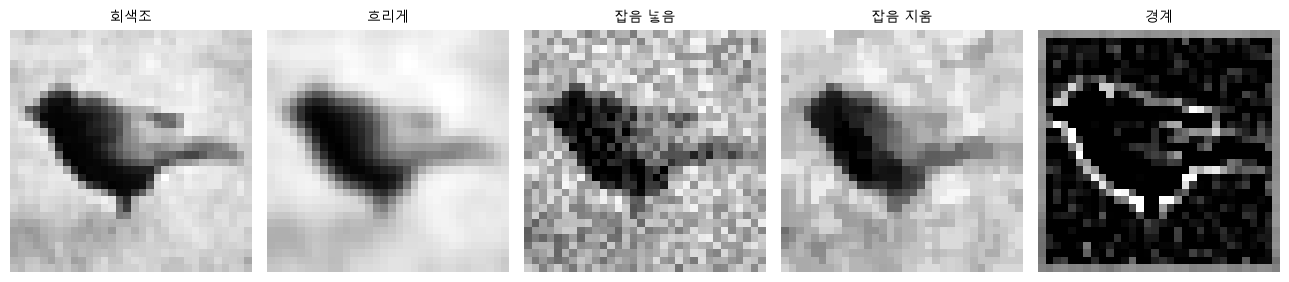

잡음을 넣은 뒤 원본과의 평균 차이 19.7
잡음을 지운 뒤 원본과의 평균 차이 11.7


In [24]:
# 왜 · 잡음 제거 · 경계 찾기 필터를 실제로 써 보기 위해
from PIL import Image as PILImage  # 배열 → PIL 사진
from PIL import ImageFilter        # 흐리기 · 중앙값 · 경계 필터

g_img = TF.to_grayscale(img)                                              # 회색조 사진
noise = np.random.randint(-40, 41, (32, 32))                              # -40 ~ 40 잡음
# 0~255로 자름
noisy_arr = np.clip(np.array(g_img).astype(np.int16) + noise, 0, 255).astype(np.uint8)
noisy = PILImage.fromarray(noisy_arr)                                     # 잡음 넣은 사진
denoised = noisy.filter(ImageFilter.MedianFilter(3))  # 3×3 중앙값으로 잡음 지우기
edges = g_img.filter(ImageFilter.FIND_EDGES)                              # 경계 찾기
grid([g_img, g_img.filter(ImageFilter.GaussianBlur(1)), noisy, denoised, edges],  # 처리 다섯 가지
     ["회색조", "흐리게", "잡음 넣음", "잡음 지움", "경계"])
a0, a1 = np.array(g_img).astype(float), np.array(noisy).astype(float)     # 비교용 실수 배열
print(f"잡음을 넣은 뒤 원본과의 평균 차이 {np.abs(a0 - a1).mean():.1f}")  # 크게 벌어짐
a2 = np.array(denoised).astype(float)                                     # 지운 사진
print(f"잡음을 지운 뒤 원본과의 평균 차이 {np.abs(a0 - a2).mean():.1f}")  # 줄었지만 0은 아님

**결과** · 예측 정답은 아님 — 19.7 → 11.7 (줄지만 0은 아님)

- `잡음을 넣은 뒤 원본과의 평균 차이 19.7` — 잡음만큼 벌어짐
- `잡음을 지운 뒤 원본과의 평균 차이 11.7` — 줄었지만 세부도 함께 지워짐
- 그림 · 경계 칸은 윤곽만 밝게 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>가우시안 흐리기</td><td>가중 평균</td><td>부드럽게</td></tr>
<tr><td>중앙값 필터</td><td>가운데 값</td><td>점 잡음 지우기</td></tr>
<tr><td>경계 필터</td><td>차이만</td><td>윤곽 보기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 잡음을 지우면 세부도 같이 사라짐 · 완전히 되돌아오지 않음
> - 잡음은 무작위 · seed가 같아야 같은 값

> ✅ **한 줄 정리** · 중앙값 필터는 잡음을 크게 줄이지만 세부도 함께 지우므로 원본으로 완전히 돌아가지는 않는다.

**딥러닝 코드에서는**

- 잡음 증강(가우시안 노이즈) · 잡음 제거 오토인코더(다음 과목)의 바탕
- PIL `ImageFilter` · OpenCV `cv2.medianBlur` — 같은 처리

### 7-4. `B` 한 줄 단면으로 보는 흐리기 · `np.diff` · `GaussianBlur(3)` <sub>원본 8장</sub>

> 🎯 **흐리기는 한 줄의 밝기 변화를 어떻게 바꾸는가?**

💡 **쉽게 말하면**

- 가운데 한 줄의 밝기를 선으로 그리면 **들쭉날쭉 → 매끈**.
- 이웃 칸끼리 차이가 줄어듦 = 경계가 무뎌짐.

**실행 흐름**

1. 가운데 한 줄 · 흐린 뒤 같은 줄
2. 두 선 그리기
3. 이웃 칸 평균 차이

**먼저 예측** · 흐린 뒤 이웃 칸 차이는 절반쯤으로 줄까? — 답은 코드 실행 결과 아래에

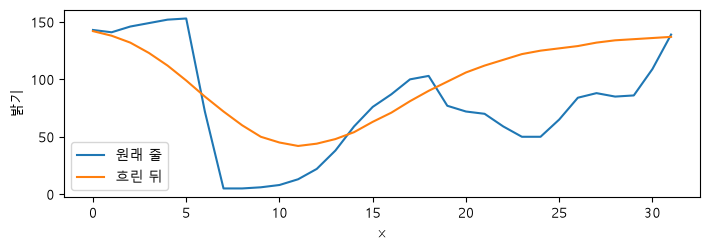

이웃한 칸끼리의 평균 차이 — 원본 13.2 · 흐린 뒤 6.3


In [25]:
# 왜 · 한 줄 단면으로 흐리기가 경계를 어떻게 바꾸는지 숫자로 보기 위해
row = np.array(g_img, dtype=float)[16]      # 가운데 한 줄 (32칸)
row_blur = np.array(g_img.filter(ImageFilter.GaussianBlur(3)), dtype=float)[16]  # 흐린 뒤 같은 줄
fig, ax = plt.subplots(figsize=(7.2, 2.6))  # 단면 그림
ax.plot(row, label="원래 줄")               # 들쭉날쭉
ax.plot(row_blur, label="흐린 뒤")          # 매끈
ax.set_xlabel("x")                          # 가로 위치
ax.set_ylabel("밝기")                       # 값
ax.legend()                                 # 범례
fig.tight_layout()                          # 정리
plt.show()                                  # 그리기
step = np.abs(np.diff(row)).mean()          # 이웃 칸끼리 평균 차이
step_b = np.abs(np.diff(row_blur)).mean()   # 흐린 뒤
print(f"이웃한 칸끼리의 평균 차이 — 원본 {step:.1f} · 흐린 뒤 {step_b:.1f}")  # 경계가 무뎌짐

**결과** · 예측 정답은 그렇다 — 13.2 → 6.3

- `이웃한 칸끼리의 평균 차이 — 원본 13.2 · 흐린 뒤 6.3` — 경계가 무뎌짐
- 그림 · 주황 선이 매끈 · 큰 계단이 낮아짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>단면 그래프</td><td>한 줄 밝기</td><td>변화를 눈으로</td></tr>
<tr><td>이웃 차이 평균</td><td>숫자 하나</td><td>흐린 정도 비교</td></tr>
<tr><td>사진 그대로 보기</td><td>전체 인상</td><td>대략적인 판단</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 한 줄만 본 것 · 다른 줄은 다를 수 있음
> - 흐리기 반경 3은 32칸 사진에 아주 강한 흐리기

> ✅ **한 줄 정리** · 흐리기는 이웃 칸끼리의 차이를 줄여 밝기 변화를 매끈하게 만들고, 그만큼 경계가 무뎌진다.

**딥러닝 코드에서는**

- 해상도를 낮추기 전에 흐리기(안티에일리어싱) — `antialias=True`
- 모델은 경계 단서를 쓰므로 흐린 사진에 약해질 수 있음 (11장 실습)

### 7-5. `B` 흐리기 단계 · `GaussianBlur(r)` <sub>원본 8장</sub>

> 🎯 **흐리기를 점점 세게 하면 이웃 칸 차이는 어떻게 줄어드는가?**

💡 **쉽게 말하면**

- 반경 0 · 1 · 2 · 4로 세게.
- 셀수록 단서(경계)가 더 사라짐.

**실행 흐름**

1. 네 단계 흐리기
2. 네 장 그리기
3. 단계별 이웃 차이

**먼저 예측** · 반경 4에서 이웃 차이는 원본의 몇 분의 1일까? — 답은 코드 실행 결과 아래에

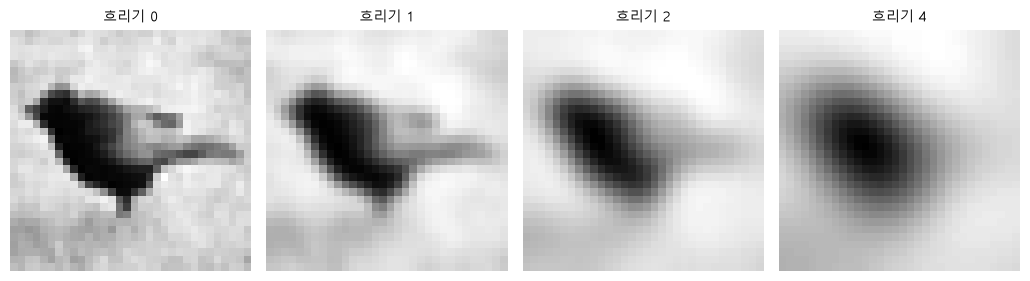

이웃한 칸끼리의 평균 차이 흐리기 0:13.2 · 흐리기 1:9.1 · 흐리기 2:7.6 · 흐리기 4:4.8


In [26]:
# 왜 · 흐리기 세기에 따라 남는 정보가 어떻게 줄어드는지 비교하기 위해
levels = [0, 1, 2, 4]                                                     # 흐리기 세기 (0 = 원본)
# 세기별 흐린 사진
blurred = [g_img if r_ == 0 else g_img.filter(ImageFilter.GaussianBlur(r_)) for r_ in levels]
grid(blurred, [f"흐리기 {r_}" for r_ in levels])                          # 네 장
diffs = [np.abs(np.diff(np.array(b_, dtype=float)[16])).mean() for b_ in blurred]  # 단면 차이
txt = " · ".join(f"흐리기 {r_}:{d:.1f}" for r_, d in zip(levels, diffs))  # 단계별 값
print("이웃한 칸끼리의 평균 차이 " + txt)                                 # 세질수록 작아짐

**결과** · 예측 정답은 약 3분의 1 — 13.2 → 4.8

- `흐리기 0:13.2 · 흐리기 1:9.1 · 흐리기 2:7.6 · 흐리기 4:4.8` — 셀수록 계속 줄어듦

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>약한 흐리기</td><td>잡음만 줄임</td><td>안전한 증강</td></tr>
<tr><td>강한 흐리기</td><td>경계까지 지움</td><td>해로울 수 있음</td></tr>
<tr><td>단계별 측정</td><td>세기 · 효과 곡선</td><td>증강 세기 정하기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 32칸 사진에서 반경 4는 거의 형체만 남음
> - 증강 세기는 정답 단서가 남는 범위에서

> ✅ **한 줄 정리** · 흐리기를 세게 할수록 이웃 칸 차이가 줄어 경계 단서가 사라지므로, 증강 세기는 단서가 남는 범위에서 고른다.

**딥러닝 코드에서는**

- `GaussianBlur(kernel_size, sigma=(0.1, 2.0))` — 세기를 무작위로 고르는 증강
- 세기를 바꾸며 재는 실험은 파일별 1 종합 실습 1과 같은 틀

---
## 8. 어떤 데이터를 학습과 평가에 쓰는가

> **이 장의 흐름**
>
> - 크기 · 장수 · 겹침 탐색 기록 → 같은 종류 안의 다양함
> - 그다음 증강본과 나누는 순서

<img src="images/pfcnn2_ch8.png" alt="나누기와 증강의 순서" width="577">

**파이프라인 위치** · ⑧ 데이터 점검 · 분할

### 8-1. `A` 크기 · 장수 · 겹침 — 탐색 기록 · `set` · `np.bincount` <sub>원본 9장</sub>

> 🎯 **학습 · 검증 데이터는 크기가 같고, 종류가 고르며, 서로 겹치지 않는가?**

💡 **쉽게 말하면**

- 확인한 것과 **확인 못 한 것**을 함께 적음.
- 학습과 검증이 겹치면 점수가 부풀려짐.

**실행 흐름**

1. 표본 200장의 크기 종류
2. 학습 · 검증 종류별 장수
3. 두 묶음의 겹치는 번호
4. 확인 못 한 정보 기록

**먼저 예측** · 학습과 검증은 몇 장 겹칠까? — 답은 코드 실행 결과 아래에

In [27]:
# 왜 · 데이터의 크기 · 장수 · 겹침을 먼저 확인해 탐색 기록을 남기기 위해
sizes = {raw[int(i)][0].size for i in tr_idx[:200]}                         # 표본 200장의 크기 종류
print(f"표본 200장의 크기 종류 {sizes} · 한 가지뿐임")                      # 모두 32×32
print(f"학습 클래스별 장수 {np.bincount(targets[tr_idx]).tolist()}")        # 100씩
print(f"검증 클래스별 장수 {np.bincount(targets[va_idx]).tolist()}")        # 50씩
print(f"학습과 검증이 겹치는 장수 {len(set(tr_idx.tolist()) & set(va_idx.tolist()))}장")  # 0
print("파일 이름 · 촬영 정보는 이 로더가 주지 않음 — 확인 못 함으로 남김")  # 탐색 기록

표본 200장의 크기 종류 {(32, 32)} · 한 가지뿐임
학습 클래스별 장수 [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
검증 클래스별 장수 [50, 50, 50, 50, 50, 50, 50, 50, 50, 50]
학습과 검증이 겹치는 장수 0장
파일 이름 · 촬영 정보는 이 로더가 주지 않음 — 확인 못 함으로 남김


**결과** · 예측 정답은 0장

- `표본 200장의 크기 종류 {(32, 32)} · 한 가지뿐임` — 크기 통일 · Resize 필요 없음
- `학습 클래스별 장수 [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]` — 종류마다 100장
- `학습과 검증이 겹치는 장수 0장` — 번호로 나눠 겹침 없음
- `파일 이름 · 촬영 정보는 이 로더가 주지 않음` — 확인 못 한 것도 기록

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>크기 확인</td><td>모두 같은가</td><td>Resize 필요 여부</td></tr>
<tr><td>장수 확인</td><td>고른가</td><td>기준선 · 불균형</td></tr>
<tr><td>겹침 확인</td><td>같은 번호가 양쪽에</td><td>누수 방지</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 번호가 달라도 거의 같은 사진이 양쪽에 있을 수 있음 (파일별 1의 2-4)
> - 확인 못 한 것을 '문제 없음'으로 적지 않음

> ✅ **한 줄 정리** · 탐색 기록에는 크기 · 장수 · 겹침처럼 확인한 것과 촬영 정보처럼 확인 못 한 것을 함께 적는다.

**딥러닝 코드에서는**

- `set(train_ids) & set(val_ids)` — 분할 직후 한 줄 점검
- 데이터 카드(dataset card) · README에 탐색 기록을 남김

### 8-2. `B` 같은 종류 안의 다양함 · `np.where(...)[0][3]` <sub>원본 9장</sub>

> 🎯 **크기가 같으면 사진 조건도 같은가?**

💡 **쉽게 말하면**

- 크기는 같아도 **배경 · 각도 · 가림 정도**는 장마다 다름.
- 모델이 배울 것은 그 다양함 속의 공통점.

**실행 흐름**

1. 종류마다 네 번째 장
2. 두 줄로 그리기
3. 관찰 기록

**먼저 예측** · 같은 종류 사진은 비슷한 배경일까? — 답은 코드 실행 결과 아래에

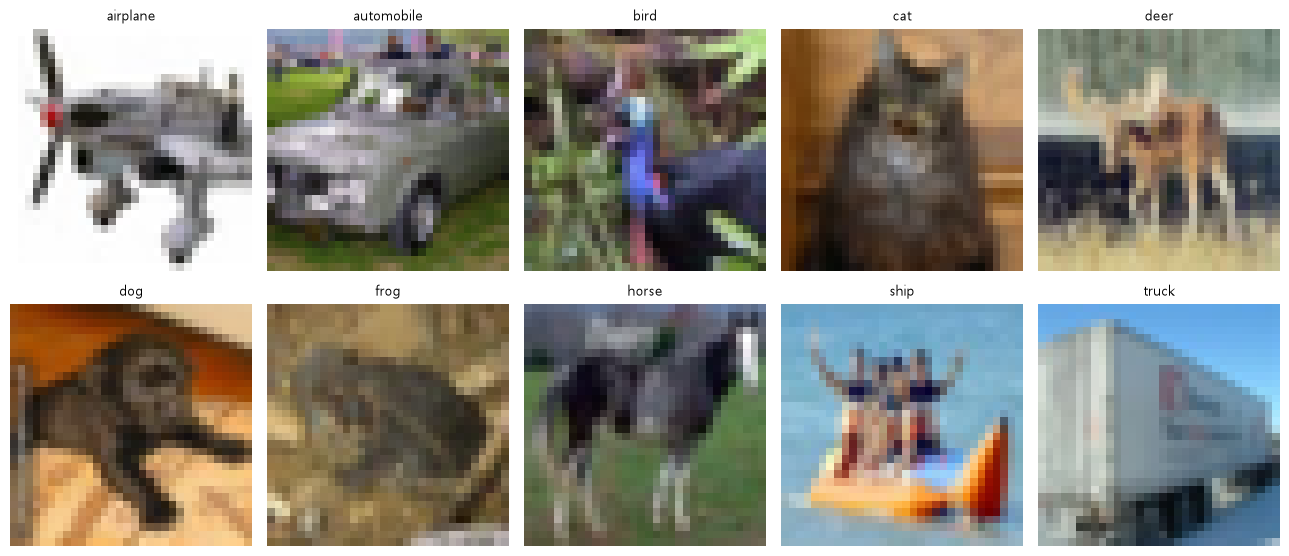

배경 · 각도 · 가림 정도는 장마다 다름 — 크기가 같다고 같은 조건은 아님


In [28]:
# 왜 · 같은 종류 안에서도 생김새가 다양하다는 것을 확인하기 위해
some = [int(np.where(targets == c)[0][3]) for c in range(len(CLASSES))]  # 종류마다 네 번째 장
grid([raw[i][0] for i in some], CLASSES, rows=2)                         # 다양함 보기
print("배경 · 각도 · 가림 정도는 장마다 다름 — 크기가 같다고 같은 조건은 아님")  # 관찰

**결과** · 예측 정답은 아님 — 장마다 다름

- `배경 · 각도 · 가림 정도는 장마다 다름 — 크기가 같다고 같은 조건은 아님` — 다양함이 곧 배울 거리
- 그림 · 첫 장 그림(1장)과 다른 사진 · 같은 종류도 모습이 다양

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>크기 · 형식</td><td>기계적으로 통일 가능</td><td>전처리</td></tr>
<tr><td>배경 · 각도</td><td>통일 불가 · 다양함</td><td>증강 · 데이터 수집</td></tr>
<tr><td>가림 · 일부만</td><td>단서가 부족한 사진</td><td>오류 분석</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 표본 열 장은 방향을 잡는 관찰 · 전체 검사가 아님
> - 모델이 배경을 단서로 삼을 수도 있음

> ✅ **한 줄 정리** · 크기가 같아도 배경 · 각도 · 가림은 장마다 달라서, 모델은 그 다양함 속의 공통점을 배워야 한다.

**딥러닝 코드에서는**

- 수집 단계에서 다양한 조건을 고르게 모으는 것이 증강보다 효과가 큰 경우가 많음
- 오류 분석 때 이 관찰이 원인 후보가 됨

### 8-3. `A` 증강과 나누는 순서 · `TF.hflip` · `TF.adjust_brightness` · `TF.rotate` <sub>원본 9장</sub>

> 🎯 **증강본을 먼저 만들고 나누면 왜 문제가 되는가?**

💡 **쉽게 말하면**

- 변형한 네 장은 다른 파일처럼 보여도 **원본 한 장**에서 나옴.
- 먼저 나누고, 학습 쪽에서만 만들어야 함.

**실행 흐름**

1. 원본 한 장으로 뒤집기 · 밝게 · 돌리기
2. 네 장 그리기
3. 두 순서의 결과 비교

**먼저 예측** · 먼저 만들고 나누면 검증에 무엇이 섞일까? — 답은 코드 실행 결과 아래에

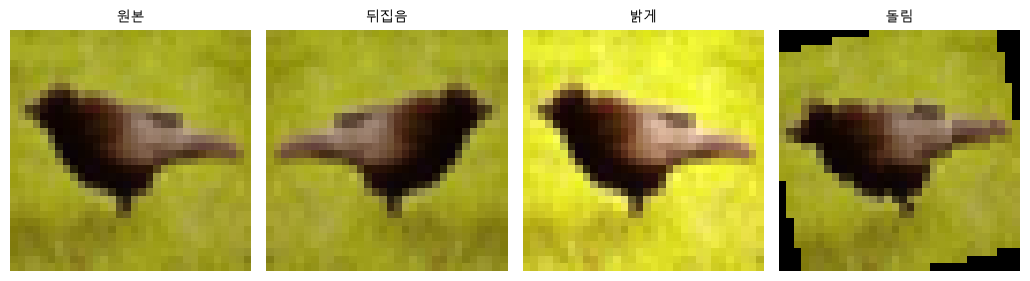

네 장은 서로 다른 파일처럼 보이지만 원본 한 장에서 나옴
먼저 만들고 나중에 나누면 → 같은 원본이 학습과 검증 양쪽에 들어감
먼저 나누고 학습 쪽에서만 만들면 → 검증은 본 적 없는 원본만 담음


In [29]:
# 왜 · 증강과 데이터 나누기의 순서가 왜 중요한지 같은 사진으로 보기 위해
base = raw[SHOW][0]                                                                    # 원본 한 장
copies = [base, TF.hflip(base), TF.adjust_brightness(base, 1.4), TF.rotate(base, 12)]  # 변형 셋
grid(copies, ["원본", "뒤집음", "밝게", "돌림"])                                       # 네 장
print("네 장은 서로 다른 파일처럼 보이지만 원본 한 장에서 나옴")                       # 같은 뿌리
print("먼저 만들고 나중에 나누면 → 같은 원본이 학습과 검증 양쪽에 들어감")             # 누수
print("먼저 나누고 학습 쪽에서만 만들면 → 검증은 본 적 없는 원본만 담음")              # 올바른 순서

**결과** · 예측 정답은 학습에 쓴 원본의 변형본

- `네 장은 서로 다른 파일처럼 보이지만 원본 한 장에서 나옴` — 같은 뿌리
- `먼저 만들고 나중에 나누면 → 같은 원본이 학습과 검증 양쪽에 들어감` — 누수 → 검증 점수 부풀림
- `먼저 나누고 학습 쪽에서만 만들면 → 검증은 본 적 없는 원본만 담음` — 올바른 순서

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>나누기 → 증강</td><td>검증은 처음 보는 원본만</td><td>올바른 순서</td></tr>
<tr><td>증강 → 나누기</td><td>같은 원본이 양쪽에</td><td>누수</td></tr>
<tr><td>꺼낼 때마다 증강</td><td>파일을 만들지 않음</td><td>가장 안전 (Dataset transform)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 증강본을 파일로 저장해 두면 이 실수가 생기기 쉬움
> - 사람 · 환자 · 영상 단위로도 같은 원리 (같은 뿌리는 한쪽에)

> ✅ **한 줄 정리** · 증강본은 원본 한 장에서 나오므로, 반드시 먼저 나누고 학습 쪽에서만 만들어야 검증이 처음 보는 사진으로 남는다.

**딥러닝 코드에서는**

- `train_ds = Subset(...)` 뒤에 transform을 붙이는 순서
- GroupKFold — 같은 뿌리를 한 묶음으로 나누는 방법

---
## 9. 바꿔도 정답이 같은 이미지인가

> **이 장의 흐름**
>
> - 정답이 그대로인 변환 → 알아보기 어려워지는 변환
> - 그다음 학습은 무작위 · 검증은 고정

<img src="images/pfcnn2_ch9.png" alt="허용할 변환과 제외할 변환" width="577">

**파이프라인 위치** · ⑨ 증강 고르기

### 9-1. `A` 허용할 변환 · `TF.resized_crop` · `hflip` <sub>원본 10장</sub>

> 🎯 **좌우 반전 · 밝기 조금 · 조금 자르기 뒤에도 정답 이름이 그대로인가?**

💡 **쉽게 말하면**

- 허용 기준 = 바뀐 뒤에도 **사람이 정답을 알아볼 수 있는가**.
- 조금 바뀐 모습은 실제 사진에도 흔함.

**실행 흐름**

1. 좌우 반전 · 밝기 1.25 · 2칸 잘라 다시 32칸
2. 네 장 그리기
3. 정답 확인

**먼저 예측** · 네 장 모두 새로 알아볼 수 있을까? — 답은 코드 실행 결과 아래에

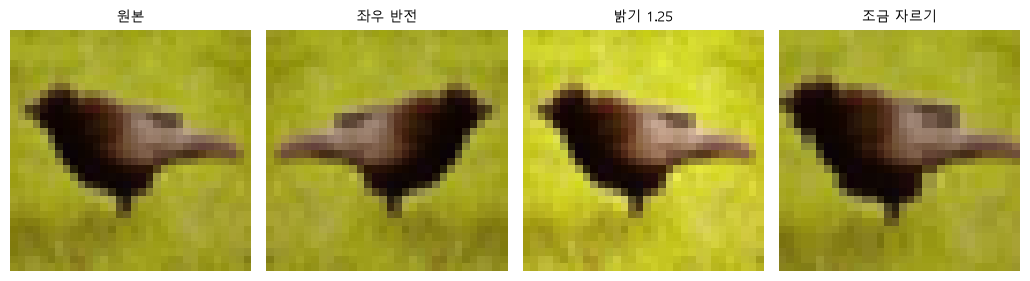

네 장 모두 정답 이름이 그대로임


In [30]:
# 왜 · 정답이 그대로인 변환만 골라 허용 목록을 만들기 위해
ok = [base, TF.hflip(base), TF.adjust_brightness(base, 1.25),  # 허용할 변환
      TF.resized_crop(base, 2, 2, 28, 28, [32, 32], interpolation=NEAREST)]
grid(ok, ["원본", "좌우 반전", "밝기 1.25", "조금 자르기"])    # 네 장
print("네 장 모두 정답 이름이 그대로임")                       # 단서가 남음

**결과** · 예측 정답은 그렇다 — 정답 그대로

- `네 장 모두 정답 이름이 그대로임` — 허용할 변환
- 그림 · 원본과 모습만 조금 다름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>좌우 반전</td><td>방향만 거울처럼</td><td>대부분의 사진</td></tr>
<tr><td>밝기 조금</td><td>조명 차이</td><td>실내 · 실외 사진</td></tr>
<tr><td>조금 자르기</td><td>구도 차이</td><td>대상이 가운데인 사진</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 허용 여부는 데이터마다 다름 · 글자 · 숫자의 좌우 반전은 위험
> - 세기를 조금씩 올려 보며 확인

> ✅ **한 줄 정리** · 바뀐 뒤에도 사람이 정답을 알아볼 수 있고 실제로도 흔한 모습이면 허용할 변환이다.

**딥러닝 코드에서는**

- `RandomHorizontalFlip()` · `ColorJitter(brightness=0.25)` · `RandomCrop(32, padding=2)`
- 파일별 1의 7장 `augment`가 같은 세 가지

### 9-2. `A` 제외할 변환 · `TF.rotate(base, 170)` · `adjust_brightness(0.1)` <sub>원본 10장</sub>

> 🎯 **170도 회전 · 밝기 0.1 · 6칸만 자르기는 왜 빼야 하는가?**

💡 **쉽게 말하면**

- 알아볼 수 없을 만큼 바꾸면 **틀린 것을 가르치는** 셈.
- 많이 넣을수록 좋은 것이 아님.

**실행 흐름**

1. 170도 돌리기 · 밝기 0.1 · 가운데 6칸 자르기
2. 네 장 그리기
3. 판단

**먼저 예측** · 6칸만 자른 사진에서 새를 알아볼 수 있을까? — 답은 코드 실행 결과 아래에

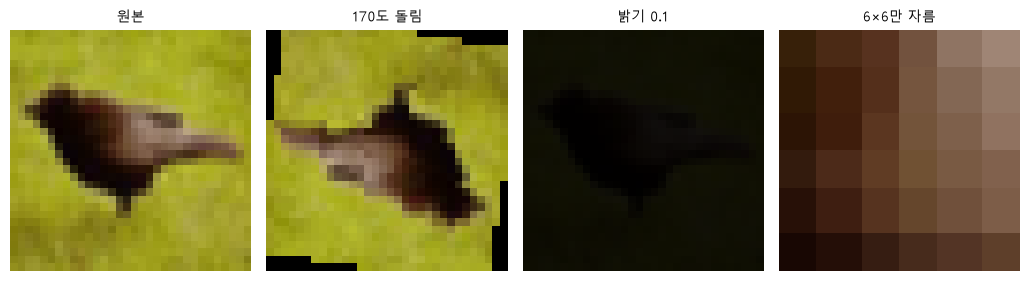

정답을 알아보기 어려워진 장이 있음 — 많이 넣을수록 좋은 것이 아님


In [31]:
# 왜 · 정답을 바꾸거나 정보를 지우는 변환을 빼야 하는 이유를 보기 위해
bad_aug = [base, TF.rotate(base, 170), TF.adjust_brightness(base, 0.1),     # 제외할 변환
           TF.resized_crop(base, 12, 12, 6, 6, [32, 32], interpolation=NEAREST)]
grid(bad_aug, ["원본", "170도 돌림", "밝기 0.1", "6×6만 자름"])             # 네 장
print("정답을 알아보기 어려워진 장이 있음 — 많이 넣을수록 좋은 것이 아님")  # 단서가 사라짐

**결과** · 예측 정답은 어려움 — 단서가 사라짐

- `정답을 알아보기 어려워진 장이 있음 — 많이 넣을수록 좋은 것이 아님` — 제외할 변환
- 그림 · 밝기 0.1은 거의 검정 · 6칸은 색 덩어리

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>큰 회전</td><td>거꾸로 · 실제로 드묾</td><td>위성 · 현미경 사진만 예외</td></tr>
<tr><td>아주 어둡게</td><td>단서 사라짐</td><td>빼기</td></tr>
<tr><td>아주 작게 자르기</td><td>대상이 사라짐</td><td>빼기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사람도 판단 못 하면 모델에 정답을 붙여 보여 주지 않음
> - 제외 이유를 한 줄로 기록 (무엇이 정답을 가르는가)

> ✅ **한 줄 정리** · 사람도 정답을 알아볼 수 없을 만큼 바꾸는 변환은 틀린 것을 가르치므로 제외한다.

**딥러닝 코드에서는**

- `RandomRotation(15)`처럼 범위를 작게
- 증강 결과를 격자로 그려 확인한 뒤 학습

### 9-3. `A` 학습은 무작위 · 검증은 고정 · `np.random.randint` · `tobytes()` <sub>원본 10장</sub>

> 🎯 **학습 쪽과 검증 쪽의 전처리는 왜 달라야 하는가?**

💡 **쉽게 말하면**

- 학습 = 무작위 변환 · **매번 다른 그림**.
- 검증 = 무작위 없음 · **같은 그림**이어야 점수를 비교할 수 있음.

**실행 흐름**

1. 규칙 두 줄 출력
2. 검증 전처리를 세 번 적용 → 같은가
3. 학습 증강(무작위 회전) 세 번 → 몇 가지인가

**먼저 예측** · 무작위 회전을 세 번 하면 그림은 몇 가지일까? — 답은 코드 실행 결과 아래에

In [32]:
# 왜 · 학습은 무작위로 · 검증은 고정으로 두는 이유를 확인하기 위해
print("학습 쪽 — 무작위 변환을 넣음 · 매번 다른 그림이 나옴")                 # 증강
print("검증 쪽 — 무작위 변환을 넣지 않음 · 같은 그림이 나와야 점수를 비교할 수 있음")  # 고정
same = all(np.array_equal(np.array(base), np.array(base)) for _ in range(3))  # 검증 전처리 세 번
# 무작위 세 번
diff = len({TF.rotate(base, int(np.random.randint(-15, 16))).tobytes() for _ in range(3)})
print(f"검증 전처리를 세 번 적용한 결과가 모두 같은가 {same}")                # True
print(f"학습 증강을 세 번 적용하면 서로 다른 그림 {diff}가지")                # 매번 다름

학습 쪽 — 무작위 변환을 넣음 · 매번 다른 그림이 나옴
검증 쪽 — 무작위 변환을 넣지 않음 · 같은 그림이 나와야 점수를 비교할 수 있음
검증 전처리를 세 번 적용한 결과가 모두 같은가 True
학습 증강을 세 번 적용하면 서로 다른 그림 3가지


**결과** · 예측 정답은 3가지 — 매번 다름

- `검증 전처리를 세 번 적용한 결과가 모두 같은가 True` — 같은 사진 · 같은 점수
- `학습 증강을 세 번 적용하면 서로 다른 그림 3가지` — 같은 사진도 매번 새 모습

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>학습 transform</td><td>무작위 증강 포함</td><td>여러 모습으로 연습</td></tr>
<tr><td>검증 transform</td><td>고정 (Resize · Normalize만)</td><td>점수 비교 · 모델 고르기</td></tr>
<tr><td>테스트 transform</td><td>검증과 같음</td><td>마지막 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 검증에 무작위 증강이 남으면 잴 때마다 점수가 달라짐 (파일별 1의 14장 고장 2)
> - 무작위 변환도 seed를 고정하면 다시 만들 수 있음

> ✅ **한 줄 정리** · 학습 쪽은 무작위 변환으로 매번 다른 그림을 보여 주고, 검증 쪽은 고정된 전처리로 늘 같은 그림을 써야 점수를 비교할 수 있다.

**딥러닝 코드에서는**

- `train_tf` · `val_tf`를 따로 만들어 Dataset에 각각 넘김
- TTA(test-time augmentation)는 예외적으로 평가에서 여러 모습의 평균을 냄

---
## 10. 첫 실험을 다시 설명하기

> **이 장의 흐름**
>
> - 일반 흐름과 우리 경우를 한 줄씩
> - 그다음 정규화 하나만 바꿔 같은 조건으로 다시 학습

<img src="images/pfcnn2_ch10.png" alt="데이터에서 예측까지 한 줄" width="800">

**파이프라인 위치** · ⑩ 정리 · 한 조건만 바꾼 비교

### 10-1. `A` 데이터 → 입력 → 예측을 한 줄로 · `print` <sub>원본 11장</sub>

> 🎯 **오늘 한 일을 데이터 폴더에서 예측까지 한 줄로 말하면?**

💡 **쉽게 말하면**

- 일반 흐름 · 데이터 → 읽기 → 크기 → 값 범위 → 배치 → 모델 → 예측.
- 우리 경우를 같은 칸에 채워 봄.

**실행 흐름**

1. 일반 흐름 한 줄
2. 우리 경우 한 줄
3. 지금까지의 점수

**먼저 예측** · 우리 경우 크기 맞추기 칸에는 무엇이 들어갈까? — 답은 코드 실행 결과 아래에

In [33]:
# 첫 실험을 한 줄로 설명하기
# 왜 · 데이터 → 입력 → 예측 흐름을 한 줄로 설명할 수 있는지 확인하기 위해
# 일반 흐름
print("데이터 폴더 → 한 장 읽기 → 크기 맞추기 → 값 범위 맞추기 → 배치로 묶기 → 모델 → 예측")
# 우리 실습에 대입
print(f"우리 경우 → CIFAR-10 → {arr.shape[0]}×{arr.shape[1]} 그대로 → 0–1로 줄임"
      f" → {tuple(Xtr[:32].shape)} → 작은 CNN → {len(CLASSES)}개 중 하나")
print(f"지금까지의 점수 — 단순 기준 {const_acc * 100:.1f}% · "  # 정리
      f"3번 학습 뒤 {hist[-1] * 100:.1f}%")

데이터 폴더 → 한 장 읽기 → 크기 맞추기 → 값 범위 맞추기 → 배치로 묶기 → 모델 → 예측
우리 경우 → CIFAR-10 → 32×32 그대로 → 0–1로 줄임 → (32, 3, 32, 32) → 작은 CNN → 10개 중 하나
지금까지의 점수 — 단순 기준 10.0% · 3번 학습 뒤 32.4%


**결과** · 예측 정답은 32×32 그대로 (모두 같은 크기라서)

- `데이터 폴더 → 한 장 읽기 → 크기 맞추기 → 값 범위 맞추기 → 배치로 묶기 → 모델 → 예측` — 일반 흐름
- `CIFAR-10 → 32×32 그대로 → 0–1로 줄임 → (32, 3, 32, 32) → 작은 CNN → 10개 중 하나` — 우리 경우
- `지금까지의 점수 — 단순 기준 10.0% · 3번 학습 뒤 32.4%` — 기준선과 함께

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>크기 칸</td><td>Resize · Crop</td><td>크기가 다른 사진</td></tr>
<tr><td>값 칸</td><td>to_tensor · Normalize</td><td>모든 경우</td></tr>
<tr><td>배치 칸</td><td>DataLoader</td><td>모든 경우</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 칸 하나라도 학습 때와 예측 때가 다르면 결과가 무너짐
> - 점수는 늘 기준선과 함께 말함

> ✅ **한 줄 정리** · 첫 실험은 데이터 → 읽기 → 크기 → 값 범위 → 배치 → 모델 → 예측 한 줄로 설명되며, 이 칸들이 곧 입력 약속이다.

**딥러닝 코드에서는**

- 새 프로젝트를 시작할 때 이 한 줄을 먼저 적어 두면 빠뜨림이 줄어듦
- 예측 코드도 같은 칸 순서로 작성

### 10-2. `A` 전처리 하나만 바꿔 비교 · `train_fresh` · `TF.normalize` <sub>원본 11장</sub>

> 🎯 **초기값 · 분할 · 학습량은 그대로 두고 정규화만 더하면 검증 정확도는 달라지는가?**

💡 **쉽게 말하면**

- 바꾼 조건은 **전처리 하나** · 나머지는 모두 같게.
- 그래야 차이를 정규화 때문이라고 말할 수 있음.

**실행 흐름**

1. 같은 시작값 · 같은 모양 · 같은 학습으로 새로 학습하는 함수
2. 0–1만 · 정규화까지 두 묶음
3. 두 번 학습해 검증 정확도 비교

**먼저 예측** · 정규화를 더하면 검증 정확도가 오를까? — 답은 코드 실행 결과 아래에

In [34]:
# 왜 · 전처리 하나만 바꾸고 나머지는 같게 해 공정하게 비교하기 위해
def train_fresh(Xtr_, epochs=3):                    # 같은 조건으로 새로 학습 (입력만 바꿔 넣음)
    torch.manual_seed(42)                           # 같은 시작값 · 같은 섞기
    m = nn.Sequential(                              # 2장과 같은 모양
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 8 * 8, len(CLASSES)),
    )
    o = torch.optim.Adam(m.parameters(), lr=1e-3)   # 같은 학습률
    for _ in range(epochs):                         # 같은 에폭
        m.train()                                   # 학습 모드
        p = torch.randperm(len(Xtr_))               # 섞기
        for i in range(0, len(Xtr_), 32):           # 32장씩
            bb = p[i:i + 32]                        # 묶음
            o.zero_grad()                           # 지우기
            lossf(m(Xtr_[bb]), ytr[bb]).backward()  # 기울기
            o.step()                                # 한 걸음
    return m                                        # 학습된 모델


# 왜 · 정규화 유무만 다른 두 학습을 같은 조건에서 비교하기 위해
Xtr_norm = torch.stack([TF.normalize(x.clone(), MEAN, STD) for x in Xtr])  # 정규화한 학습 묶음
Xva_norm = torch.stack([TF.normalize(x.clone(), MEAN, STD) for x in Xva])  # 검증도 같은 변환
a_plain = accuracy(train_fresh(Xtr), Xva, yva)                             # 0–1만
a_norm = accuracy(train_fresh(Xtr_norm), Xva_norm, yva)                    # 정규화까지
print(f"0–1만 적용 검증 정확도 {a_plain * 100:.1f}%")                      # 비교 1
print(f"정규화까지 적용 검증 정확도 {a_norm * 100:.1f}%")                  # 비교 2
print("바꾼 조건은 전처리 하나 · 초기값 · 분할 · 학습량은 같음")           # 통제된 비교

0–1만 적용 검증 정확도 32.4%
정규화까지 적용 검증 정확도 38.4%
바꾼 조건은 전처리 하나 · 초기값 · 분할 · 학습량은 같음


**결과** · 예측 정답은 오름 — 32.4% → 38.4%

- `0–1만 적용 검증 정확도 32.4%` — 2장 결과와 같음 (같은 시작값 · 같은 학습)
- `정규화까지 적용 검증 정확도 38.4%` — +6.0%p
- `바꾼 조건은 전처리 하나 · 초기값 · 분할 · 학습량은 같음` — 통제된 비교

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>한 조건만 바꿈</td><td>차이의 원인을 말할 수 있음</td><td>효과 확인</td></tr>
<tr><td>여러 조건을 한꺼번에</td><td>무엇 덕인지 모름</td><td>피함</td></tr>
<tr><td>시작값 여러 개로 반복</td><td>우연인지 확인</td><td>결론 전 (파일별 1의 8-4)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 한 번의 비교 · 시작값 하나 · 1000장 3에폭 → 방향만 봄
> - 검증에도 학습과 같은 정규화를 넣어야 함 (`Xva_norm`)

> ✅ **한 줄 정리** · 정규화 하나만 바꾼 통제된 비교에서 검증 정확도가 32.4%에서 38.4%로 올랐고, 다른 조건이 같으니 정규화의 효과라고 말할 수 있다.

**딥러닝 코드에서는**

- 실험 기록 · 바꾼 것 · 같게 둔 것 · 결과 세 줄
- 파일별 1의 8장이 같은 생각을 증강으로 크게 한 실험

---
## 11. 종합 실습 · 새 사진 한 장 · 처리 하나의 효과

> **이 장의 흐름**
>
> - 학습 · 검증 밖의 새 사진 한 장을 처음부터 끝까지 → 상위 3 확률
> - 그다음 검증 사진 전체를 흐리게 해서 같은 모델 점수 비교

<img src="images/pfcnn2_practice.png" alt="종합 실습 두 가지" width="577">

**파이프라인 위치** · ① ~ ⑩ 전체 (읽기 → 크기 → 값 → 배치 → 모델 → 예측 · 한 조건만 바꾸기)

> 🎯 **새 사진 예측과 흐리기 실험에서 오늘 배운 것을 어디에 쓰는가?**

💡 **쉽게 말하면**

- 새 사진도 **학습 때와 같은 약속**(to_tensor · 배치 축)으로 넣어야 함.
- 모델은 그대로 두고 **입력 처리 하나만** 바꿔 점수를 잼.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>① 읽기</td><td>학습 · 검증 밖의 말 사진 한 장</td><td><code>raw[new_i][0]</code></td></tr>
<tr><td>② ~ ④ 크기 · 값 · 배치</td><td>32칸 그대로 · 0 ~ 1 · 장수 축</td><td><code>TF.to_tensor</code> · <code>unsqueeze(0)</code></td></tr>
<tr><td>⑤ 예측</td><td>확률 10개 → 상위 3</td><td><code>softmax</code> · <code>topk(3)</code></td></tr>
<tr><td>⑥ 처리 하나의 효과</td><td>검증 전체를 흐리기 0 · 1 · 2</td><td><code>GaussianBlur</code> · <code>accuracy</code></td></tr>
</tbody></table>

**먼저 예측** · 흐리기 2를 넣으면 검증 정확도는 32.4%에서 얼마나 떨어질까? — 답은 코드 실행 결과 아래에

In [35]:
# 종합 실습 1 — 새 사진 한 장을 처음부터 끝까지 (읽기 → 크기 → 값 → 배치 → 모델 → 예측)
# 왜 · 새 사진도 같은 순서로 모델 입력까지 만들 수 있는지 확인하기 위해
# 학습 · 검증 밖의 말
new_i = int(np.where(targets == CLASSES.index("horse"))[0][PER_TRAIN + PER_VAL])
pil = raw[new_i][0]                 # ① 한 장 읽기 (PIL · 32×32)
x = TF.to_tensor(pil)               # ② 크기 그대로 · ③ 0~1 · (3, 32, 32)
xb = x.unsqueeze(0)                 # ④ 배치 축 (1, 3, 32, 32)
small.eval()                        # 평가 모드
with torch.no_grad():               # 예측만
    prob = small(xb).softmax(1)[0]  # ⑤ 모델 → 확률 10개
k3 = prob.topk(3)                   # 큰 세 종류
print(f"새 사진 {new_i}번 · 정답 {CLASSES[raw[new_i][1]]} · 입력 모양 {tuple(xb.shape)}")  # 확인
# 이름 확률
top = " · ".join(f"{CLASSES[int(c)]} {float(p):.2f}" for p, c in zip(k3.values, k3.indices))
print("예측 상위 3 — " + top)       # 확률이 큰 세 종류

새 사진 1543번 · 정답 horse · 입력 모양 (1, 3, 32, 32)
예측 상위 3 — dog 0.27 · deer 0.18 · frog 0.15


**실행 흐름**

1. 검증 묶음 전체를 흐리게 하는 함수 정의
2. 흐리기 0 · 1 · 2마다 같은 모델로 검증 정확도 출력

In [36]:
# 종합 실습 2 — 이미지 처리 하나를 검증 사진 전체에 넣으면 점수는? (모델은 그대로)
# 왜 · 모델은 그대로 두고 입력 처리만 바꿀 때 점수가 어떻게 변하는지 보기 위해
def blur_all(X, radius):           # 검증 묶음 전체를 흐리게
    out = []                       # 흐린 사진들
    for x in X:                    # 한 장씩
        pil_ = TF.to_pil_image(x)  # 텐서 → PIL
        out.append(TF.to_tensor(pil_.filter(ImageFilter.GaussianBlur(radius))))  # 흐려서 다시 텐서
    return torch.stack(out)        # 묶음


for radius in (0, 1, 2):                                                           # 흐리기 세기
    Xb = Xva if radius == 0 else blur_all(Xva, radius)                             # 0이면 원본
    print(f"흐리기 {radius} → 검증 정확도 {accuracy(small, Xb, yva) * 100:.1f}%")  # 점수 변화

흐리기 0 → 검증 정확도 32.4%


흐리기 1 → 검증 정확도 28.0%


흐리기 2 → 검증 정확도 25.2%


**결과** · 예측 정답은 25.2% — 7.2%p 떨어짐

- `새 사진 1543번 · 정답 horse · 입력 모양 (1, 3, 32, 32)` — 학습 · 검증에 없는 사진 · 배치 축 1
- `예측 상위 3 — dog 0.27 · deer 0.18 · frog 0.15` — 3에폭 모델은 망설이며 틀림 · 정답 말은 상위 3에 없음
- `흐리기 1 → 검증 정확도 28.0%` — 경계 단서가 무뎌지자 떨어짐
- `흐리기 2 → 검증 정확도 25.2%` — 셀수록 더 떨어짐 · 모델은 경계 단서를 씀

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>새 사진 예측</td><td>같은 입력 약속으로 한 장</td><td>서비스 · 데모</td></tr>
<tr><td>처리 하나의 효과</td><td>모델 고정 · 입력만 바꿈</td><td>약점 찾기 (흔들기)</td></tr>
<tr><td>다음 실험</td><td>흐린 사진을 증강으로 학습</td><td>약점 고치기 (통제된 비교)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 3에폭 1000장 모델 · 점수보다 실험의 틀을 익히는 것이 목표
> - 흐리기 실험은 검증 사진 · 테스트는 마지막 확인에만

> ✅ **한 줄 정리** · 새 사진도 학습 때와 같은 입력 약속으로 넣어야 하며, 모델을 고정하고 입력 처리 하나만 바꾸면 그 처리가 점수에 주는 영향을 잴 수 있다.

**딥러닝 코드에서는**

- `model.eval(); with torch.no_grad(): model(tf(img)[None]).softmax(1)` — 한 장 예측의 기본 줄
- 흐림 · 밝기 같은 '흔든 검증 세트'로 배포 전 약점 점검

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>입력 · 정답 · 예측 · 기준선</td><td>열 종류 분류 · 기준선 10% · 첫 학습 32.4%</td><td>1 · 2장</td></tr>
<tr><td>배열 → 배치 텐서</td><td>HWC → CHW → NCHW · to_tensor 세 단계 · 에러 맨 아래 줄</td><td>3 · 4장</td></tr>
<tr><td>크기 · 값 범위</td><td>늘리기는 정보를 늘리지 않음 · 자르기는 가장자리 버림 · 정규화는 채널마다</td><td>5 · 6장</td></tr>
<tr><td>커널 처리</td><td>아홉 칸 합 1 → 밝기 유지 · 0 → 경계만</td><td>7장</td></tr>
<tr><td>증강 · 나누기</td><td>허용 · 제외 · 나누기 → 증강 · 학습 무작위 · 검증 고정 · 한 조건 비교</td><td>8 ~ 10장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td>A</td><td>기준선</td><td>가장 많은 종류만 답할 때 정확도</td><td>점수는 늘 기준선과 함께</td></tr>
<tr><td>A</td><td>NCHW</td><td>(장수, 채널, 세로, 가로)</td><td><code>x.unsqueeze(0)</code></td></tr>
<tr><td>A</td><td><code>to_tensor</code></td><td>축 옮기기 + float + ÷ 255</td><td><code>transforms.ToTensor()</code></td></tr>
<tr><td>A</td><td>정규화</td><td>(x - 평균) ÷ 표준편차 · 채널마다</td><td><code>Normalize(mean, std)</code></td></tr>
<tr><td>A</td><td>나누기 → 증강</td><td>같은 원본이 양쪽에 가지 않게</td><td>transform은 학습 Dataset에만</td></tr>
<tr><td>B</td><td>NEAREST · BILINEAR</td><td>복사 · 섞음</td><td>마스크는 NEAREST</td></tr>
<tr><td>B</td><td>커널</td><td>아홉 칸 곱해 더하기</td><td><code>nn.Conv2d</code>가 배우는 것</td></tr>
<tr><td>B</td><td>에러 읽기</td><td>맨 아래 줄부터</td><td>Linear 입력 길이 → Flatten 앞 shape</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-2** · 종류가 고른 열 종류 문제의 기준선은?
- **2-2** · 3에폭 학습 뒤 검증 정확도와 기준선의 관계는?
- **3-1** · 32×32 컬러 사진 한 장의 숫자 개수와 값 범위는?
- **4-1** · 넘파이 사진 배열과 모델 입력의 모양 차이는?
- **4-3** · `to_tensor`가 하는 세 가지는?
- **4-4** · 긴 에러 메시지는 어디부터 읽는가?
- **5-2** · 최근접과 선형으로 늘리면 색 개수는?
- **5-3** · 가운데 잘라 늘리기와 그대로 늘리기의 차이는?
- **6-1** · 세 채널이 모두 0.5일 때 정규화 결과가 다른 이유는?
- **7-2** · 커널 아홉 칸 합이 0이면 평탄한 자리 결과는?
- **8-3** · 증강본을 먼저 만들고 나누면 생기는 문제는?
- **9-3** · 검증 전처리에 무작위 변환을 넣으면 안 되는 이유는?
- **10-2** · 정규화 효과를 말할 수 있는 조건은?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**9-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**10-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. (4, 4, 3) 크기 uint8 배열을 직접 (3, 4, 4) float32 · 0 ~ 1 텐서로 바꾸고 최댓값을 출력
2. 3 × 3 창 `[[0, 0, 0], [0, 9, 0], [0, 0, 0]]`에 흐리기(1/9) · 경계(가운데 8 · 나머지 -1) 커널을 대어 결과 출력

In [37]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 1번에서 배치 축까지 붙인 모양을 출력
2. 2번 창이 모두 5일 때 두 커널 결과를 다시 계산

In [38]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-2** · 10% · 한 이름만 답해도 · 무작위로 찍어도 같음
- **2-2** · 32.4%로 기준선 10%의 약 세 배
- **3-1** · 3072개 · 0 ~ 255 정수(uint8)
- **4-1** · (H, W, C) vs (N, C, H, W)
- **4-3** · 읽은 배열의 축을 옮기고 · 실수로 바꾸고 · 255로 나눔
- **4-4** · 맨 아래 줄 (오류 종류와 이유)
- **5-2** · 최근접은 원본과 같고 · 선형은 중간색이 생겨 많아짐
- **5-3** · 자르기는 가장자리 픽셀을 버리고 · 늘리기는 버리지 않음
- **6-1** · 채널마다 평균 · 표준편차가 달라서
- **7-2** · 0에 가까워짐 · 경계만 남음
- **8-3** · 같은 원본이 학습과 검증 양쪽에 들어가 점수가 부풀려짐
- **9-3** · 잴 때마다 점수가 달라져 비교 · 선택을 못 함
- **10-2** · 초기값 · 분할 · 학습량을 같게 두고 전처리 하나만 바꿈

#### 코드 문제 답

```python
import torch  # 텐서

a = torch.arange(48, dtype=torch.uint8).reshape(4, 4, 3) * 5  # (H, W, C) · 0 ~ 235
t = a.permute(2, 0, 1).float() / 255  # (C, H, W) · 0 ~ 1
print(tuple(t.shape), t.dtype)  # (3, 4, 4) torch.float32
print(round(t.max().item(), 3))  # 0.922
win = torch.tensor([[0., 0, 0], [0, 9, 0], [0, 0, 0]])  # 가운데만 튄 창
blur = torch.ones(3, 3) / 9  # 흐리기
edge = -torch.ones(3, 3)  # 경계 커널
edge[1, 1] = 8  # 가운데 8
print(round((win * blur).sum().item(), 2), (win * edge).sum().item())  # 1.0 72.0
```

#### 변형 문제 답

*문제 → 답*

- **1번 배치 축** · `t.unsqueeze(0).shape` → (1, 3, 4, 4)
- **2번 창이 모두 5** · 흐리기 5.0 · 경계 0.0 (합이 0인 커널은 평탄한 자리에서 0)

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>예: 배치 축 없이 넣어 오류</td><td>한 장도 묶음으로 넣어야 한다는 것을 잊음</td><td>모델 입력은 늘 NCHW</td><td>넣기 전에 <code>x.shape</code>의 첫 숫자가 장수인가?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 이미지를 모델에 넣기 전에 무엇을 맞춥니까?**
> - 크기와 값 범위와 축 순서를 맞춥니다.
> - 사진 파일은 (H, W, C) 0 ~ 255 정수라서 to_tensor로 (C, H, W) 0 ~ 1 실수로 바꾸고 배치 축을 붙입니다.
> - 필요하면 채널마다 평균과 표준편차로 정규화하고, 같은 처리를 예측 때도 그대로 씁니다.

**Q2. 정규화는 왜 합니까?**
> - 값의 가운데를 0 근처로 옮기고 폭을 맞춰 첫 층 계산이 너무 커지지 않게 합니다.
> - 이 실습에서는 정규화 하나만 바꿨을 때 검증 정확도가 32.4%에서 38.4%로 올랐습니다.
> - pretrained 모델은 그 모델이 학습 때 쓴 값을 그대로 써야 합니다.

**Q3. 증강은 어떻게 고르고 어디에 넣습니까?**
> - 바뀐 뒤에도 사람이 정답을 알아볼 수 있는 변환만 고릅니다.
> - 데이터를 먼저 나눈 뒤 학습 쪽 Dataset에서 꺼낼 때마다 무작위로 넣고, 검증은 고정된 전처리만 씁니다.
> - 그래야 같은 원본이 양쪽에 들어가지 않고 점수를 비교할 수 있습니다.

**Q4. 첫 학습 결과는 어떻게 읽습니까?**
> - 기준선부터 정합니다.
> - 종류가 고른 열 종류 문제는 한 이름만 답해도 10%입니다.
> - 3에폭 뒤 32.4%는 기준선의 세 배라 학습이 된 것이고, 그다음 틀린 사진을 종류마다 꺼내 봅니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>CIFAR10(root, train, download)</code></td><td>torchvision.datasets</td><td>PIL 사진 · 정답 데이터</td><td>0장 준비</td></tr>
<tr><td><code>np.bincount</code></td><td>numpy</td><td>종류별 장수 → 기준선</td><td>1-2</td></tr>
<tr><td><code>TF.to_tensor</code></td><td>torchvision.transforms.functional</td><td>HWC uint8 → CHW float 0~1</td><td>2-1 · 4-1 · 4-3</td></tr>
<tr><td><code>torch.stack</code> · <code>unsqueeze(0)</code></td><td>torch</td><td>묶음 만들기 · 배치 축</td><td>2-1 · 4-1</td></tr>
<tr><td><code>nn.Sequential</code> · <code>Conv2d</code> · <code>MaxPool2d</code></td><td>torch.nn</td><td>작은 CNN</td><td>2-1</td></tr>
<tr><td><code>torch.optim.Adam</code> · <code>CrossEntropyLoss</code></td><td>torch</td><td>학습 · 손실</td><td>2-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>TF.to_grayscale</code> · <code>convert('HSV')</code></td><td>torchvision · PIL</td><td>회색조 · 색공간</td><td>3-3</td></tr>
<tr><td><code>np.clip</code> · <code>astype(np.int16)</code></td><td>numpy</td><td>넘침 없이 밝기 바꾸기</td><td>3-4</td></tr>
<tr><td><code>TF.resize(interpolation=)</code></td><td>torchvision</td><td>늘리기 · 줄이기 (NEAREST · BILINEAR)</td><td>3-5 · 5-2</td></tr>
<tr><td><code>traceback.format_exc</code></td><td>traceback</td><td>에러 메시지 줄 목록</td><td>4-4</td></tr>
<tr><td><code>TF.center_crop</code> · <code>resized_crop</code></td><td>torchvision</td><td>자르기</td><td>5-3 · 9-1</td></tr>
<tr><td><code>TF.normalize</code></td><td>torchvision</td><td>채널별 정규화</td><td>6-1 · 10-2</td></tr>
<tr><td><code>sliding_window_view</code></td><td>numpy</td><td>3×3 창 모음</td><td>7-1</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>ImageFilter.MedianFilter</code> · <code>GaussianBlur</code></td><td>PIL</td><td>잡음 지우기 · 흐리기</td><td>7-3 ~ 7-5 · 11장</td></tr>
<tr><td><code>TF.hflip</code> · <code>adjust_brightness</code> · <code>rotate</code></td><td>torchvision</td><td>증강 변환</td><td>8-3 · 9장</td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>점수는 기준선과 함께 말함</td><td>정확도 숫자만 보고 판단</td></tr>
<tr><td>입력 약속(크기 · 값 · 축 · 배치)을 학습과 예측에 똑같이</td><td>예측 때 정규화 빠뜨리기</td></tr>
<tr><td>먼저 나누고 학습 쪽에서만 증강</td><td>증강본을 만들고 나누기</td></tr>
<tr><td>한 조건만 바꿔 비교</td><td>여러 조건을 한꺼번에 바꾸기</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>HWC vs CHW</td><td>채널이 뒤 · 앞</td><td>넘파이 · 그리기는 HWC · 모델은 CHW</td></tr>
<tr><td>NEAREST vs BILINEAR</td><td>복사 · 섞음</td><td>마스크는 NEAREST · 사진은 BILINEAR</td></tr>
<tr><td>Resize vs CenterCrop</td><td>찌그러짐 가능 · 가장자리 버림</td><td>보통 Resize 후 CenterCrop</td></tr>
<tr><td>0–1 vs 정규화</td><td>범위만 · 가운데 0</td><td>pretrained는 정규화 필수</td></tr>
<tr><td>학습 transform vs 검증 transform</td><td>무작위 · 고정</td><td>검증에 무작위 금지</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1 · 오답 노트 재발 방지 질문</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>4장 · 6장 코드를 보지 않고 다시 작성</td><td>20분</td></tr>
<tr><td>1주 뒤</td><td>파일별 1(강의) 2 · 7장과 연결해 읽기</td><td>30분</td></tr>
<tr><td>2주 뒤</td><td>종합 실습을 다른 사진 · 다른 처리로 다시</td><td>20분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 `02_이미지분류_Day01.ipynb` 47셀을 장 순서 그대로 섹션으로 나눔 · 원본 파일은 수정하지 않음
- 원본 코드는 그대로 두고 오른쪽 한글 주석 · 제목 한글화만 함 (그림 제목만 한글)
- 학습 시간 출력은 실행마다 달라 '1분 안에 끝났나'로 바꿈
- 종합 실습(11장)은 새로 만든 두 실험 · 모범 답안은 노트북 전체를 다시 돌리지 않고 혼자 실행되게 작성
- 생성 도구 · `notebook-tools/파일별정리/cnn/` (cnn2_code.py · cnn_2.py · build_cnn.py · verify_cnn.py)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>0. 준비</td><td>데이터 · 고정 부분집합 · 그림 함수</td><td>0장 준비 두 셀</td></tr>
<tr><td>1 ~ 2</td><td>무엇을 맞히나 · 단순 기준</td><td>1장</td></tr>
<tr><td>3</td><td>작은 CNN 짧게 학습 (셀 3개)</td><td>2장</td></tr>
<tr><td>4</td><td>사진은 숫자 배열 (셀 5개)</td><td>3장</td></tr>
<tr><td>5</td><td>배열에서 배치 텐서까지 (셀 4개)</td><td>4장</td></tr>
<tr><td>6</td><td>화면 크기와 실제 크기 (셀 5개)</td><td>5장</td></tr>
<tr><td>7</td><td>값의 범위 맞추기</td><td>6장</td></tr>
<tr><td>8</td><td>이미지 처리 (셀 5개)</td><td>7장</td></tr>
<tr><td>9</td><td>어떤 데이터를 쓰는가 (셀 3개)</td><td>8장</td></tr>
<tr><td>10</td><td>바꿔도 정답이 같은가 (셀 3개)</td><td>9장</td></tr>
<tr><td>11</td><td>첫 실험 다시 설명 (셀 2개)</td><td>10장</td></tr>
<tr><td>—</td><td>새로 추가</td><td>11장 종합 실습</td></tr>
</tbody></table>

### 전체 코드

0. 준비 ~ 11장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 0. 준비 1 — 도구 · 데이터 불러오기

In [39]:
# ---------- 0. 준비 1 ----------
# 왜 · OpenMP 설정과 학습 시간 재기에 쓸 도구를 먼저 불러오기 위해
import os    # 환경 변수
import time  # 학습 시간 재기

# 왜 · 사진을 숫자 · 그림으로 함께 확인하기 위해
import matplotlib.pyplot as plt                       # 그림
import numpy as np                                    # 배열
import torch                                          # 텐서 · 모델
import torch.nn as nn                                 # 층
import torchvision.transforms.functional as TF        # PIL 사진 변환 함수
from torchvision.datasets import CIFAR10              # 사진 10종
from torchvision.transforms import InterpolationMode  # 크기 바꿀 때 채우는 방법

# 왜 · torch와 matplotlib을 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # torch · matplotlib OpenMP 충돌 방지
NEAREST = InterpolationMode.NEAREST                                       # 가장 가까운 칸을 복사
BILINEAR = InterpolationMode.BILINEAR                                     # 이웃 칸을 섞어 채움
plt.rcParams.update({"font.family": "Malgun Gothic", "font.size": 10,     # 그림 글꼴 10pt
                     "axes.titlesize": 12, "axes.unicode_minus": False})  # 제목 12pt
torch.manual_seed(42)                                                     # 원본과 같은 seed
np.random.seed(42)                                                        # numpy 난수도 고정

# 왜 · 처음 한 번만 내려받고 그다음부터는 data/에 저장된 파일을 그대로 쓰기 위해
raw = CIFAR10(root="data", train=True, download=True)          # 학습 파일 5만 장 (PIL 사진 · 정답)
CLASSES = raw.classes                                          # 종류 이름 10개
targets = np.array(raw.targets)                                # 정답 번호 배열
PER_TRAIN, PER_VAL = 100, 50                                   # 종류마다 학습 100 · 검증 50
tr_idx, va_idx = [], []                                        # 고정 부분집합 번호
for c in range(len(CLASSES)):                                  # 종류마다
    where = np.where(targets == c)[0]                          # 그 종류의 번호
    tr_idx += list(where[:PER_TRAIN])                          # 앞 100장 → 학습
    va_idx += list(where[PER_TRAIN:PER_TRAIN + PER_VAL])       # 다음 50장 → 검증 (겹치지 않음)
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)            # 배열로
PICK = [int(np.where(targets == c)[0][0]) for c in (8, 1, 6)]  # 6장 퀴즈용 (배 · 자동차 · 개구리)
print(f"학습 {len(tr_idx)}장 · 검증 {len(va_idx)}장 · 종류 {len(CLASSES)}개")  # 부분집합 크기

학습 1000장 · 검증 500장 · 종류 10개


**실행 흐름**

1. 0. 준비 2 — 따라다닐 사진 고르기 · 격자 함수

In [40]:
# ---------- 0. 준비 2 ----------
# 왜 · 사진마다 색이 얼마나 다양한지 숫자로 재기 위해
def n_colors(im):                                               # 사진 안의 서로 다른 색 개수
    return len(np.unique(np.array(im).reshape(-1, 3), axis=0))  # (칸 수, 3)에서 겹치지 않는 줄


# 왜 · 하루 내내 따라다닐 사진을 채널 차이가 뚜렷한 한 장으로 고르기 위해
_cand = tr_idx[:300]  # 하루 내내 따라다닐 한 장 후보
_tilt = [np.array(raw[int(i)][0], dtype=float).reshape(-1, 3).mean(0) for i in _cand]  # 채널 평균
SHOW = int(_cand[int(np.argmax([t.max() - t.min() for t in _tilt]))])  # 채널 차이가 가장 뚜렷한 장


# 왜 · 작은 사진도 칸이 보이게 최근접으로 크게 그려 나란히 비교하기 위해
def grid(images, titles, rows=1):                # 작은 사진도 칸이 보이게 최근접으로 크게 그림
    n = len(images)                              # 사진 수
    cols = (n + rows - 1) // rows                # 한 줄 칸 수
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.9 * rows))  # 격자
    axes = np.atleast_1d(axes).ravel()           # 한 줄로 펴기
    for ax in axes:                              # 모든 칸
        ax.axis("off")                           # 눈금 끄기
    for ax, im, t in zip(axes, images, titles):  # 사진 · 제목 짝
        a = np.array(im)                         # PIL · 배열 모두 배열로
        ax.imshow(a, cmap="gray" if a.ndim == 2 else None, interpolation="nearest")  # 흑백이면 회색
        ax.set_title(t, fontsize=10)             # 제목 10pt
    fig.tight_layout()                           # 겹침 정리
    plt.show()                                   # 그리기


print(f"따라다닐 한 장 SHOW = {SHOW}번 · 정답 {CLASSES[targets[SHOW]]}")  # 고른 사진

따라다닐 한 장 SHOW = 779번 · 정답 bird


**실행 흐름**

1. 1-1 입력 · 정답
2. 1-2 기준선

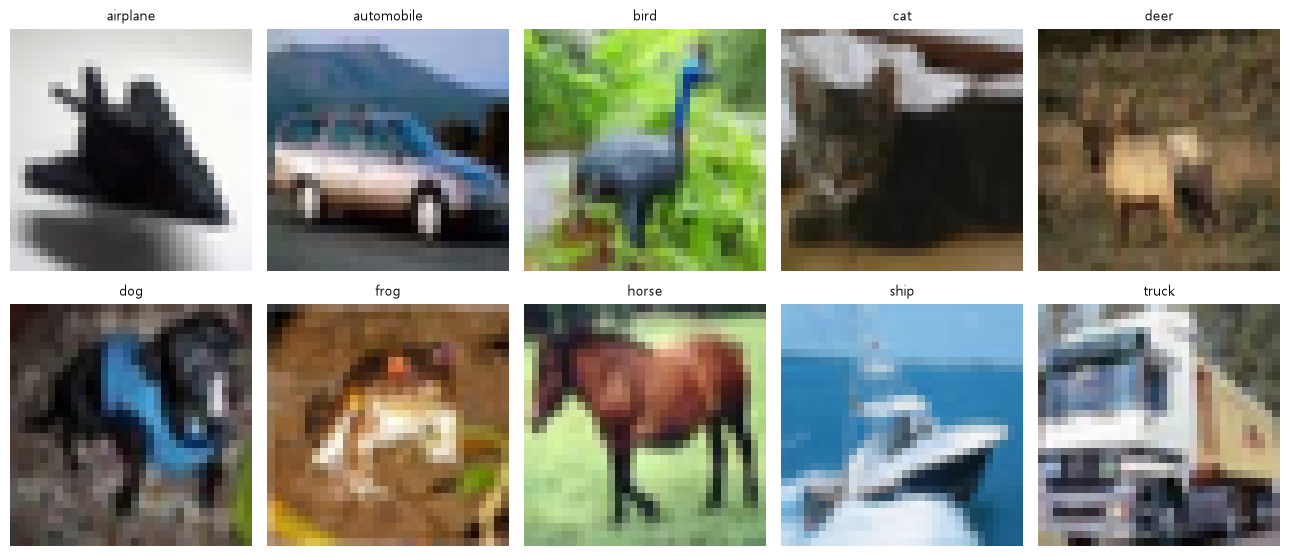

입력 사진 한 장 · 정답 10개 이름 중 하나 · 예측도 같은 10개 중 하나
검증 종류별 장수 airplane:50 · automobile:50 · bird:50 · cat:50 · deer:50 · dog:50 · frog:50 · horse:50 · ship:50 · truck:50
한 이름만 계속 답할 때 정확도 10.0% · 어느 이름을 골라도 같음
아무 이름이나 고를 때 기대 정확도 10.0%


In [41]:
# ---------- 1-1 ----------
# 왜 · 종류마다 첫 사진을 보며 무엇을 맞히는 문제인지 먼저 이해하기 위해
one_per_class = [int(np.where(targets == c)[0][0]) for c in range(len(CLASSES))]  # 종류마다 첫 장
grid([raw[i][0] for i in one_per_class], CLASSES, rows=2)                         # 열 종류 한 장씩
print(f"입력 사진 한 장 · 정답 {len(CLASSES)}개 이름 중 하나 · "                  # 문제 정의 한 줄
      f"예측도 같은 {len(CLASSES)}개 중 하나")


# ---------- 1-2 ----------
# 왜 · 가장 많은 종류만 찍어도 몇 %인지 기준선을 정하기 위해
va_y = targets[va_idx]                                                 # 검증 정답
counts = np.bincount(va_y, minlength=len(CLASSES))                     # 종류별 장수
top = int(counts.argmax())                                             # 가장 많은 종류
const_acc = counts[top] / len(va_y)                                    # 그 이름만 계속 답할 때
print("검증 종류별 장수 " + " · ".join(f"{n}:{c}" for n, c in zip(CLASSES, counts)))  # 고름
print(f"한 이름만 계속 답할 때 정확도 {const_acc * 100:.1f}% · 어느 이름을 골라도 같음")  # 기준선
print(f"아무 이름이나 고를 때 기대 정확도 {100 / len(CLASSES):.1f}%")  # 무작위 기준

**실행 흐름**

1. 2-1 텐서 묶음 · 학습 전 정확도
2. 2-2 3에폭 학습

In [42]:
# ---------- 2-1 ----------
# 왜 · 여러 장을 모델이 받는 (N, C, H, W) 텐서 묶음으로 바꾸기 위해
def to_tensor(idx):                                   # 번호 목록 → 사진 묶음 텐서 · 정답 텐서
    X = torch.stack([TF.to_tensor(raw[int(i)][0]) for i in idx])  # (N, 3, 32, 32) · 0~1
    y = torch.tensor(targets[idx], dtype=torch.long)  # 정답 번호
    return X, y                                       # 묶음 · 정답


# 왜 · 학습 · 검증 묶음을 한 번만 만들어 두고 뒤에서 다시 쓰기 위해
Xtr, ytr = to_tensor(tr_idx)                                      # 학습 1000장
Xva, yva = to_tensor(va_idx)                                      # 검증 500장
small = nn.Sequential(  # 합성곱 2번 · 줄이기 2번 · 점수 10개
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 → 16
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16 → 8
    nn.Flatten(), nn.Linear(32 * 8 * 8, len(CLASSES)),            # 펴서 점수
)


# 왜 · 모든 비교가 같은 평가 방법을 쓰게 하기 위해
def accuracy(model, X, y):                                      # 학습 없이 정확도만
    model.eval()                                                # 평가 모드
    with torch.no_grad():                                       # 기울기 기록 안 함
        return (model(X).argmax(1) == y).float().mean().item()  # 맞힌 비율


# 왜 · 학습 전 점수를 기록해 학습 효과를 비교할 출발점을 두기 위해
acc0 = accuracy(small, Xva, yva)                                                 # 학습 전
print(f"학습 전 검증 정확도 {acc0 * 100:.1f}%")                                  # 출발점
print(f"입력 묶음 모양 {tuple(Xtr.shape)} · 정답 묶음 모양 {tuple(ytr.shape)}")  # 모양


# ---------- 2-2 ----------
# 왜 · 짧은 학습으로도 기준선을 넘는지 확인하기 위해
opt = torch.optim.Adam(small.parameters(), lr=1e-3)                         # 한 걸음 크기 0.001
lossf = nn.CrossEntropyLoss()                                               # 손실 (점수를 받음)
hist = []                                                                   # 에폭별 검증 정확도
t0 = time.time()                                                            # 시작 시각
for ep in range(1, 4):                                                      # 3에폭
    small.train()                                                           # 학습 모드
    perm = torch.randperm(len(Xtr))                                         # 섞기
    for i in range(0, len(Xtr), 32):                                        # 32장씩
        b = perm[i:i + 32]                                                  # 이번 묶음 번호
        opt.zero_grad()                                                     # 지난 기울기 지우기
        lossf(small(Xtr[b]), ytr[b]).backward()                             # 예측 → 손실 → 기울기
        opt.step()                                                          # 한 걸음
    a = accuracy(small, Xva, yva)                                           # 검증
    hist.append(a)                                                          # 기록
    print(f"epoch {ep} 뒤 검증 정확도 {a * 100:.1f}%")                      # 에폭마다
took = time.time() - t0  # 걸린 시간 (원본은 출력 · 실행마다 달라 여기서는 아래 줄만)
print(f"3에폭 학습 끝 · 1분 안에 끝났나 {took < 60}")                       # CPU에서도 1분이면 충분
print(f"단순 기준 {const_acc * 100:.1f}% · 학습 뒤 {hist[-1] * 100:.1f}%")  # 기준선과 비교

학습 전 검증 정확도 8.4%


입력 묶음 모양 (1000, 3, 32, 32) · 정답 묶음 모양 (1000,)


epoch 1 뒤 검증 정확도 22.0%


epoch 2 뒤 검증 정확도 28.4%


epoch 3 뒤 검증 정확도 32.4%
3에폭 학습 끝 · 1분 안에 끝났나 True
단순 기준 10.0% · 학습 뒤 32.4%


**실행 흐름**

1. 2-3 틀린 사진 보기

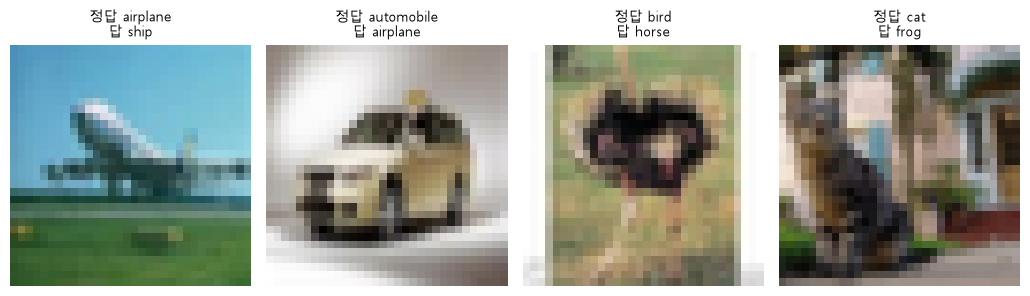

틀린 장수 338 / 500


In [43]:
# ---------- 2-3 ----------
small.eval()                                                 # 평가 모드
with torch.no_grad():                                        # 기울기 없음
    pred = small(Xva).argmax(1)                              # 검증 답
# 왜 · 틀린 사진을 정답 종류마다 한 장씩만 골라 다양한 실수를 보기 위해
bad, seen = [], set()                                        # 틀린 사진 · 이미 고른 정답 종류
for i in (pred != yva).nonzero().ravel().tolist():           # 틀린 사진 번호 (검증셋이 종류 순)
    if int(yva[i]) not in seen:                              # 종류마다 한 장만
        bad.append(i)                                        # 고름
        seen.add(int(yva[i]))                                # 그 종류 표시
    if len(bad) == 4:                                        # 네 장이면
        break                                                # 끝
grid([raw[int(va_idx[i])][0] for i in bad],                  # 틀린 네 장
     [f"정답 {CLASSES[yva[i]]}\n답 {CLASSES[pred[i]]}" for i in bad])
print(f"틀린 장수 {int((pred != yva).sum())} / {len(yva)}")  # 전체 틀림

**실행 흐름**

1. 3-1 크기와 값
2. 3-2 ~ 3-5 채널 · 회색조 · 밝기 · 해상도

한 장 크기 32×32 · 채널 3 · 정답 bird


왼쪽 위 3×3 칸의 빨강 값
[[159 159 145]
 [167 162 153]
 [168 167 169]]
값 타입 uint8 · 가장 작은 값 0 · 가장 큰 값 191
한 장에 들어 있는 숫자 3072개


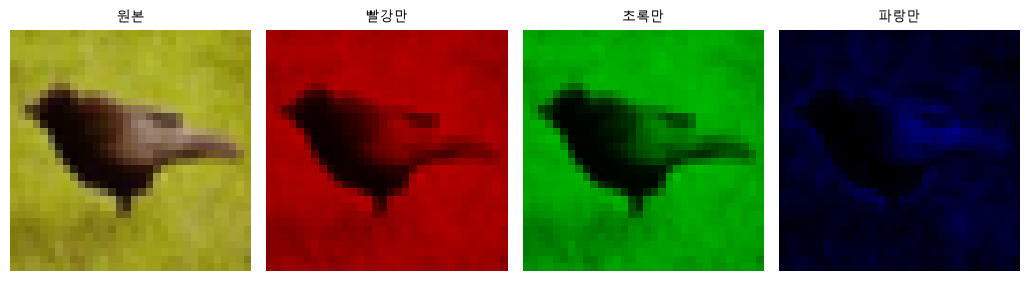

채널별 평균 밝기 — R 140.6 · G 135.0 · B 36.8


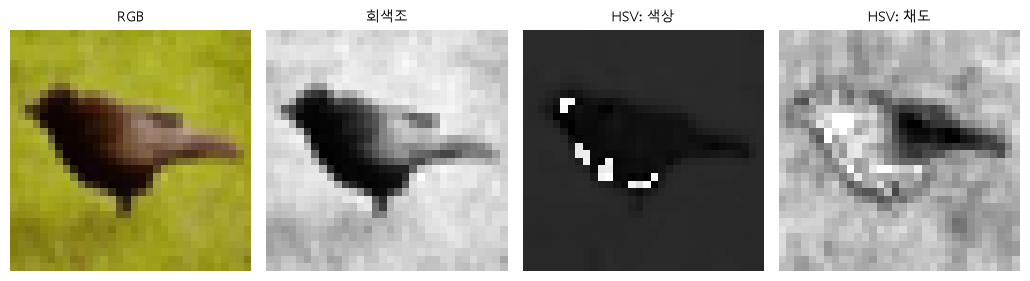

회색조 한 장 크기 (32, 32) · 채널이 사라짐


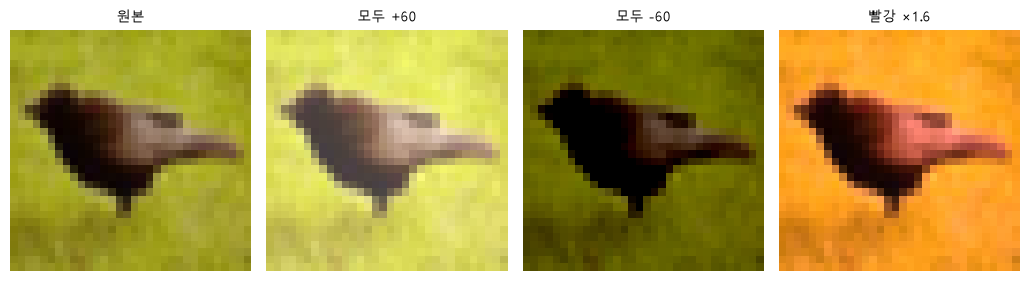

평균 밝기 — 원본 104.1 · 올림 164.1 · 내림 55.2
모든 칸에 같은 수를 더하면 밝기가 통째로 옮겨감 · 한 채널만 키우면 색이 기욺


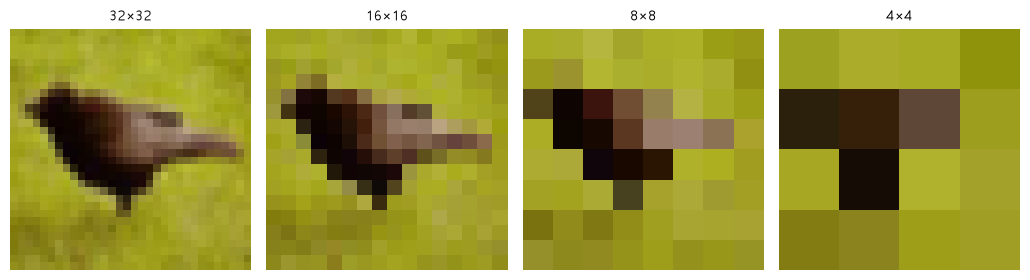

칸 수 32×32=3072개 · 16×16=768개 · 8×8=192개 · 4×4=48개
4×4로 줄이면 숫자가 3072개에서 48개로 줄어듦


In [44]:
# ---------- 3-1 ----------
# 왜 · 사진 한 장이 실제로는 숫자 배열이라는 것을 모양 · 값으로 확인하기 위해
img = raw[SHOW][0]                                    # 따라다닐 한 장 (PIL)
arr = np.array(img)                                   # (H, W, C) 배열
print(f"한 장 크기 {arr.shape[0]}×{arr.shape[1]} · "  # 세로 · 가로 · 채널 · 정답
      f"채널 {arr.shape[2]} · 정답 {CLASSES[targets[SHOW]]}")
print(f"왼쪽 위 3×3 칸의 빨강 값\n{arr[:3, :3, 0]}")  # 빨강 채널 일부
print(f"값 타입 {arr.dtype} · 가장 작은 값 {arr.min()} · 가장 큰 값 {arr.max()}")  # uint8 0~255
print(f"한 장에 들어 있는 숫자 {arr.size}개")         # 32 × 32 × 3


# ---------- 3-2 ----------
# 왜 · 원본을 지키면서 채널 하나만 남겨 색 정보를 나눠 보기 위해
r = arr.copy()                                                # 빨강만 남길 복사본
r[:, :, 1:] = 0                                               # 초록 · 파랑 끄기
g = arr.copy()                                                # 초록만
g[:, :, [0, 2]] = 0                                           # 빨강 · 파랑 끄기
b = arr.copy()                                                # 파랑만
b[:, :, :2] = 0                                               # 빨강 · 초록 끄기
grid([arr, r, g, b], ["원본", "빨강만", "초록만", "파랑만"])  # 네 장
# 어떤 색이 많은가
print(f"채널별 평균 밝기 — R {arr[:, :, 0].mean():.1f} · G {arr[:, :, 1].mean():.1f}"
      f" · B {arr[:, :, 2].mean():.1f}")


# ---------- 3-3 ----------
# 왜 · 회색조 · HSV로 바꾸면 무엇이 남고 무엇이 사라지는지 비교하기 위해
gray = TF.to_grayscale(img)                                         # 회색조 (채널 1)
hsv = np.array(img.convert("HSV"))                                  # 색상 · 채도 · 명도
# 원본 · 회색조 · 색상 · 채도
grid([img, gray, hsv[:, :, 0], hsv[:, :, 1]], ["RGB", "회색조", "HSV: 색상", "HSV: 채도"])
print(f"회색조 한 장 크기 {np.array(gray).shape} · 채널이 사라짐")  # (32, 32)


# ---------- 3-4 ----------
# 왜 · uint8 넘침을 막으려고 큰 자료형으로 계산한 뒤 0~255로 자르기 위해
bright = np.clip(arr.astype(np.int16) + 60, 0, 255).astype(np.uint8)  # 모든 칸 +60
red_up = arr.copy().astype(np.int16)                                  # 빨강만 키울 복사본
red_up[:, :, 0] = np.clip(red_up[:, :, 0] * 1.6, 0, 255)              # 빨강 ×1.6
half = np.clip(arr.astype(np.int16) - 60, 0, 255).astype(np.uint8)    # 모든 칸 -60
# 네 장 비교
grid([arr, bright, half, red_up.astype(np.uint8)], ["원본", "모두 +60", "모두 -60", "빨강 ×1.6"])
print(f"평균 밝기 — 원본 {arr.mean():.1f} · "                         # +60 · -60 효과
      f"올림 {bright.mean():.1f} · 내림 {half.mean():.1f}")
print("모든 칸에 같은 수를 더하면 밝기가 통째로 옮겨감 · 한 채널만 키우면 색이 기욺")  # 결론


# ---------- 3-5 ----------
# 왜 · 해상도를 줄일 때 어느 크기부터 정보가 사라지는지 보기 위해
steps = [32, 16, 8, 4]                                                    # 줄일 칸 수
shrunk = [TF.resize(TF.resize(img, [k, k], interpolation=NEAREST), [128, 128],  # 줄였다가 크게
                    interpolation=NEAREST) for k in steps]
grid(shrunk, [f"{k}×{k}" for k in steps])                                 # 같은 크기로 보여 줌
print("칸 수 " + " · ".join(f"{k}×{k}={k * k * 3}개" for k in steps))     # 숫자 개수
print(f"4×4로 줄이면 숫자가 {32 * 32 * 3}개에서 {4 * 4 * 3}개로 줄어듦")  # 정보량

**실행 흐름**

1. 4-1 HWC → CHW → NCHW
2. 4-2 틀리면
3. 4-3 · 4-4 to_tensor 세 단계 · 에러 읽기

넘파이 배열 HWC (32, 32, 3) · 값 uint8 0~191
텐서 CHW (3, 32, 32) · 값 torch.float32 0.00~0.75
배치 NCHW (1, 3, 32, 32) · 맨 앞 숫자가 장수
학습 묶음 한 배치 모양 (32, 3, 32, 32)


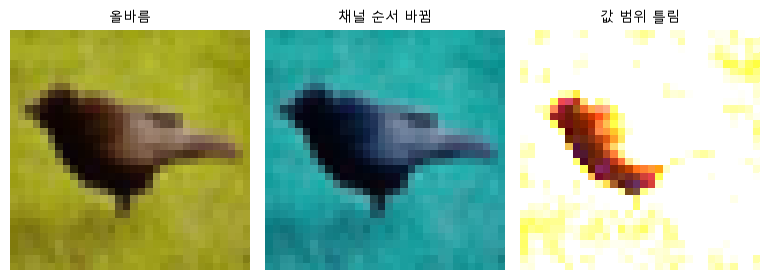

배치 축 없이 넣으면 → RuntimeError
배치 축을 붙이면 → 출력 모양 (1, 10)
1) 읽기       (32, 32, 3) · uint8 · 0~191
2) 축 옮기기   (3, 32, 32) · uint8 · 0~191
3) 실수로 나누기 (3, 32, 32) · float32 · 0.00~0.75
to_tensor 한 줄이 이 셋을 한 번에 함 — 결과가 같은가 True


에러 칸 첫 줄  → Traceback (most recent call last):
가운데 줄 수   → 18 줄 (처음엔 건너뜀)
맨 아래 줄     → RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x64 and 2048x10)


In [45]:
# 왜 · 에러 메시지 전체를 문자열로 받아 읽는 순서를 연습하기 위해
import traceback  # 오류 메시지 전체를 문자열로


# ---------- 4-1 ----------
# 왜 · 사진 배열(HWC)이 모델 입력(CHW · NCHW)으로 바뀌는 과정을 따라가기 위해
hwc = np.array(img)                                          # 넘파이 · (H, W, C) · uint8
chw = TF.to_tensor(img)                                      # 텐서 · (C, H, W) · float 0~1
nchw = chw.unsqueeze(0)                                      # 맨 앞에 장수 축
print(f"넘파이 배열 HWC {hwc.shape} · 값 {hwc.dtype} {hwc.min()}~{hwc.max()}")  # 사진 파일 그대로
print(f"텐서 CHW {tuple(chw.shape)} · "                      # 모델 쪽 약속
      f"값 {chw.dtype} {chw.min():.2f}~{chw.max():.2f}")
print(f"배치 NCHW {tuple(nchw.shape)} · 맨 앞 숫자가 장수")  # 모델은 묶음을 받음
print(f"학습 묶음 한 배치 모양 {tuple(Xtr[:32].shape)}")     # 32장


# ---------- 4-2 ----------
# 왜 · 축 · 범위 · 채널 순서를 틀리면 그림이 어떻게 망가지는지 보기 위해
wrong_axis = chw.permute(1, 2, 0).numpy()[:, :, [2, 1, 0]]         # 채널 순서를 뒤집음 (RGB → BGR)
wrong_scale = np.clip(hwc.astype(np.float32) / 255 * 8, 0, 1)      # 값 범위를 8배로
grid([hwc, wrong_axis, wrong_scale], ["올바름", "채널 순서 바뀜", "값 범위 틀림"])  # 세 장
try:                                                               # 배치 축 없이 넣기
    small(chw)                                                     # (3, 32, 32)
except Exception as e:                                             # 오류를 잡아 이름만
    print(f"배치 축 없이 넣으면 → {type(e).__name__}")             # 어떤 오류인가
print(f"배치 축을 붙이면 → 출력 모양 {tuple(small(nchw).shape)}")  # (1, 10)


# ---------- 4-3 ----------
# 왜 · to_tensor 한 줄이 하는 세 단계를 직접 나눠 결과가 같은지 검증하기 위해
step1 = np.array(img)                                                  # 1) 읽기 (H, W, C) · uint8
step2 = step1.transpose(2, 0, 1)                                       # 2) 축 옮기기 (C, H, W)
step3 = step2.astype(np.float32) / 255                                 # 3) 실수로 바꿔 255로 나누기
print(f"1) 읽기       {step1.shape} · {step1.dtype} · {step1.min()}~{step1.max()}")  # 원래
print(f"2) 축 옮기기   {step2.shape} · {step2.dtype} · {step2.min()}~{step2.max()}")  # 값은 그대로
print(f"3) 실수로 나누기 {step3.shape} · {step3.dtype} · "             # 0~1
      f"{step3.min():.2f}~{step3.max():.2f}")
same = np.allclose(step3, TF.to_tensor(img).numpy())                   # to_tensor 결과와 같은가
print(f"to_tensor 한 줄이 이 셋을 한 번에 함 — 결과가 같은가 {same}")  # True


# ---------- 4-4 ----------

try:                                                             # 일부러 배치 축 없이
    small(chw)                                                   # 오류
except Exception:                                                # 잡아서
    lines = traceback.format_exc().strip().splitlines()          # 줄 목록
print("에러 칸 첫 줄  →", lines[0][:70])                         # Traceback 시작
print("가운데 줄 수   →", len(lines) - 2, "줄 (처음엔 건너뜀)")  # 라이브러리 안쪽 경로
print("맨 아래 줄     →", lines[-1][:110])                       # 오류 종류와 이유 = 먼저 읽을 줄

**실행 흐름**

1. 5-1 실제 크기
2. 5-2 · 5-3 늘리기 · 자르기
3. 5-4 가운데 10칸

한 장 크기 32×32 · 채널 3
값 타입 uint8 · 가장 작은 값 0 · 가장 큰 값 191
한 장에 들어 있는 숫자 3072개 · 정답 bird


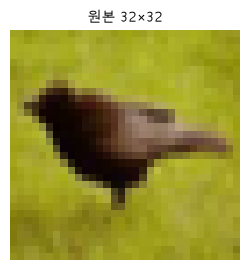

늘린 크기 224×224 · 한 변이 7배
늘린 뒤 서로 다른 색 개수 — 최근접 976개 · 선형 18390개
원본의 서로 다른 색 개수 976개


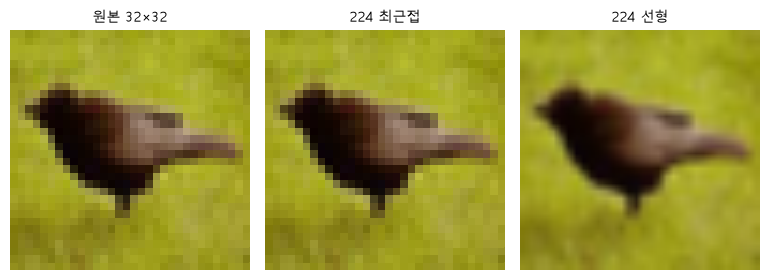

가운데만 남긴 크기 16×16 · 버린 픽셀 768개
늘리기는 버린 픽셀 0개


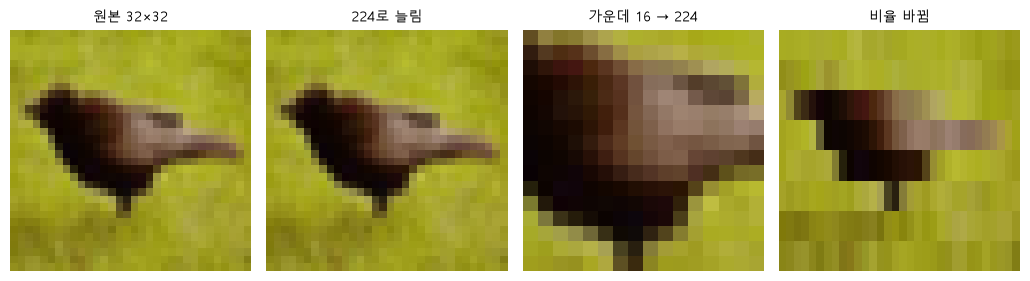

가운데 10×10만 남김 · 원본의 10% 넓이


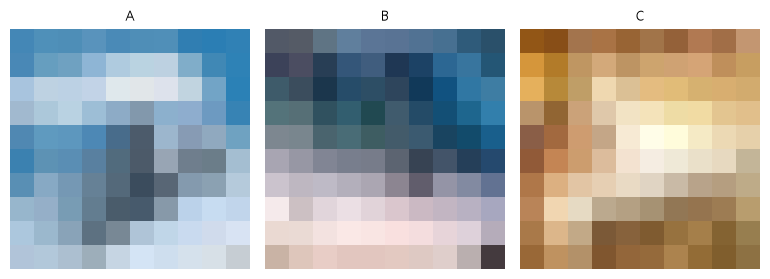

정답 A=ship · B=automobile · C=frog


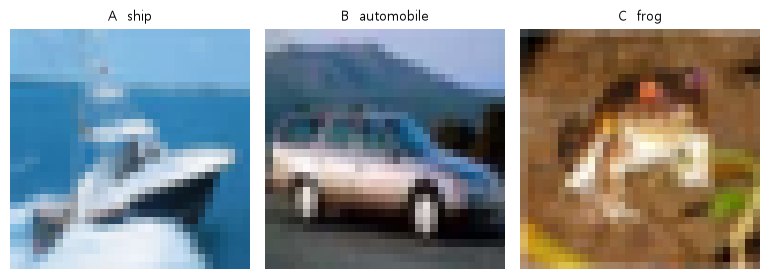

In [46]:
# ---------- 5-1 ----------
# 왜 · 화면에서 크게 보이는 그림의 실제 크기를 숫자로 확인하기 위해
print(f"한 장 크기 {arr.shape[0]}×{arr.shape[1]} · 채널 {arr.shape[2]}")       # 실제 크기
print(f"값 타입 {arr.dtype} · 가장 작은 값 {arr.min()} · 가장 큰 값 {arr.max()}")  # 값
print(f"한 장에 들어 있는 숫자 {arr.size}개 · 정답 {CLASSES[targets[SHOW]]}")  # 숫자 개수
grid([arr], [f"원본 {arr.shape[0]}×{arr.shape[1]}"])                           # 화면에는 크게 보임


# ---------- 5-2 ----------
# 왜 · 224로 늘릴 때 채우는 방법에 따라 그림이 어떻게 달라지는지 비교하기 위해
src = img                                                             # 원본 32×32
side = src.size[0]                                                    # 한 변 32
up_near = TF.resize(src, [224, 224], interpolation=NEAREST)           # 최근접으로 늘림
up_lin = TF.resize(src, [224, 224], interpolation=BILINEAR)           # 선형으로 늘림
print(f"늘린 크기 {up_near.size[0]}×{up_near.size[1]} · 한 변이 {up_near.size[0] // side}배")  # 7배
print(f"늘린 뒤 서로 다른 색 개수 — 최근접 {n_colors(up_near)}개 · "  # 섞으면 중간색이 생김
      f"선형 {n_colors(up_lin)}개")
print(f"원본의 서로 다른 색 개수 {n_colors(src)}개")                  # 비교 기준
grid([src, up_near, up_lin], [f"원본 {side}×{side}", "224 최근접", "224 선형"])  # 세 장


# ---------- 5-3 ----------
# 왜 · 잘라내기 · 늘리기 · 비율 바꾸기가 각각 무엇을 바꾸는지 비교하기 위해
keep, squash_h = 16, 8                                       # 가운데 남길 칸 · 세로로 누를 칸
resized = TF.resize(src, [224, 224], interpolation=NEAREST)  # 그대로 늘림
# 잘라 늘림
cropped = TF.resize(TF.center_crop(src, [keep, keep]), [224, 224], interpolation=NEAREST)
# 세로로 눌렀다가 늘림 = 비율 바뀜
squashed = TF.resize(TF.resize(src, [squash_h, side], interpolation=NEAREST), [224, 224],
                     interpolation=NEAREST)
print(f"가운데만 남긴 크기 {keep}×{keep} · 버린 픽셀 {side * side - keep * keep}개")  # 잃은 정보
print(f"늘리기는 버린 픽셀 {side * side - side * side}개")   # 0
grid([src, resized, cropped, squashed],                      # 네 장
     [f"원본 {side}×{side}", "224로 늘림", f"가운데 {keep} → 224", "비율 바뀜"])


# ---------- 5-4 ----------
# 왜 · 가운데 일부만 보고도 맞힐 수 있는지 확인하기 위해
tiny = 10                                # 가운데 10×10만 남김
# 세 장의 가운데 10칸만 크게
tests = [TF.resize(TF.center_crop(raw[i][0], [tiny, tiny]), [224, 224], interpolation=NEAREST)
         for i in PICK]
print(f"가운데 {tiny}×{tiny}만 남김 · "  # 10%
      f"원본의 {round(tiny * tiny / (side * side) * 100)}% 넓이")
grid(tests, ["A", "B", "C"])             # 무엇인지 맞혀 보기
print("정답 " + " · ".join(f"{n}={CLASSES[raw[i][1]]}" for n, i in zip("ABC", PICK)))  # 정답
grid([raw[i][0] for i in PICK], [f"{n}  {CLASSES[raw[i][1]]}" for n, i in zip("ABC", PICK)])  # 원본

**실행 흐름**

1. 6-1 0–1로 줄이고 평균 · 표준편차로 옮기기

In [47]:
# ---------- 6-1 ----------
# 왜 · 값의 범위를 0–1로 줄인 뒤 평균 · 표준편차로 옮기는 과정을 확인하기 위해
zero_one = TF.to_tensor(img)                                                   # 0~1로 줄임
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet 채널별 평균 · 표준편차
normed = TF.normalize(zero_one.clone(), MEAN, STD)  # (x - 평균) / 표준편차 · 채널마다
print(f"원래 값 {hwc.min()}~{hwc.max()} · 평균 {hwc.mean():.1f}")              # 0~255
print(f"0–1로 줄인 뒤 {zero_one.min():.2f}~{zero_one.max():.2f} · "            # ÷ 255 결과
      f"평균 {zero_one.mean():.2f}")
print(f"정규화 뒤 {normed.min():.2f}~{normed.max():.2f} · 평균 {normed.mean():.2f}")  # 0 근처
print(f"정규화는 채널마다 다른 값을 씀 — 평균 {MEAN} · 표준편차 {STD}")        # 세 쌍
half_t = torch.full((3, 1, 1), 0.5)                                            # 세 채널 모두 0.5
out = [round(v, 3) for v in TF.normalize(half_t, MEAN, STD).ravel().tolist()]  # 정규화 결과
print(f"세 채널이 모두 0.50이어도 정규화 뒤에는 {out}")                        # 채널마다 다름

원래 값 0~191 · 평균 104.1
0–1로 줄인 뒤 0.00~0.75 · 평균 0.41
정규화 뒤 -2.04~1.27 · 평균 -0.18
정규화는 채널마다 다른 값을 씀 — 평균 [0.485, 0.456, 0.406] · 표준편차 [0.229, 0.224, 0.225]
세 채널이 모두 0.50이어도 정규화 뒤에는 [0.066, 0.196, 0.418]


**실행 흐름**

1. 7-1 커널
2. 7-2 아홉 칸 합
3. 7-3 잡음 · 경계

평탄한 자리 — 가운데 값 6 · 흐리기 뒤 6 · 경계 커널 값 -3
경계 자리 — 가운데 값 89 · 흐리기 뒤 83 · 경계 커널 값 56
흐리기는 이웃의 평균으로 바꿈 · 경계 커널은 이웃과 얼마나 다른지를 냄
흐리기 창 — 아홉 칸 합 1 · 평탄한 자리 6 · 경계 자리 83
경계 창 — 아홉 칸 합 0 · 평탄한 자리 -3 · 경계 자리 56
또렷하게 창 — 아홉 칸 합 1 · 평탄한 자리 6 · 경계 자리 106
아홉 칸 합이 1이면 밝기가 유지됨 · 0이면 평탄한 자리가 0에 가까워짐


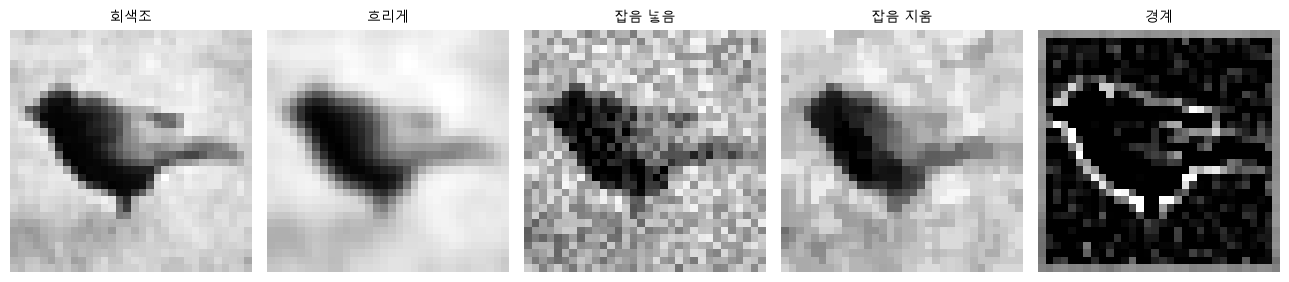

잡음을 넣은 뒤 원본과의 평균 차이 19.7
잡음을 지운 뒤 원본과의 평균 차이 11.7


In [48]:
# 왜 · 커널이 칸마다 하는 계산을 반복문 없이 직접 재현하기 위해
from numpy.lib.stride_tricks import sliding_window_view  # 3×3 창을 한 번에
# 왜 · 잡음 제거 · 경계 찾기 필터를 실제로 써 보기 위해
from PIL import Image as PILImage                        # 배열 → PIL 사진
from PIL import ImageFilter                              # 흐리기 · 중앙값 · 경계 필터


# ---------- 7-1 ----------

g_arr = np.array(TF.to_grayscale(img), dtype=np.float32)          # 회색조 32×32
wins = sliding_window_view(g_arr, (3, 3))                         # (30, 30, 3, 3) · 자리마다 3×3 창
spread = wins.std(axis=(2, 3))                                    # 창 안 값이 얼마나 다른가
fy, fx = np.unravel_index(spread.argmin(), spread.shape)          # 가장 평탄한 자리
ey, ex = np.unravel_index(spread.argmax(), spread.shape)          # 가장 경계인 자리
flat, edge = wins[fy, fx], wins[ey, ex]                           # 두 창
blur_k = np.ones((3, 3), dtype=np.float32) / 9                    # 흐리기 커널 (평균)
edge_k = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=np.float32)  # 경계 커널
for name, patch in (("평탄한 자리", flat), ("경계 자리", edge)):  # 두 자리
    # 두 커널 결과 비교
    print(f"{name} — 가운데 값 {patch[1, 1]:.0f} · 흐리기 뒤 {(patch * blur_k).sum():.0f}"
          f" · 경계 커널 값 {(patch * edge_k).sum():.0f}")
print("흐리기는 이웃의 평균으로 바꿈 · 경계 커널은 이웃과 얼마나 다른지를 냄")  # 읽는 법


# ---------- 7-2 ----------
# 왜 · 커널 숫자의 합이 결과 밝기에 주는 영향을 확인하기 위해
sharp_k = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)             # 또렷하게
for name, k in (("흐리기", blur_k), ("경계", edge_k), ("또렷하게", sharp_k)):           # 커널 셋
    print(f"{name} 창 — 아홉 칸 합 {k.sum():.0f} · 평탄한 자리 {(flat * k).sum():.0f}"  # 합과 결과
          f" · 경계 자리 {(edge * k).sum():.0f}")
print("아홉 칸 합이 1이면 밝기가 유지됨 · 0이면 평탄한 자리가 0에 가까워짐")            # 규칙


# ---------- 7-3 ----------

g_img = TF.to_grayscale(img)                                              # 회색조 사진
noise = np.random.randint(-40, 41, (32, 32))                              # -40 ~ 40 잡음
# 0~255로 자름
noisy_arr = np.clip(np.array(g_img).astype(np.int16) + noise, 0, 255).astype(np.uint8)
noisy = PILImage.fromarray(noisy_arr)                                     # 잡음 넣은 사진
denoised = noisy.filter(ImageFilter.MedianFilter(3))  # 3×3 중앙값으로 잡음 지우기
edges = g_img.filter(ImageFilter.FIND_EDGES)                              # 경계 찾기
grid([g_img, g_img.filter(ImageFilter.GaussianBlur(1)), noisy, denoised, edges],  # 처리 다섯 가지
     ["회색조", "흐리게", "잡음 넣음", "잡음 지움", "경계"])
a0, a1 = np.array(g_img).astype(float), np.array(noisy).astype(float)     # 비교용 실수 배열
print(f"잡음을 넣은 뒤 원본과의 평균 차이 {np.abs(a0 - a1).mean():.1f}")  # 크게 벌어짐
a2 = np.array(denoised).astype(float)                                     # 지운 사진
print(f"잡음을 지운 뒤 원본과의 평균 차이 {np.abs(a0 - a2).mean():.1f}")  # 줄었지만 0은 아님

**실행 흐름**

1. 7-4 한 줄 단면
2. 7-5 흐리기 단계

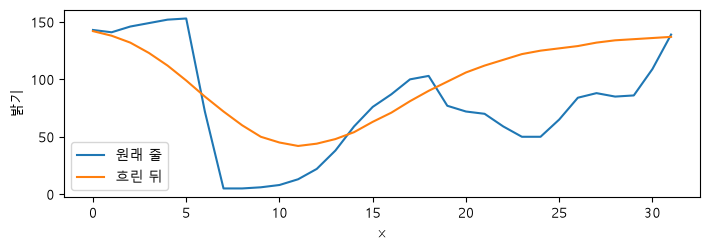

이웃한 칸끼리의 평균 차이 — 원본 13.2 · 흐린 뒤 6.3


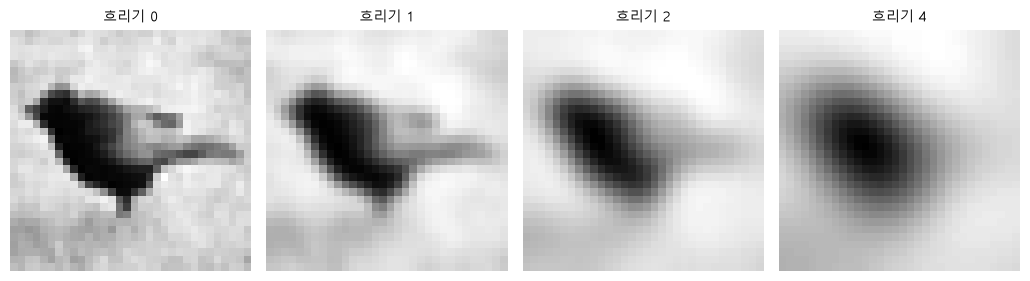

이웃한 칸끼리의 평균 차이 흐리기 0:13.2 · 흐리기 1:9.1 · 흐리기 2:7.6 · 흐리기 4:4.8


In [49]:
# ---------- 7-4 ----------
# 왜 · 한 줄 단면으로 흐리기가 경계를 어떻게 바꾸는지 숫자로 보기 위해
row = np.array(g_img, dtype=float)[16]      # 가운데 한 줄 (32칸)
row_blur = np.array(g_img.filter(ImageFilter.GaussianBlur(3)), dtype=float)[16]  # 흐린 뒤 같은 줄
fig, ax = plt.subplots(figsize=(7.2, 2.6))  # 단면 그림
ax.plot(row, label="원래 줄")               # 들쭉날쭉
ax.plot(row_blur, label="흐린 뒤")          # 매끈
ax.set_xlabel("x")                          # 가로 위치
ax.set_ylabel("밝기")                       # 값
ax.legend()                                 # 범례
fig.tight_layout()                          # 정리
plt.show()                                  # 그리기
step = np.abs(np.diff(row)).mean()          # 이웃 칸끼리 평균 차이
step_b = np.abs(np.diff(row_blur)).mean()   # 흐린 뒤
print(f"이웃한 칸끼리의 평균 차이 — 원본 {step:.1f} · 흐린 뒤 {step_b:.1f}")  # 경계가 무뎌짐


# ---------- 7-5 ----------
# 왜 · 흐리기 세기에 따라 남는 정보가 어떻게 줄어드는지 비교하기 위해
levels = [0, 1, 2, 4]                                                     # 흐리기 세기 (0 = 원본)
# 세기별 흐린 사진
blurred = [g_img if r_ == 0 else g_img.filter(ImageFilter.GaussianBlur(r_)) for r_ in levels]
grid(blurred, [f"흐리기 {r_}" for r_ in levels])                          # 네 장
diffs = [np.abs(np.diff(np.array(b_, dtype=float)[16])).mean() for b_ in blurred]  # 단면 차이
txt = " · ".join(f"흐리기 {r_}:{d:.1f}" for r_, d in zip(levels, diffs))  # 단계별 값
print("이웃한 칸끼리의 평균 차이 " + txt)                                 # 세질수록 작아짐

**실행 흐름**

1. 8-1 크기 · 장수 · 겹침
2. 8-2 같은 종류 안의 다양함
3. 8-3 증강과 나누는 순서

표본 200장의 크기 종류 {(32, 32)} · 한 가지뿐임
학습 클래스별 장수 [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
검증 클래스별 장수 [50, 50, 50, 50, 50, 50, 50, 50, 50, 50]
학습과 검증이 겹치는 장수 0장
파일 이름 · 촬영 정보는 이 로더가 주지 않음 — 확인 못 함으로 남김


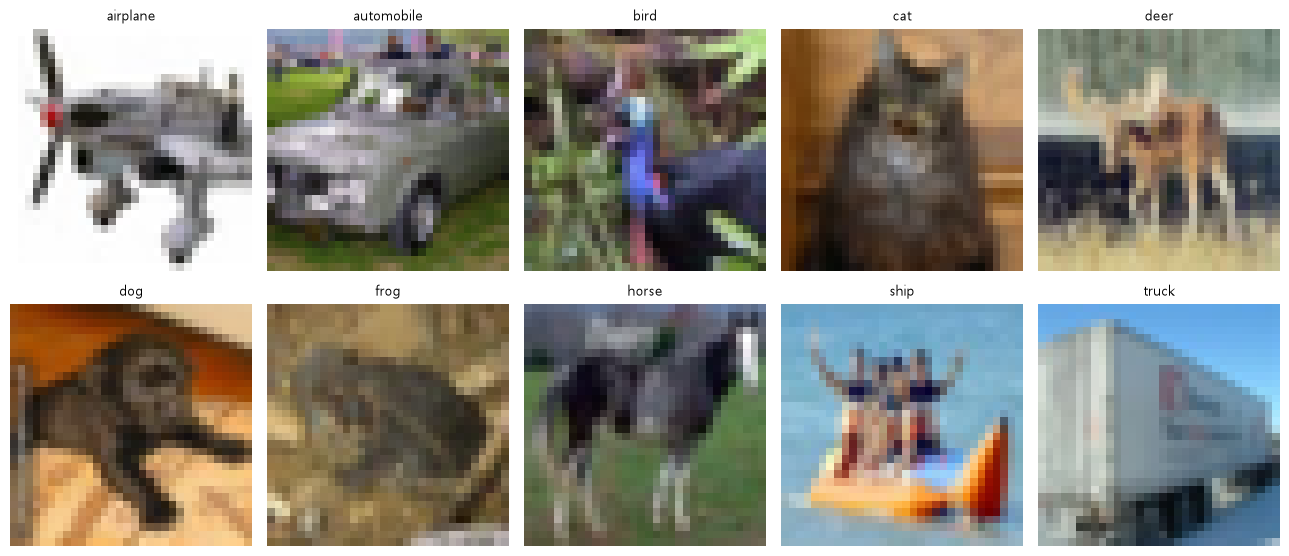

배경 · 각도 · 가림 정도는 장마다 다름 — 크기가 같다고 같은 조건은 아님


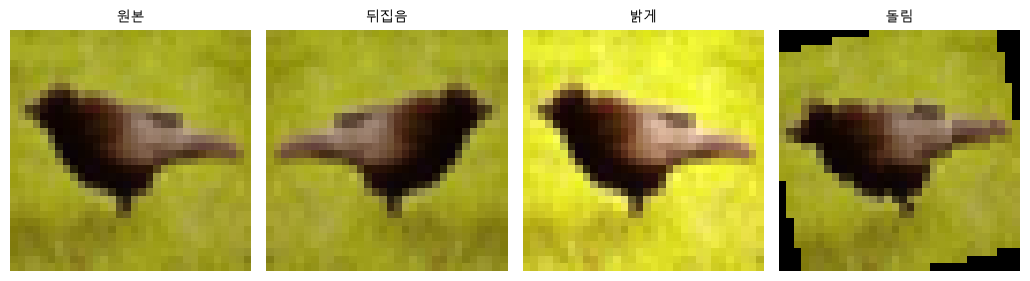

네 장은 서로 다른 파일처럼 보이지만 원본 한 장에서 나옴
먼저 만들고 나중에 나누면 → 같은 원본이 학습과 검증 양쪽에 들어감
먼저 나누고 학습 쪽에서만 만들면 → 검증은 본 적 없는 원본만 담음


In [50]:
# ---------- 8-1 ----------
# 왜 · 데이터의 크기 · 장수 · 겹침을 먼저 확인해 탐색 기록을 남기기 위해
sizes = {raw[int(i)][0].size for i in tr_idx[:200]}                         # 표본 200장의 크기 종류
print(f"표본 200장의 크기 종류 {sizes} · 한 가지뿐임")                      # 모두 32×32
print(f"학습 클래스별 장수 {np.bincount(targets[tr_idx]).tolist()}")        # 100씩
print(f"검증 클래스별 장수 {np.bincount(targets[va_idx]).tolist()}")        # 50씩
print(f"학습과 검증이 겹치는 장수 {len(set(tr_idx.tolist()) & set(va_idx.tolist()))}장")  # 0
print("파일 이름 · 촬영 정보는 이 로더가 주지 않음 — 확인 못 함으로 남김")  # 탐색 기록


# ---------- 8-2 ----------
# 왜 · 같은 종류 안에서도 생김새가 다양하다는 것을 확인하기 위해
some = [int(np.where(targets == c)[0][3]) for c in range(len(CLASSES))]  # 종류마다 네 번째 장
grid([raw[i][0] for i in some], CLASSES, rows=2)                         # 다양함 보기
print("배경 · 각도 · 가림 정도는 장마다 다름 — 크기가 같다고 같은 조건은 아님")  # 관찰


# ---------- 8-3 ----------
# 왜 · 증강과 데이터 나누기의 순서가 왜 중요한지 같은 사진으로 보기 위해
base = raw[SHOW][0]                                                                    # 원본 한 장
copies = [base, TF.hflip(base), TF.adjust_brightness(base, 1.4), TF.rotate(base, 12)]  # 변형 셋
grid(copies, ["원본", "뒤집음", "밝게", "돌림"])                                       # 네 장
print("네 장은 서로 다른 파일처럼 보이지만 원본 한 장에서 나옴")                       # 같은 뿌리
print("먼저 만들고 나중에 나누면 → 같은 원본이 학습과 검증 양쪽에 들어감")             # 누수
print("먼저 나누고 학습 쪽에서만 만들면 → 검증은 본 적 없는 원본만 담음")              # 올바른 순서

**실행 흐름**

1. 9-1 허용할 변환
2. 9-2 제외할 변환
3. 9-3 학습은 무작위 · 검증은 고정

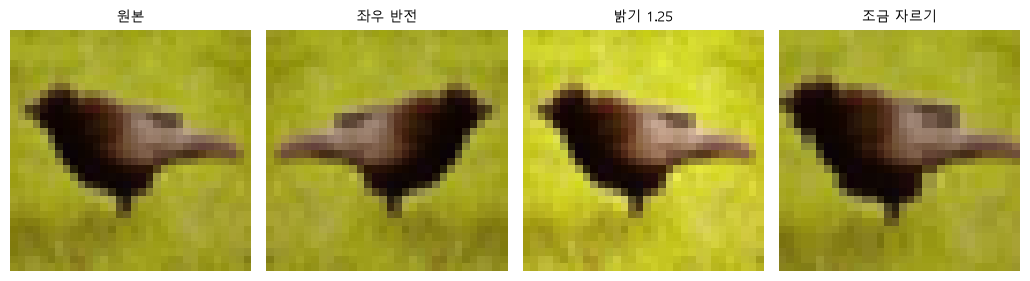

네 장 모두 정답 이름이 그대로임


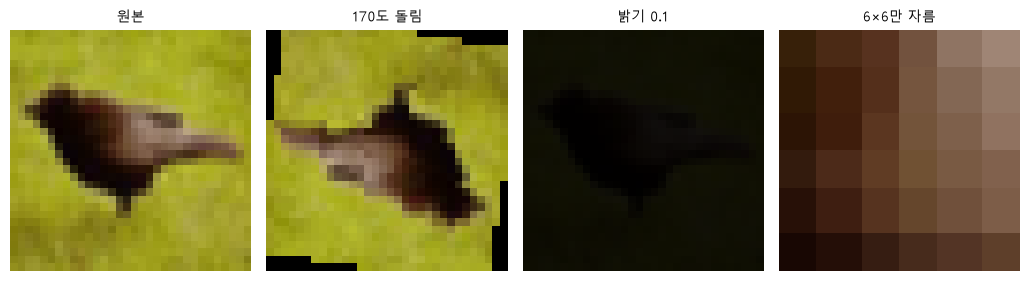

정답을 알아보기 어려워진 장이 있음 — 많이 넣을수록 좋은 것이 아님
학습 쪽 — 무작위 변환을 넣음 · 매번 다른 그림이 나옴
검증 쪽 — 무작위 변환을 넣지 않음 · 같은 그림이 나와야 점수를 비교할 수 있음
검증 전처리를 세 번 적용한 결과가 모두 같은가 True
학습 증강을 세 번 적용하면 서로 다른 그림 3가지


In [51]:
# ---------- 9-1 ----------
# 왜 · 정답이 그대로인 변환만 골라 허용 목록을 만들기 위해
ok = [base, TF.hflip(base), TF.adjust_brightness(base, 1.25),  # 허용할 변환
      TF.resized_crop(base, 2, 2, 28, 28, [32, 32], interpolation=NEAREST)]
grid(ok, ["원본", "좌우 반전", "밝기 1.25", "조금 자르기"])    # 네 장
print("네 장 모두 정답 이름이 그대로임")                       # 단서가 남음


# ---------- 9-2 ----------
# 왜 · 정답을 바꾸거나 정보를 지우는 변환을 빼야 하는 이유를 보기 위해
bad_aug = [base, TF.rotate(base, 170), TF.adjust_brightness(base, 0.1),     # 제외할 변환
           TF.resized_crop(base, 12, 12, 6, 6, [32, 32], interpolation=NEAREST)]
grid(bad_aug, ["원본", "170도 돌림", "밝기 0.1", "6×6만 자름"])             # 네 장
print("정답을 알아보기 어려워진 장이 있음 — 많이 넣을수록 좋은 것이 아님")  # 단서가 사라짐


# ---------- 9-3 ----------
# 왜 · 학습은 무작위로 · 검증은 고정으로 두는 이유를 확인하기 위해
print("학습 쪽 — 무작위 변환을 넣음 · 매번 다른 그림이 나옴")                 # 증강
print("검증 쪽 — 무작위 변환을 넣지 않음 · 같은 그림이 나와야 점수를 비교할 수 있음")  # 고정
same = all(np.array_equal(np.array(base), np.array(base)) for _ in range(3))  # 검증 전처리 세 번
# 무작위 세 번
diff = len({TF.rotate(base, int(np.random.randint(-15, 16))).tobytes() for _ in range(3)})
print(f"검증 전처리를 세 번 적용한 결과가 모두 같은가 {same}")                # True
print(f"학습 증강을 세 번 적용하면 서로 다른 그림 {diff}가지")                # 매번 다름

**실행 흐름**

1. 10-1 첫 실험 한 줄 설명
2. 10-2 정규화 하나만 바꿔 비교

In [52]:
# ---------- 10-1 ----------
# 첫 실험을 한 줄로 설명하기
# 왜 · 데이터 → 입력 → 예측 흐름을 한 줄로 설명할 수 있는지 확인하기 위해
# 일반 흐름
print("데이터 폴더 → 한 장 읽기 → 크기 맞추기 → 값 범위 맞추기 → 배치로 묶기 → 모델 → 예측")
# 우리 실습에 대입
print(f"우리 경우 → CIFAR-10 → {arr.shape[0]}×{arr.shape[1]} 그대로 → 0–1로 줄임"
      f" → {tuple(Xtr[:32].shape)} → 작은 CNN → {len(CLASSES)}개 중 하나")
print(f"지금까지의 점수 — 단순 기준 {const_acc * 100:.1f}% · "  # 정리
      f"3번 학습 뒤 {hist[-1] * 100:.1f}%")


# ---------- 10-2 ----------
# 왜 · 전처리 하나만 바꾸고 나머지는 같게 해 공정하게 비교하기 위해
def train_fresh(Xtr_, epochs=3):                    # 같은 조건으로 새로 학습 (입력만 바꿔 넣음)
    torch.manual_seed(42)                           # 같은 시작값 · 같은 섞기
    m = nn.Sequential(                              # 2장과 같은 모양
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 8 * 8, len(CLASSES)),
    )
    o = torch.optim.Adam(m.parameters(), lr=1e-3)   # 같은 학습률
    for _ in range(epochs):                         # 같은 에폭
        m.train()                                   # 학습 모드
        p = torch.randperm(len(Xtr_))               # 섞기
        for i in range(0, len(Xtr_), 32):           # 32장씩
            bb = p[i:i + 32]                        # 묶음
            o.zero_grad()                           # 지우기
            lossf(m(Xtr_[bb]), ytr[bb]).backward()  # 기울기
            o.step()                                # 한 걸음
    return m                                        # 학습된 모델


# 왜 · 정규화 유무만 다른 두 학습을 같은 조건에서 비교하기 위해
Xtr_norm = torch.stack([TF.normalize(x.clone(), MEAN, STD) for x in Xtr])  # 정규화한 학습 묶음
Xva_norm = torch.stack([TF.normalize(x.clone(), MEAN, STD) for x in Xva])  # 검증도 같은 변환
a_plain = accuracy(train_fresh(Xtr), Xva, yva)                             # 0–1만
a_norm = accuracy(train_fresh(Xtr_norm), Xva_norm, yva)                    # 정규화까지
print(f"0–1만 적용 검증 정확도 {a_plain * 100:.1f}%")                      # 비교 1
print(f"정규화까지 적용 검증 정확도 {a_norm * 100:.1f}%")                  # 비교 2
print("바꾼 조건은 전처리 하나 · 초기값 · 분할 · 학습량은 같음")           # 통제된 비교

데이터 폴더 → 한 장 읽기 → 크기 맞추기 → 값 범위 맞추기 → 배치로 묶기 → 모델 → 예측
우리 경우 → CIFAR-10 → 32×32 그대로 → 0–1로 줄임 → (32, 3, 32, 32) → 작은 CNN → 10개 중 하나
지금까지의 점수 — 단순 기준 10.0% · 3번 학습 뒤 32.4%


0–1만 적용 검증 정확도 32.4%
정규화까지 적용 검증 정확도 38.4%
바꾼 조건은 전처리 하나 · 초기값 · 분할 · 학습량은 같음


**실행 흐름**

1. 새 사진 한 장 처음부터 끝까지
2. 흐리기를 검증 전체에 넣어 점수 비교

In [53]:
# ---------- 11. 종합 실습 ----------
# 종합 실습 1 — 새 사진 한 장을 처음부터 끝까지 (읽기 → 크기 → 값 → 배치 → 모델 → 예측)
# 왜 · 새 사진도 같은 순서로 모델 입력까지 만들 수 있는지 확인하기 위해
# 학습 · 검증 밖의 말
new_i = int(np.where(targets == CLASSES.index("horse"))[0][PER_TRAIN + PER_VAL])
pil = raw[new_i][0]                 # ① 한 장 읽기 (PIL · 32×32)
x = TF.to_tensor(pil)               # ② 크기 그대로 · ③ 0~1 · (3, 32, 32)
xb = x.unsqueeze(0)                 # ④ 배치 축 (1, 3, 32, 32)
small.eval()                        # 평가 모드
with torch.no_grad():               # 예측만
    prob = small(xb).softmax(1)[0]  # ⑤ 모델 → 확률 10개
k3 = prob.topk(3)                   # 큰 세 종류
print(f"새 사진 {new_i}번 · 정답 {CLASSES[raw[new_i][1]]} · 입력 모양 {tuple(xb.shape)}")  # 확인
# 이름 확률
top = " · ".join(f"{CLASSES[int(c)]} {float(p):.2f}" for p, c in zip(k3.values, k3.indices))
print("예측 상위 3 — " + top)       # 확률이 큰 세 종류


# 종합 실습 2 — 이미지 처리 하나를 검증 사진 전체에 넣으면 점수는? (모델은 그대로)
# 왜 · 모델은 그대로 두고 입력 처리만 바꿀 때 점수가 어떻게 변하는지 보기 위해
def blur_all(X, radius):           # 검증 묶음 전체를 흐리게
    out = []                       # 흐린 사진들
    for x in X:                    # 한 장씩
        pil_ = TF.to_pil_image(x)  # 텐서 → PIL
        out.append(TF.to_tensor(pil_.filter(ImageFilter.GaussianBlur(radius))))  # 흐려서 다시 텐서
    return torch.stack(out)        # 묶음


for radius in (0, 1, 2):                                                           # 흐리기 세기
    Xb = Xva if radius == 0 else blur_all(Xva, radius)                             # 0이면 원본
    print(f"흐리기 {radius} → 검증 정확도 {accuracy(small, Xb, yva) * 100:.1f}%")  # 점수 변화

새 사진 1543번 · 정답 horse · 입력 모양 (1, 3, 32, 32)
예측 상위 3 — dog 0.27 · deer 0.18 · frog 0.15


흐리기 0 → 검증 정확도 32.4%


흐리기 1 → 검증 정확도 28.0%


흐리기 2 → 검증 정확도 25.2%
